Cell M5-1(markdown)|notebook 定位

### 05 | 風險 × 價值分群與挽留策略(M5)

**目的**:<br/>
把 M2 至 M4 找到並驗證過的風險訊號,轉成一張決策者能直接執行的表:<br/>
哪些客戶進挽留名單、對每一群客戶做什麼、預期能留住多少人、大約要花多少成本。<br/>
M2 找出了訊號並做了命中數分層,M3 確認訊號不是抽樣波動,M4 量化了規則(C3-b:旗標命中數分層)與模型的名單品質;本模組的工作是把「誰風險高」與「誰值得留」兩個維度交叉成分群矩陣,並把 M2 至 M4 留給本模組的八項決策全部定案。<br/>

**支持的決策**:<br/>
問題定義書決策 1(挽留資源應優先投放在哪些客群)與決策 3 的前半(提出可驗證的挽留方案;方案是否有效由 M6 的實驗設計驗證)。<br/>

**本模組的三個產出與各節 Roadmap**:<br/>
1. 風險 × 價值矩陣:<br/>
以 SQL 產出(sql/04_segment_matrix.sql [S1]),四層風險(命中 0／1／2／3+ 個旗標，流失率 1.3%／8.7%／36.7%／82.9%) × 三層價值(低、中、高價值層)共 12 格,每格有人數、流失率、流失人數、平均交易金額;再把這 12 格歸入「四個策略區」。<br/>
2. 每格一個挽留動作與效益粗估:<br/>
挽留動作對應「該格的風險訊號」,效益以「情境試算」呈現。
「情境試算」說明,詳參 M5-2 1.5 。<br/>
3. k-means 對照:<br/>
把「用 k-means 演算法分群的結果」與「規則式矩陣」並列,說明兩種分群方法各適合什麼情境、本案為什麼以規則式為主(決策日誌 [M5-0])。<br/>
本模組(M5)所稱「規則式」皆指:以分析者明確定義的條件分格。<br/>
本案的條件是「旗標命中數」(風險軸,四個旗標等權重)與「交易金額三分位」(價值軸)。<br/>

**各節 Roadmap(每一節的目標、做法與實務效果;各節結論的數字見第 8 節架構表)**:<br/>

| 節 | 目標 | 做法 | 實務效果 | 定案的待驗證事項 |
|---|---|---|---|---|
| 1 | 說明本模組用到的概念 | 規則式分群與演算法分群的差別、矩陣兩軸、四個策略區、三層級動作架構、情境試算、k-means | 讀者能看懂後面每一節的判讀 | — |
| 2 | 決定矩陣的兩個軸 | 風險軸沿用 C3-b 規則(命中數)(等權重、3 與 4 合併為 3+);價值軸用交易金額三分位 | 名單條件只用兩個業務單位能看懂的欄位,業務單位可自行重算 | #22、#25(方法選擇)、#26 |
| 3 | 建立 12 格矩陣並判讀 | SQL 算出每格人數、流失率、平均年消費;歸入四個策略區 | 觀察出「高風險客戶集中在低價值層」,決定「人工資源只用於搶救區客戶」 | — |
| 4 | 決定每格的挽留動作與優先順序 | 4.1 各區旗標組成;4.2 旗標 → 行動方向;4.3 12 格動作表,依「流失率 × 年消費」排優先順序 | 業務單位拿到「客戶是誰、做什麼挽留動作、優先對哪些客戶做動作」的可執行表 | #10-a、#21、#26、#11(M5 部分) |
| 5 | 決定消費變化比(H3)在名單中的角色 | 對 0.40–0.80 區間做更細分箱,判定門檻效應或連續效應 | 不將「消費變化比」作為名單條件,而是將其改作為低成本區「額外回饋」的觸發條件(額外回饋子群:從低成本區中,挑出消費變化比 < 0.50 的 308 人) | #17 |
| 6 | 把名單方案換算成成本效益 | 七個方案 × 三個成功率情境,算每留住一人的成本;規則 vs 模型 B 的節省比例 | 回答兩個商業決策: (1)「圈選名單的門檻設多少(「命中 ≥3」或「命中 ≥2」或「各種條件綜合考量」)」與 (2)「用規則還是模型」 | #9、#25 |
| 7 | 用 k-means 對照規則式矩陣 | 分群(用七個行為變數),與矩陣風險層交叉 | 證明矩陣分層是資料本身的結構;說明「k-means」和「矩陣」這兩種方法各適合什麼情境 | — |
| 8 | 收斂成一張名單總表 | 六格的名單條件、人數、動作、成本層級、效益 | 可提供「決策者直接執行」的交付物 | — |
| 9 | 列出方法限制 | 代理變數、假設性動作、假設參數、k-means 等 | 讓讀者知道「本模組的結論」是在什麼條件下成立 | — |
| 10 | 回填待驗證事項清單 v6 | 結案八項,新增交辦 M6、M7、M8 的項目 | M6 可直接承接 | — |

**在本模組實作第 5 節(「消費變化比」的更細分箱)的原因**:<br/>
M4 交辦的待驗證事項 #17 要求「M5 對消費變化比做更細的分箱以定位門檻」;而第 4 節設計動作時,必須決定「消費變化比要不要作為名單條件、或作為某個動作的觸發條件」,因此在第 4 節動作表之後、第 6 節成本試算之前處理這件事,第 6 節的七個方案才能把「額外回饋子群」列入試算。<br/>




**承接的待驗證事項**(notebook 04 Cell M4-21 清單 v5):<br/>
#9 名單門檻、#10-a 高聯繫預警線、#17 H3 門檻位置、#21 名單條件「淺關係且低活躍」、#22 價值軸切點、#25 規則 vs 模型 B、#26 旗標加權、#11 不將「調高額度」作為挽留手段。<br/>
以上八項都在本模組定案,定案內容集中於第 2、4、5、6 節,並在第 10 節「待驗證事項清單 v6 」回填。<br/>

**資料來源**:<br/>
`clean.customers`資料表。<br/>
矩陣與 H3 分箱以 sql/04_segment_matrix.sql 的查詢為準。<br/>
本 notebook 以 pd.read_sql 執行相同查詢並判讀。<br/>
k-means 在 Python 端以 scikit-learn 執行。<br/>

**判讀格式**:<br/>
沿用本案通用的「四段格式」:實測 / 判定 / 對決策的意涵 / 待辦或限制。<br/>

**執行紀律**:<br/>
commit 前一律 Restart & Run All。<br/>
k-means 固定 random_state,使每次執行的分群結果相同。<br/>

Cell M5-2(markdown)|分群概念說明

## 第 1 節|本模組(M5)使用的概念

### 1.1 客群分群是什麼、為什麼要分

客群分群(segmentation)是把客戶切成幾群,每一群用同一種方式對待。<br/>
本專案要分群的原因是「挽留預算有限」:<br/>
若對一萬名客戶一視同仁投放相同資源,會導致「把大部分預算花在本來就不會流失、或流失了損失也不大的客戶身上」。分群的目的是:讓「銀行投入資源的對象」與「值得銀行投入資源的對象」對齊:先找出「誰可能流失」,再看「誰值得花成本留住」,「兩者交叉」才是投放的優先順序。

### 1.2 兩種分群方法:規則式與演算法

- **規則式分群(rule-based segmentation)**:<br/>
由分析者依據已知的訊號,用明確的條件把客戶分格,例如「命中 2 個以上旗標,且近 12 個月交易金額在全體前三分之一」。<br/>
優點:每一格的定義一看就懂,可以直接寫成名單條件交給業務單位執行,也容易維護(欄位定義不變,規則就不變)。<br/>
缺點:條件是分析者定的,分析者沒想到的客群,規則就不會分出來。例如本案的四個旗標都沒有用到消費變化比,若「年消費高、但 Q4 對 Q1 的消費變化比大幅下滑」的客戶自成一群、行為與其他客戶明顯不同,規則式分群無法自動把他們挑出來,除非分析者事先想到並寫成條件。<br/>
實務上行銷與挽留名單多數採用「規則式分群」,常見的 RFM 分群(依最近消費時間、消費頻率、消費金額分層)就是規則式分群。<br/>

- **演算法分群(clustering)**:<br/>
由演算法依客戶屬性的相似程度自動把客戶分成幾群,k-means 是最常見的一種(定義見 1.6)。<br/>
優點:不需要事先知道哪些訊號重要,而是「由演算法找出資料中自然存在的客群結構」,演算法會把屬性相近的客戶放在同一群。<br/>
「資料中自然存在的客群結構」指:「屬性相近的客戶自然聚成一堆」的現象,例如一堆客戶都是高消費、少產品、低聯繫,即使分析者從沒定義過這種客群,演算法「會把他們分成一群」。<br/>
缺點有兩個:<br/>
第一,群的定義是「離哪個群集中心最近」,由七個變數一起算距離決定,沒有任何一個變數的門檻可以直接寫出來;事後雖能描述各群的平均輪廓(例如「第 2 群大概是低消費、少產品的客戶」),但那是描述而不是定義,業務單位若要圈選這一群,只能另外寫一組近似的門檻規則,而這等於回頭做規則式分群。<br/>
第二,演算法分群完全不使用「是否流失」這個資訊,所以「分出來的群不保證與流失有關」。原因是: k-means 這類方法的輸入只有客戶的屬性(交易筆數、交易金額等),它做的事是「把屬性相近的客戶放在一起」,但「是否流失」不是客戶屬性、所以不會放進去算距離;因此,k-means 演算法分群的標準是「客戶彼此像不像」,不是「客戶會不會流失」;後果是群的邊界不保證對應流失率的高低,可能兩群客戶屬性差很多、流失率卻一樣,所以分完之後不能直接把某一群當成高風險名單,必須事後算出每群的流失率再判斷(1.6 說明)。<br/>

本模組以規則式為主、k-means 為對照,理由是「M2 至 M4 已經找到並驗證了與流失直接相關的訊號」,「用這些訊號分群」比讓演算法依屬性相似度分群更有依據;本案使用 k-means 的結果來對照,證明前述的取捨判斷(第 7 節)。<br/>


### 1.3 矩陣的兩個軸

**風險軸**回答「這位客戶多可能流失」。<br/>
1. 本模組用 M2 的命中數分層:客戶命中四個旗標(低活躍、零動用、淺關係、高聯繫)中的幾個,命中越多風險越高(notebook 02 Cell C-10:命中 0、1、2、3、4 個旗標的流失率為 1.34%、8.68%、36.72%、80.49%、98.67%)。<br/>
2. 本模組將「命中 3 與命中 4 」合併為「3+」一層,共分成四層(命中:0、1、2、3+)。<br/>
合併的目的是「避免出現小樣本格」:<br/>
命中 4 個旗標的客戶只有 74 人,若單獨成一層再與三個價值層交叉,會切成三格各約 20 至 30 人,這麼少的人算出來的流失率,會「每差一位客戶就跳動 3 至 5 個百分點」,無法判讀。<br/>
合併後「3+」層 567 人,與價值層交叉最小的一格有 50 人(命中 3+ × 高價值),雖然仍是小樣本,但可以下定性結論,判斷邏輯依 [M2-10] 的小樣本慣例:人數少時不主張精確數值,只主張方向與等級(人數少時不下精確數值的結論,但若差距極大到隨機波動不可能翻轉,可以下「方向與等級」的定性結論)。這一格 50 人中 44 人流失(88%),即使流失者少 5 人也有 78%、多 5 人則 98%,無論隨機波動往哪個方向,都遠高於基準 16.07%,「此格流失率極高」的結論不會被波動推翻;判讀時只說「極高」,不把 88% 當「精確值」。<br/>
代價:<br/>
損失一個細分層:命中 4 的 74 人流失率 98.67%、命中 3 的 493 人 80.49%,將兩者合併後,看不出命中 4 與命中 3 的差別。<br/>
這個代價可以接受的原因:因為對這兩層採取的挽留動作相同:流失率 80% 與 99% 都屬「必須立即處理」、動作方式相同,業務單位不會對 99% 的客戶做一套挽留動作、對 80% 的客戶做另一套挽留動作;若將這兩層分開只會多出一個格子,但不會多出一種不同的動作,所以此代價可接受。完整取捨說明見第 2 節 2.1。<br/>


**價值軸**回答「這位客戶值不值得花成本留住」。<br/>
本資料集沒有利潤、手續費等直接的價值欄位,因此用「近 12 個月交易金額」作為客戶價值的代理變數(proxy variable):<br/>
代理變數是「拿一個可觀察的量,近似一個無法直接觀察的量」,交易金額越高,客戶對銀行的貢獻通常越大。M3 T4 已確認流失組與留存組在交易金額上確實不同(中位數 2,329 vs 4,100),「交易金額」這個變數能區分流失客群與留存客群。<br/>

**分位(quantile)切法**:<br/>
把全體客戶依交易金額由低到高排,依人數為單位,平均切成三等份,每一份約 3,376 人,稱為三分位(tertile);第 1 份是低價值層、第 3 份是高價值層。<br/>
用等份切法而不用固定金額的理由:<br/>
等份讓三層人數相同,格與格之間比較流失率時不受人數差異干擾(不會因為某一層人特別多而看起來比較重要);也不需要外部提供「年消費多少元算高價值」的標準。<br/>
代價:各層的邊界由這一批資料決定(本案為 2,567 元與 4,476 元),若換一批客戶,邊界就會變;缺點是規則無法固定下來,業務單位若把「年消費 4,476 元以上」寫進名單條件,下一季客戶組成改變後,這個數字就不再是三分之一的界線,規則要重新計算。<br/>
取捨判斷:本模組的目的是在「這一批資料上」排出投放優先順序、比較四個策略區,等份切法在這個目的下最公平;若 M8 之後要把價值層變成長期規則,再將做法改為「固定金額」。並且必須定期檢視「這個固定金額切出來的三層人數比例是否仍接近原本的三等份均分人數比例」,因為客戶組成或消費水準改變後,同一個金額對應的人數比例會改變,若無定期檢視,就會讓高價值層越來越大或越來越小(第 9 節限制 4)。<br/>


### 1.4 矩陣、策略區、每格動作
風險軸四層 × 價值軸三層 = 12 格。<br/>
12 格再依「風險是否達命中 2 個以上」與「價值是否為高價值層」歸入四個策略區。<br/>
這個四個策略區的架構規劃,是本案在 M0 規劃階段 (處理資料之前) 就預設規劃好的架構: 因為問題定義書決策 1 要同時回答「誰會流失」與「留誰符合成本效益(留誰較划算)」,而客戶經營實務上處理這種二維問題的常見做法就是「風險 × 價值的二維矩陣」:依高低各切一刀得到「四區」,每一區配置一種「資源投放」的邏輯。<br/>

M0 就規劃並固定此四區架構,M2 至 M4 得出的證據負責「填入這四格策略區」內容:依這些證據判斷每位客戶應落在哪一區、每一區的客戶主要命中哪些旗標。<br/>

| 策略區 | 風險 | 價值 | 投放思路 |
|---|---|---|---|
| 搶救區 | 高(命中 ≥2) | 高(第 3 層) | 會流失且損失大,最值得投入人工與較高成本的挽留,例如客戶經理逐一電話聯繫、依客戶消費型態量身提供優惠或年費減免 |
| 低成本區 | 高(命中 ≥2) | 低或中(第 1、2 層) | 會流失但單一客戶的損失較小,只用自動化、低成本的手段,例如 App 推播或簡訊發送統一的消費回饋活動 |
| 深化區 | 低(命中 ≤1) | 高(第 3 層) | 不太會流失但價值高,目標不是挽留而是「深化往來」,例如向只持有信用卡的客戶推薦自動扣繳、分期或第二張卡,把往來產品從一項擴大到多項 |
| 監測區 | 低(命中 ≤1) | 低或中(第 1、2 層) | 不投放挽留資源,只定期監測此區客戶是否移入其他區,例如每季重新計算每位客戶的旗標命中數與交易金額分位,命中數升到 2 以上者,依其價值層移入搶救區或低成本區處理 |

**每格動作的設計原則**:<br/>
1. 動作 = 該格主要的「旗標組合」所「對應的行動方向」 + 該格「價值層決定」的「成本上限」。<br/>
2. 本模組的動作在三個層級決定:「策略區」決定資源型態與成本上限(人工、自動化或不投放);「格」決定優先順序、處理時限與整格一起執行的動作組合;「客戶層級」依每位客戶命中的旗標,依 4.2 表加上個別動作。三個層級各回答一個問題,不再往下細分到旗標組合(詳參 M5-8 4.3表說明)。<br/>
3. 四個旗標各對應一個行動方向(第 4 節列表);同一個方向在高價值層可以用人工、個人化的手段,在低價值層只能用自動化、批次的手段。「批次的手段」指的是對整群客戶用同一套內容、一次發送,不依個別客戶調整,例如對全部低活躍客戶發同一則「本月消費滿三千送一百」的推播。<br/>
這個原則讓「動作」不是泛泛的「給優惠」,而是針對「該格客戶被判定為高風險的原因」去做相對應的動作。例如淺關係客戶的風險來自往來淺,動作就是深化往來;高聯繫客戶的風險來自服務摩擦,動作就是服務補救(service recovery:客戶對服務不滿或發生爭議後,銀行主動採取的補救行動,例如客戶經理主動回訪了解聯繫原因、加速處理未結案的爭議、對處理延誤致歉並給予補償)。<br/>

**動作是假設性方案**:<br/>
每個動作都是依「關聯」設計的,例如淺關係客戶流失率高,所以對他們做交叉銷售;但 M3、M4 都寫明「本專案的證據只能證明關聯」、「不能證明因果」。<br/>
「深化往來能否降低流失」要由 M6 的實驗驗證。<br/>
本模組的動作表是「實驗的候選方案」,不是已驗證的結論。<br/>

**補充**:<br/>
「深化」的名稱取自「深化往來」(deepen the relationship):銀行實務常稱「深耕客戶」「深化客戶關係」,指「讓客戶跟銀行往來的產品更多、綁得更緊」。這一區是「高價值 × 低風險」的客戶。列出這區的原因:四區矩陣必須把一萬名客戶全部分完,不能只有兩個高風險區;而這一區(深化區)的動作方向與其他三區不同,不是挽留而是「成長(讓好客戶變成更好的客戶)」,所以要單獨一區。<br/>


### 1.5 效益粗估與情境試算
實務上,提案前要能回答「針對這份名單投放資源,大概能留住幾個人、要花多少錢」。本資料集沒有挽留成本、挽留成功率、每位客戶的利潤這些資料,所以無法精算效益;正確的做法是:把前述這些不存在的資料設成「可以調整的輸入值」,做情境試算(scenario analysis):「情境」就是「假設成功率是 10%」、「假設成功率是 20%」這種一組一組的假設,針對「每一組假設」計算一次結果,然後列成表。<br/>

**先定義本節用到的三項指標:**<br/>
- **名單精確率**:(名單精確率 ➡ 名單有多準)<br/>
「名單裡」「真的會流失的人」占名單人數的比例(M2、M4 已定義)。<br/>
例如命中 ≥3 的名單 567 人,其中 470 人流失,精確率 82.9%。<br/>

- **挽留成功率**:(挽留成功率 ➡ 動作有多有效)<br/>
對「真的會流失」的客戶投放挽留動作後,「有多少比例的客戶」因此留下來。<br/>
例如:對 100 位會流失的客戶投放挽留資源,最後有 20 位客戶因此而留下,成功率 20%。<br/>
本專案的資料不存在這個數字(這個數字只能靠「實際投放後觀察」,或由「M6 的實驗」測量出來),所以只能「以假設值處理」。<br/>

- **每人投放成本**:<br/>
對名單上的每一位客戶執行動作要花的錢,例如一則簡訊幾元、一通客戶經理的電話幾百元、一次優惠幾百元。<br/>
本專案的資料同樣不存在這個數字,故以假設值處理。<br/>


**三個公式:**<br/>
1. 「預期留住人數」 = 名單內流失者人數 × 挽留成功率<br/>
名單裡只有真的會流失的人才有「留住」可言,對本來就不會流失的人投放,不會多留住任何人。<br/>
名單內流失者人數 = 名單人數 × 名單精確率<br/>
2. 「投放總成本」 = 名單人數 × 每人投放成本<br/>
名單裡的每一個人都要投放,無論他會不會流失,所以用「名單人數」,而不是流失者人數。<br/>
3. 「每留住一位客戶的成本」 = 每人投放成本 ÷(名單精確率 × 挽留成功率)<br/>
此公式是本模組比較名單方案的核心:<br/>
此公式將「名單有多準(精確率)」與「動作有多有效(成功率)」合在一起 ➡「精確率與成功率」越高,「留住一人的成本」越低。<br/>

以「命中 ≥3 的名單」為例:<br/>
精確率 82.9%,假設成功率 20%,則 0.829 × 0.2 = 0.166。<br/>
每留住一位客戶的成本 = 每人投放成本 ÷ 0.166 ➡ 「每留住一位客戶」要花「每人投放成本」的 6 倍 (1 ÷ 0.166)。<br/>
舉例:若每人投放成本是 500 元,留住一位客戶平均要花 3,000 元。<br/>

補充說明:
「幾倍」就是「為了留住一人,平均要投放幾個人」的成本。<br/>
「每人投放成本」是本表計量的單位。<br/>


**「情境試算」:實務上的做法是把缺少的數字當成輸入值(可以調整的輸入值(參數)):**<br/>
本案把挽留成功率設成三個情境(10%、20%、30%)各算一次;每人投放成本則不填數字,讓結果以「每留住一人要花幾倍的每人投放成本」表示。決策者使用時,先挑自己相信的成功率那一欄,再拿自己的每人投放成本乘上該格倍數,就得到留住一人的金額(例如命中 ≥3、成功率 20% 是 6.0 倍,每人投放 500 元時留住一人約 3,000 元)。細節見Cell M5-11。<br/>
本案做法的白話說明:<br/>
(1)要算什麼:「每留住一位客戶要花多少錢」。公式是:每人投放成本 ÷(名單精確率 × 挽留成功率)。<br/>
(2)手上有什麼、缺什麼:三個數字裡,有精確率(命中 ≥3 是 82.9%),沒有成功率,沒有每人投放成本。缺的這兩個數字,資料裡永遠不會有,只有實際投放或 M6 實驗之後才會有。<br/>
(3)實務上怎麼處理缺少的數字:把缺的數字當成「輸入值」,讓看報告的人自己填(不是分析者隨便猜一個數字做計算)。填法有以下兩種:<br/>
a.給幾個候選值各算一次(即「不同情境」):例如成功率設 10%、20%、30% 三種,各算一列。<br/>
b.不填數字,讓它留在答案裡當單位:例如不寫「成本 500 元」,答案就寫成「6 倍的每人投放成本」。「當作單位」:答案用「幾個每人投放成本」來計量,就像用「幾個月薪」來說明一件東西多貴;月薪數字是多少,再乘上去就是金額。<br/>
本資料集沒有「每人投放成本」的數字,所以「每人投放成本 ÷(名單精確率 × 挽留成功率)」這個公式裡不填數字,而是把「每人投放成本」當作「1 單位」,算出來的答案就是「幾單位」,也就是「幾倍的每人投放成本」。例如命中 ≥3、成功率 20%:1 ÷(0.829 × 0.2)= 6.0,意思是每留住一位客戶要花 6.0 倍的每人投放成本;決策者若知道每人投放成本是 500 元,那每留住一位客戶就是要花 3,000 元。表裡不放「投放總成本」那一欄,也是相同原因:把每人投放成本當作 1 單位時,投放總成本就是「名單人數」個單位,例如命中 ≥3 名單 567 人的投放總成本是 567 單位,每人投放成本 500 元時即 283,500 元;使用本表時,只要把名單人數(表中 list_size 欄)乘上實際的每人投放成本,即得出投放總成本。<br/>
(4)本案怎麼做:成功率用第一種(三個情境),每人投放成本用第二種(留作單位)。所以表裡每一格是一個倍數,例如「命中 ≥3、成功率 20%:6.0 倍」。<br/>
(5)決策者怎麼用這張表:兩步。第一步,挑自己相信的成功率那一欄(例如決策者認為大約 20%);第二步,拿自己的每人投放成本乘上那一格的倍數(每人 500 元 × 6.0 = 留住一人約 3,000 元;每人 200 元就是 1,200 元)。<br/>

把成功率設幾個情境、結果以「每人投放成本的倍數」列成表,決策者挑自己相信的成功率那一欄,再乘上決策者自己的每人投放成本(例如:每人投放成本 500 元),就能比較哪個名單方案比較符合成本效益。<br/>
這樣做的優點是:把「數字是怎麼算出來的」與「哪些數字是假設的」都攤開來看,決策者就能自己代入實際數字,結論不會因為分析者猜錯成本而發生錯誤或失效;若只給一個單一的預估數字,決策者就無法知道「此預估數字是建立在什麼假設上」,也無法知道「若假設變了,結論會怎麼改變」。<br/>

其他補充:此公式來自「投放總成本 ÷ 預期留住人數」,分子與分母都含名單人數、相除後消掉,只剩每人投放成本與精確率、成功率。<br/>
「公式推導過程」參考:每留住一位客戶的成本 = 投放總成本 ÷ 預期留住人數 = (名單人數 × 每人投放成本)÷(名單人數 × 名單精確率 × 挽留成功率)= 每人投放成本 ÷(名單精確率 × 挽留成功率)。<br/>


### 1.6 k-means(對照用:與「規則式分群」對照)

**定義**:<br/>
k-means 是一種演算法分群方法。事先指定要分成幾群(k),演算法先 (1) 隨機放 k 個「群集中心」,把每位客戶分到離自己最近的群集中心,(2) 再把每個群集的中心移到該群客戶的平均位置。反覆做這兩步驟，直到群集中心不再移動。<br/>
「距離」是在「多個屬性構成的空間」裡算的:若兩位客戶的交易筆數、交易金額、產品數等都接近,距離就近。<br/>

**為什麼要先標準化**:<br/>
距離是「把各屬性的差距加總」。交易金額以千元計、產品數以個計,若不標準化,兩位客戶的交易金額差幾千元、產品數差一兩個,加總後距離幾乎全由交易金額決定,產品數等其他屬性對距離的影響小到可以忽略,這樣的狀況等同「分群時只看了交易金額」。<br/>
因此,要先把每個屬性減掉平均、除以標準差(與 notebook 04 相同的做法),讓每個屬性的一單位都是一個標準差,各屬性對距離的影響才在同一個尺度上。<br/>

**怎麼選 k : 手肘法(elbow method)**:<br/>
**群內平方和(inertia)的定義**:對「每位客戶到自己所屬群集中心的距離」取平方,再將全部客戶平方後的值加總,得到一個數字就是「群集內平方和」;這個值衡量「客戶離自己的群集中心平均有多遠」,越小代表每群內的客戶彼此越相近。<br/>
k 從 2 試到 8,每個 k 算一個群內平方和。<br/>
k 越大,群內平方和必然越小:因為群越多,每一群涵蓋的客戶就會越少、群中心離每位客戶就會越近,距離自然縮小。極端情況下, k 等於客戶人數時每人自成一群、距離全為 0。所以不能單看群內平方和去選 k,否則永遠會選出最大的 k。<br/>

**手肘法看的是「每多一群,群內平方和少了多少」**:<br/>
一開始每多一群,群內平方和減少很多,**到某個 k 之後每多一群,群內平方和只減少一點點**,在到達這個 k 之前,每多一群都明顯讓客戶更貼近自己的群中心;在到達這個 k 之後,多加群幾乎沒有幫助。因此,**選擇這個轉折點作為 k 的用意**是:取得「分得夠細」與「群數不要多到無法解讀」之間的平衡。<br/>
白話說明:<br/>
在轉折點之前,每加一群都明顯讓分群更貼近資料,在轉折點之後,加群幾乎沒有幫助。<br/>
用途:k 太小,分不細 ; k 太大,群會太多、沒有意義且難解讀,轉折點是「分得夠細又不至於太多群」的平衡點,所以選這個轉折點。<br/>

**本案: k 從 2 到 3 ,「群內平方和相對前一個 k 的變化比例」是減少 12.0% ; k 從 3 到 4,「群內平方和相對前一個 k 的變化比例」是 減少 8.8% ; 4 之後,每多一群「群內平方和相對前一個 k 的變化比例」只減少 6% 至 8%。所以取 k = 4。**<br/>
說明:<br/>
「群內平方和相對前一個 k 的變化比例」就是 Cell M5-14 elbow 表 drop_pct 欄,計算公式是:「(前一個 k 的群內平方和 − 本 k 的群內平方和)÷ 前一個 k 的群內平方和」。<br/>
「使用比例(%)來比較,而不用絕對值比較」的原因:因為群內平方和是「標準化後的距離平方加總」,這個數字本身沒有直覺單位,,絕對值的差也隨資料大小變動。所以改看用「每多一群,比前一步少了幾 %」來觀察,才能比較「多一群帶來的改善幅度是大還是小」。<br/>

**「轉折點的判斷有主觀成分」**:<br/>
本案的曲線是逐漸變平的(每多一群的降幅 12.0% → 8.8% → 7.6% → 7.9% → 6.8% → 5.8%),沒有一處明顯從陡變平;若資料本身有幾個界線分明的群,曲線會在對應的 k 出現明顯轉折,本案沒有這種情形。<br/>
**本案取 k 的依據是「降幅最後一次明顯高於之後各步的 k」**:3 到 4 的 8.8% 仍高於之後各步,4 之後各步降幅接近,故取 k = 4;若另一位分析者取 k = 3,其實也說得通。<br/>
所以**判讀時要寫明「取 k = 4」的依據,並說明若「改取 k = 3」,結論是否會變**(第 7 節判讀待辦 (1):k = 3 時流失率最高的一群為 3,456 人、34.1%,結論方向不變)。<br/>
其他補充:<br/>
「曲線是否都是逐漸變平」:群內平方和隨 k 必然下降,而且通常越往後每多一群少得越少,所以曲線大多是逐漸變平;但若資料本身有幾個界線分明的群,曲線會在對應的 k 出現明顯轉折(例如前一步少 40%、下一步只少 3%)。本案沒有這種明顯轉折,降幅是 12.0 → 8.8 → 7.6 → 7.9 → 6.8 → 5.8,逐步變小。<br/>


**k-means 分群過程不知道客戶是否流失**:<br/>
1. **分群時完全不使用 is_churned**,原因如 1.2 說明:k-means 的輸入只有客戶屬性,k-means 依「客戶屬性相似度」來分群,而「是否流失」並不是屬性、不會被拿來算距離。<br/>
**不把「是否流失」作為變數放入演算法原因**:本節要回答的是 **「只看客戶行為,資料裡有沒有自然出現高流失與低流失的客群」**。若把 is_churned(0/1)放進去,演算法會直接依這一欄把流失與未流失客戶切開,事後算各群流失率當然相差很大,因為這等於「用答案分群再用答案驗證」,無法證明「行為變數本身帶有流失結構」;<br/>
而且實務上對目前客戶分群時,「是否流失」正是「尚未發生、要預測的事」,包含這一欄的分群規則對新客戶無法套用。<br/>
若要使用答案欄位,那是監督式方法,不是分群:M4 模型 B 就是監督式方法,它用訓練集每位客戶的 27 個特徵與已知的 is_churned 去估計係數,使算出的流失機率與實際答案最接近;本節的 k-means 是非監督式方法,過程中沒有答案欄位。<br/>
2. 也因為分群過程沒有用到「是否流失」,分完之後,演算法不會知道「每一群的流失率是多少」,而是必須事後把每群客戶的 is_churned 拿出來算平均,才知道各群的流失率是否有明顯差異:<br/>
若各群流失率都接近全體的 16.07%,代表演算法分出的群與流失無關;<br/>
若有的群流失率明顯高(例如 40%)、有的群流失率明顯低(例如 3%),代表群與流失有關。<br/>
3. 本案預期 **「k-means 各群之間的流失率差異」會比「矩陣格子之間的差異」小**。<br/>
本節所稱「差異」統一指 **「流失率最高的一組減流失率最低的一組」** 的這一個數字:<br/>
矩陣 12 格為 88.00% − 0.00% = 88 個百分點 ; k-means 四群實測為 42.1% − 2.7% = 39.4 個百分點(第 7 節)。<br/>

原因:<br/>
(1)矩陣用的「四個旗標」都已「經過驗證與流失直接相關」,「分層標準本身就是流失風險」,所以格與格之間的流失率差距能拉到 88 個百分點;<br/>
(2)k-means 的分群標準是「七個變數合起來像不像」,七個變數裡只有部分(交易筆數、聯繫次數等)與流失直接相關,但「演算法對七個變數是一視同仁算距離」,客戶可能「在五個與流失無關的變數上相近而被分到同一群」、但其實「在兩個與流失有關的變數上差很多」,因此「同一群裡混入了流失率高與流失率低的客戶」,**此時群的平均流失率會被拉平,群與群之間的差距就較小**。<br/>
(3)本處所述「矩陣分群」與「k-means 分群」兩者的對照,就是第 7 節要回答的問題。<br/>

Cell M5-3(markdown)|兩個軸的定義與決策

## 第 2 節|兩個軸的定義與決策(決策日誌 [M5-1])

### 2.1 風險軸:以旗標命中數分層(四個旗標權重相等)、分為四層(0、1、2、3+)(待驗證事項 #26、#25 定案)

**為什麼用規則(旗標命中數)而不用模型 B 的機率分數當風險軸**:<br/>
M4 第 7 節量化了兩者的名單品質差距:<br/>
相同名單規模下,模型 B 的精確率高出規則 7 至 9 個百分點(178 人名單 90% vs 84%、703 人名單 56% vs 47%)。<br/>
但本模組仍以規則為名單主體,理由有三:<br/>
1. 規則的每一格都能寫成明確條件(「命中 2 個以上旗標」),業務單位可以直接執行與維護;模型 B 要每次重算 27 個特徵並套用模型,且 M4 第 6 節已說明它的係數不能翻譯成規則。<br/>
補充:M4 說明「模型B的係數不能翻譯成規則」:<br/>
交易金額的係數在單獨看與放進模型時正負方向相反:<br/>
單獨看:交易金額越高越不流失;模型中:控制交易筆數後,則是「交易金額越高越流失」。<br/>
這代表模型 B 的每個係數只有在「其他變數固定」的前提下才正確,若把單一係數拿出來當規則(例如「交易金額高的客戶要優先挽留」)會得到相反的結論。因此 M5 若採用模型 B,交付給業務單位的應該是「每位客戶的機率分數與依分數排出的名單」,不是「直接用係數翻譯而得出的規則」。<br/>
2. 本資料集沒有「挽留成本」的欄位,無法證明「多出的 7 至 9 個百分點」精確率是否值得付出「維護模型的成本」。維護模型的成本:每期重算 27 個特徵、監控模型是否仍準確、有人能對業務單位解釋結果。<br/>
3. 決策的可逆性:先採用規則(以分析者明確定義的條件分格)圈名單,之後仍然可以改用模型 B,不需要重做分析。
本模組第 6 節會算出「模型 B 相對規則,每留住一人能節省多少比例的成本」,並據此給出切換條件;決策者拿到實際的投放成本與模型維護成本後,對照這個條件就能決定用規則圈名單、還是用模型 B 圈名單。<br/>
因此,模型 B 的定位是「升級選項」(待驗證事項 #25 定案):名單方案預設採用「等權重旗標命中數規則(以分析者明確定義的條件分格)」;模型 B 的名單品質則以數字明列在第 6 節的情境表;當「每期投放總成本 × 模型 B 節省的成本比例」大於「維護模型的成本」時(第 6 節算出節省比例為 17.4%),名單改由模型 B 的機率分數圈選。<br/>


補充:<br/>
(1) M4 實作模型 B 的意義,不是要用模型 B 取代規則,而是回答 M2 留下的問題「把全部屬性一起看,能贏規則多少」(待驗證事項 #8)。模型 B 的答案是「贏 7 至 9 個百分點」,這個數字是本模組決策的關鍵輸入:若模型 B 只贏 1 個百分點,本模組不需要考慮模型;實測贏 7 至 9 個百分點,本模組就必須把「要不要付出維護成本換取這個增量」列為正式的決策選項。沒有實作模型 B,這個決策無法量化。所以 M4 的產出是「規則與模型 B 兩個方案的名單品質差距」,本模組的工作是「依成本在兩者間選擇」,這是實務上分析與決策的分工。<br/>
(2) 本專案透過 M4 與本模組同時展示四件事:建立可解釋的模型、把模型與規則基準比較、算出兩者切換的條件、說明模型係數為什麼不能直接翻譯成規則。最後雖然沒有採用模型 B 圈名單,但這四個實作與判斷,整合起來就是「判斷模型該不該放進決策流程」的能力,比「直接用模型圈名單」更接近實務上的分析能力。<br/>


**為什麼等權重、不加權**(待驗證事項 #26 定案):<br/>
M4 模型 A 就是「加權版」的命中數(四個旗標各學一個係數),測試集結果顯示「加權版」的名單品質與「等權重版」的名單品質相當(178 人名單 86.5% vs 84.3%,五個切分互有高低)。<br/>
加權沒有帶來更好的名單品質,卻讓規則從「數這位客戶命中幾個旗標」變成「把四個旗標各乘一個係數再相加」,透明度下降:業務單位看到「命中 2 個旗標」立刻知道是哪兩個條件、可以人工核對;看到「加權分數 3.7」則不知道這位客戶是因為哪些條件被圈進來。<br/>
M4 得出的旗標勝算比排序(低活躍 21.4 > 零動用 6.0 > 淺關係 5.1 > 高聯繫 4.4)保留作為動作設計的優先順序參考:當一位客戶同時命中兩個旗標、只能先做一種動作時,先做勝算比較高的那個旗標對應的動作,例如同時命中低活躍與高聯繫的客戶,先做促進使用、再做服務補救。<br/>
勝算比排序不直接用於名單計分。<br/>


**為什麼把命中 3 個旗標與命中 4 個旗標合併為一層**:<br/>
命中 4 個旗標的客戶只有 74 人,若單獨成一層再與三個價值層交叉,會產生三格各約 20 至 30 人的小格;依本專案的小樣本操作慣例(決策日誌 [M2-10]:n < 100 不單獨下結論),這三格的流失率無法判讀。<br/>
合併後「3+」層有 567 人,與價值層交叉後最小的一格(命中 3+ × 高價值)50 人、流失率 88%,人數仍少,但依同一慣例可下「流失率極高」的定性結論(增減幾位流失者,該格流失率仍遠高於基準 16.07%, 詳細見 1.3 說明),其餘兩格 412 人與 105 人則可正常判讀。<br/>
合併的代價是「損失一個細分層」:<br/>
命中 4 個旗標的客戶流失率 98.67%、命中 3 個旗標的客戶流失率 80.49%,將兩者合併成一層(流失率 82.89%)後,矩陣就會看不出(命中 4 個旗標的)這 74 位「幾乎必定流失」的客戶與其餘 493 位的差別。<br/>
這個代價可以接受,理由是「動作設計不需要這個差別」:<br/>
對業務單位而言,流失率 80% 與 99% 的客戶都是「必須立即處理的客戶」,實務上不會為 99% 的客戶設計一套動作、再為 80% 的客戶設計另一套較弱的動作,兩層客戶收到的是同一種介入(第 4 節的動作表中,對「命中 3+」 只有一種挽留動作);分開成兩層只會讓矩陣多三個小格,卻不會多出任何一種可執行的動作。若未來某個動作的成本高到只能給最高風險的幾十位客戶,再把命中 4 個旗標的 74 人單獨拉出來即可,名單條件也不需要重做。<br/>

### 2.2 價值軸:交易金額三分位(待驗證事項 #22 定案)

**為什麼用交易金額作為價值軸的代理變數**:<br/>
本案資料集沒有「利潤」或「手續費」欄位,因此「交易金額」是與客戶貢獻最直接相關的可觀察量;M3 T4 確認「交易金額」能區分流失與留存客群。<br/>

**為什麼依交易金額切成三個等份的價值層:**<br/>
「三層」的理由:<br/>三層足以區分高、中、低三種投放強度;若切成四層或五層,矩陣會從 12 格變成 16 或 20 格,部分格子會人數不足。<br/>
「依人數等份切分」的理由:<br/>等份切法是依人數平均做切分,三層各約 3,376 人;層與層人數相同時,比較各層的流失者人數才公平,若三層人數差很多,人多的那一層流失者自然多,分析者會誤以為那一層比較重要。<br/>
若改用固定金額切(例如年消費 5,000 元以上算高價值),三層人數會不均,且需要外部提供「多少元算高價值」的標準,而本案沒有這個標準。<br/>

**限制**(第 9 節詳述):<br/>
以「近 12 個月」交易金額作為價值代理變數,對流失客戶會有系統性低估:<br/>
行為欄位是近 12 個月的彙總值,中途流失的客戶因使用期間縮短,交易金額偏低,因此價值軸對流失客戶有「系統性低估」;亦即,有些被歸在低價值層的流失客戶,若以流失前的正常消費計算可能屬中價值或高價值。<br/>
關鍵問題出在「彙總期間包含了流失後的空白期」。<br/>
此限制使「搶救區應有的實際規模」可能大於「矩陣顯示的人數」。<br/>
後果:部分應該進搶救區(高風險 × 高價值)的客戶被歸入低成本區,只收到自動化的低成本動作,沒有得到人工介入;搶救區應有的實際規模可能大於矩陣顯示的 426 人。<br/>
這個問題用現有資料無法完全解決,因為沒有每筆交易的日期,無法還原流失前的正常消費;可以做的是:<br/>
(1) 判讀時明寫此偏差,不把 426 人當作搶救區的精確規模;<br/>
(2) 對低成本區中「命中 3+ 且交易金額接近高價值層邊界 4,476 元」的客戶,執行時可「放寬進搶救區」。<br/>
本模組的圈選名單不預先做放寬與否的決定,因現有資料無法判斷哪些客戶的金額是被縮短的使用期間壓低的。放寬與否是「由業務單位依當期的人工聯繫餘裕決定」(本案搶救區的行動主要是「人工電話聯繫」或「為客戶量身打造優惠或年費減免」,詳參 1.4 表格)。
例如:客戶經理本季能聯繫 600 人、搶救區只有 426 人,多出的名額就可以優先給「低成本區中命中 3+ 且年消費接近 4,476 元的客戶」;若業務人力連搶救區的行動都做不完,就不放寬;<br/>
(3) 若未來取得有時間戳記的交易資料,改用「流失前」12 個月的消費去計算價值。<br/>

### 2.3 「風險軸」與「價值軸」這兩個軸的相關性:先說明矩陣會長什麼樣

矩陣的兩個軸在本案不是互相獨立的,原因如下:<br/>
(1)「風險軸」的四個旗標中,「低活躍旗標」的定義是交易筆數 ≤ 61;「價值軸」用的是交易金額。<br/>
(2) 交易筆數與交易金額的相關係數是 0.808(notebook 04 第 6 節),相關係數接近 1 代表兩個變數幾乎同方向變動:交易筆數多的客戶,交易金額幾乎都多,交易筆數少的客戶,交易金額幾乎都少(一年只刷 30 筆的客戶,年消費很難超過刷 100 筆的客戶)。所以「交易筆數 ≤ 61」的低活躍客戶,大多數同時是「交易金額在全體後三分之一」的低價值層客戶。<br/>
(3) 低活躍旗標是四個旗標中影響最大的一個(M4 模型 A 勝算比 21.4),命中 2 個以上旗標的高風險客戶大多數含低活躍旗標,因此「高風險客戶會集中在低價值層」;反之,高價值層的客戶交易金額高、交易筆數也多,很少命中低活躍旗標,所以「高價值層的客戶大多落在低風險層」。結果就是矩陣的 12 格人數會很不平均:「高風險 × 低價值」與「低風險 × 高價值」的格子人多,「高風險 × 高價值」的格子人少。<br/>
這種不平均不是矩陣設計錯誤,也不是資料有問題,而是「客戶行為本身的結構」:用得少的客戶花得也少,這在信用卡業務裡是正常現象。<br/>
矩陣把這個結構攤開,反而清楚展現「大多數高風險客戶是低消費客戶,對他們投放高成本的挽留不符成本效益;真正值得人工介入的「高風險且高價值」客戶只有幾百人」這個現象。<br/>
第 3 節判讀會用實際數字說明這個結構對策略的意義。<br/>

In [1]:
# Cell M5-4(code)|環境設定 + 風險 × 價值矩陣(對應 sql/04_segment_matrix.sql [S1]、[S1-補])
import sys
import pathlib
sys.path.append(str(pathlib.Path.cwd().parent))

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler   # 進行「特徵標準化」:每個特徵減掉平均、除以標準差,使各特徵的平均為 0、標準差為 1;只改變尺度,不改變分布形狀(第 1 節 1.6)
from sklearn.cluster import KMeans
from src.db import get_engine

warnings.filterwarnings("ignore")   # 不顯示套件的警告訊息(版本提醒、收斂提示等),只影響畫面輸出,不影響任何計算結果
engine = get_engine()
BASELINE_CHURN_PCT = 16.07
RANDOM_STATE = 42

# [S1] 風險 × 價值矩陣:風險軸為「四旗標命中數(0/1/2/3+)」,價值軸為「交易金額三分位」;(與 SQL 檔同一段查詢)
matrix = pd.read_sql("""
    WITH flags AS (
        SELECT clientnum, is_churned, total_trans_amt,
               (total_trans_ct <= 61)::int + (avg_utilization_ratio = 0)::int
             + (total_relationship_count <= 2)::int + (contacts_count_12_mon >= 4)::int AS hit_count
        FROM clean.customers
    ),
    tiers AS (
        SELECT clientnum, is_churned, total_trans_amt,
               CASE WHEN hit_count >= 3 THEN '3+' ELSE hit_count::text END AS risk_tier,
               NTILE(3) OVER (ORDER BY total_trans_amt, clientnum) AS value_tier
        FROM flags
    )
    SELECT risk_tier, value_tier, COUNT(*) AS n,
           ROUND(100.0 * AVG(is_churned::int), 2) AS churn_pct,
           SUM(is_churned::int) AS churners,
           ROUND(AVG(total_trans_amt)::numeric, 0) AS avg_trans_amt
    FROM tiers
    GROUP BY risk_tier, value_tier
    ORDER BY risk_tier, value_tier
""", engine)

# 一致性核對:「12 格人數」與流失人數加總必須還原全體(同 notebook 02 C3-b 的「數字核對一致」原則)
assert matrix["n"].sum() == 10_127 and matrix["churners"].sum() == 1_627
display(matrix)

# [S1-補] 價值層邊界:各層(低價值、中價值、高價值)的「人數」與「金額上下界」(說明:「高價值」在本案指的是「年消費 4,476 元以上的客戶」)
value_bounds = pd.read_sql("""
    WITH ranked AS (
        SELECT clientnum, total_trans_amt,
               NTILE(3) OVER (ORDER BY total_trans_amt, clientnum) AS value_tier
        FROM clean.customers
    )
    SELECT value_tier, COUNT(*) AS n, MIN(total_trans_amt) AS min_amt, MAX(total_trans_amt) AS max_amt
    FROM ranked GROUP BY value_tier ORDER BY value_tier
""", engine)
display(value_bounds)

,risk_tier,value_tier,n,churn_pct,churners,avg_trans_amt
0,0,1,70,4.29,3,2342.0
1,0,2,1511,0.00,0,3917.0
2,0,3,1254,2.79,35,6590.0
3,1,1,1801,13.83,249,1726.0
4,1,2,1320,4.55,60,3748.0
5,1,3,1695,6.43,109,8441.0
6,2,1,1093,42.54,465,1799.0
7,2,2,440,26.59,117,3350.0
8,2,3,376,31.65,119,8118.0
9,3+,1,412,85.19,351,1844.0


,value_tier,n,min_amt,max_amt
0,1,3376,510.0,2567.0
1,2,3376,2567.0,4476.0
2,3,3375,4476.0,18484.0


各格人數:


value_tier,low,mid,high
risk_tier,,,
0,70,1511,1254
1,1801,1320,1695
2,1093,440,376
3+,412,105,50


各格流失率(%):


value_tier,low,mid,high
risk_tier,,,
0,4.29,0.00,2.79
1,13.83,4.55,6.43
2,42.54,26.59,31.65
3+,85.19,71.43,88.00


各格流失人數:


value_tier,low,mid,high
risk_tier,,,
0,3,0,35
1,249,60,109
2,465,117,119
3+,351,75,44


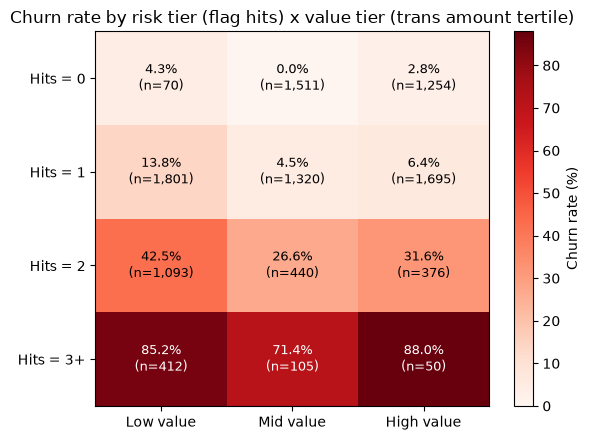

In [2]:
# Cell M5-5(code)|矩陣的樞紐呈現與熱力圖

# Cell M5-5(code)|矩陣轉成 4 × 3 的表 (樞紐轉換, Data Pivoting) + 熱力圖(圖表文字用英文,判讀用中文)
# 透過 pivot 函數,將 matrix 這張長格式的表(12 列,每列一格)轉成「列 = risk_tier(0/1/2/3+)、欄 = value_tier(低/中/高)」的 4 × 3 二維矩陣
# 分別將「各格總人數」、「各格流失率」、「各格流失人數」作為 Value , 並以二維矩陣(risk_tier、value_tier)呈現
# .loc[RISK_ORDER] : 確保列依風險由低到高(0 到 3+)排 ; .rename() : 將欄位名從 value_tier 的整數 1、2、3 改成 low、mid、high
RISK_ORDER = ["0", "1", "2", "3+"]
VALUE_LABEL = {1: "low", 2: "mid", 3: "high"}

pivot_n = matrix.pivot(index="risk_tier", columns="value_tier", values="n").loc[RISK_ORDER].rename(columns=VALUE_LABEL)
pivot_pct = matrix.pivot(index="risk_tier", columns="value_tier", values="churn_pct").loc[RISK_ORDER].rename(columns=VALUE_LABEL)
pivot_churners = matrix.pivot(index="risk_tier", columns="value_tier", values="churners").loc[RISK_ORDER].rename(columns=VALUE_LABEL)

print("各格人數:")
display(pivot_n)
print("各格流失率(%):")
display(pivot_pct)
print("各格流失人數:")
display(pivot_churners)

# 建立 6×4.5 英寸的畫布(fig)與一個座標軸區(ax),之後所有繪圖動作都對 ax 執行
fig, ax = plt.subplots(figsize=(6, 4.5))
# 使用 Matplotlib 套件畫出熱力圖 (Heatmap): 將流失率矩陣的值轉為浮點數,並用紅色調(Reds)漸層;aspect="auto"代表「自動將格子延展呈長方形」
im = ax.imshow(pivot_pct.values.astype(float), cmap="Reds", aspect="auto")  
ax.set_xticks(range(3))   # 設定 X 軸的刻度位置在 0、1、2 這三個點上
ax.set_xticklabels(["Low value", "Mid value", "High value"])   # 將 X 軸的三個刻度依序貼上低、中、高價值的文字標籤
ax.set_yticks(range(4))   # 設定 Y 軸的刻度位置在 0、1、2、3 這四個點上
ax.set_yticklabels([f"Hits = {r}" for r in RISK_ORDER])        # 用迴圈讀取 RISK_ORDER(風險排序),將 Y 軸刻度依序貼上旗標命中數 (Hits = 0~3+) 的文字標籤

# 以雙層迴圈,將「交叉後的各格數字」,依據 X 軸與 Y 軸,填入「矩陣對應的格子內」;並設定格式
for i in range(4):  # 啟動外層迴圈,依序跑過熱力圖的 4 個 Y 軸列 (風險層級:四個風險層)
    for j in range(3):  # 啟動內層迴圈,依序跑過熱力圖的 3 個 X 軸欄 (價值層級:三個價值層)
        # 在矩陣第 i 列第 j 欄的格子正中央,寫上格式處理後的「流失率百分比」與「該格總人數」
        # 設定格子內文字水平置中與垂直置中、字型大小設為 9 級 ; 流失率大於 45% 時文字顯示白色,避免黑色文字被深紅色背景擋住,否則文字顯示黑色
        ax.text(j, i, f"{pivot_pct.values[i, j]:.1f}%\n(n={int(pivot_n.values[i, j]):,})",
                ha="center", va="center", fontsize=9,
                color="white" if pivot_pct.values[i, j] > 45 else "black")

# 設定整張圖表上方的大標題,說明此熱力圖是「風險層級(旗標命中數)與價值層級(交易金額三分位)」的「交叉流失率分析」
ax.set_title("Churn rate by risk tier (flag hits) x value tier (trans amount tertile)")
plt.colorbar(im, ax=ax, label="Churn rate (%)")   # 圖表右側加上一條顏色對應尺標,並註明尺標單位為「流失率 (%)」
plt.tight_layout()   # 自動調整圖表的邊距與元件間距,防止標籤或標題因範圍不足而被切到
plt.show()   # 將繪製完成的最終版圖表渲染顯示

Cell M5-6(markdown)|第 3 節判讀:矩陣

**第 3 節判讀|風險 × 價值矩陣**

**實測**:<br/>
1. 12 格的流失率由「命中 0 個旗標的 0.00% 至 4.29%」,到「命中 3+ 的 71.43% 至 88.00%」。<br/>
2. 同一風險層內,三個價值層的流失率差距(「命中 3+」:低價值 85.19%、中價值 71.43%、高價值 88.00% ; 「命中 2」:42.54%、26.59%、31.65%,同一風險層內、跨價值層的差距最大是 16 個百分點),遠小於「跨風險層的差距(命中 0 到命中 3+ 相差約 80 個百分點)」。由此可知,流失率的高低主要由風險軸決定,價值軸對流失率的影響小;這個結果與第 1 節 1.3 對「價值軸的設計目的」一致:「價值軸的用途」是「判斷值不值得投入挽留資源」,不是「預測誰會流失」(詳見下方判定 2)。<br/>
3. 人數分布極不平均:命中 0 個旗標的 2,835 人中只有 70 人在低價值層,命中 3+ 的 567 人中有 412 人(73%)在低價值層;「高風險 × 高價值」只有 426 人 (50 + 376) ,「高風險 × 低或中價值」有 2,050 人 (412 + 105 + 1093 + 440)。
4. 價值層邊界:低價值層的邊界是: 年消費 2,567 元以下 ; 高價值層的邊界是: 年消費 4,476 元以上。


**判定**:<br/>
1. 矩陣的風險軸有效:「流失率」隨「旗標命中數」單調上升,與 M2 (notebook 02 C3-b) 的五層結構一致 (M5 將命中 3 與 4 合併後,3+ 層 82.89%)。<br/>

2. 價值軸不是流失率的來源,而是「投放值不值得」的判斷依據:同樣命中 3+,高價值層的 50 人平均年消費 6,520 元,低價值層的 412 人平均 1,844 元,前者每留住一人的價值約為後者的 3.5 倍(6,520 ÷ 1,844 = 3.54)(「每留住一人的價值」用該格平均年消費當代理,因此前者每留住一人保住的年消費,約為後者的 3.5 倍)。<br/>
這正是「價值軸存在的意義」:價值軸不改變「誰會流失」,而是決定「對這一格客戶願意投入多少挽留成本」:客戶年消費越高,銀行能負擔的每人挽留成本(人力時間與優惠金額換算成的錢)就越高。<br/>
用詞說明:「挽留資源」和「挽留成本」這兩個詞,都是在說明「為了挽留客戶所做的行動付出」,但差別是:「挽留資源」是指「人力、優惠、預算這些東西本身」,「挽留成本」則是把前述這些資源換算成金錢(把資源寫成「成本(錢)」,才能與「挽留下來的價值(錢)」以相同單位為基準進行對比,得出「投資報酬率」)。本處判定2是在討論「銀行願意花多少錢」,因此選擇用「挽留成本」這個詞較為精確。<br/>

3. 人數分布極不平均的原因是「第 2 節 2.3 說明的結構」:低活躍(交易筆數少)客戶的交易金額幾乎必然少,所以高風險客戶集中在低價值層。<br/>
這不是矩陣設計的缺陷,反而揭露了信用卡業務事實:大多數高風險客戶是低消費客戶(客戶行為本身的結構:用卡較少的客戶,花費金額也較少),若對這類型客戶投放「人工挽留資源」並不符成本效益。<br/>
判斷為「不符成本效益」的邏輯:人工介入的每人成本高(客戶經理逐一電話聯繫要花人力時間,量身優惠要花優惠金額,兩者加起來每人通常數百元到上千元);自動化推播每人只有幾元。<br/>
以命中 3+ × 低價值這格為例,平均年消費 1,844 元,若人工聯繫每人 500 元、精確率 85.2%、挽留成功率假設 20%,依 1.5 的公式,每留住一人要花 500 ÷(0.852 × 0.2)≈ 2,930 元,2930 元已超過這位客戶一年的消費 1844 元,「投入的挽留成本」高於「保住這位客戶的價值」,不符成本效益;同樣的成本投放在高價值層(年消費 6,520 元)才符合成本效益(詳參第 2 節 2.3)。<br/>

**對決策的意涵**:<br/>
1. 搶救區(命中 ≥2 × 高價值)只有 426 人 (50 + 376)、流失者 163 人 (119 + 44)、平均年消費 7,930 元 (Cell M5-7) ➡ 人數規模小、每人價值高,是「採用人工介入去投入挽留資源」的合理規模:以「一位客戶經理一週能聯繫並說明方案的客戶約 30 至 50 位」的估算為例,426 人由 2 至 3 位客戶經理一季內可全部聯繫完;若是低成本區的 2,050 人,聯繫的人力需求是前者的五倍,以人工介入會做不完。<br/>

2. 低成本區(命中 ≥2 × 低或中價值)2,050 人(1,093 + 440 + 412 + 105)、流失者 1,008 人(465 + 117 + 351 + 75),占全體流失者的 62%(1,008 ÷ 1,627),是四個策略區中流失者占比最高的一區;若不處理這一區,全體流失中有六成不會被任何挽留動作處理。<br/>

但這一區每人平均年消費僅 2,202 元(Cell M5-7),依成本效益不適合人工介入,因此本模組對這一區只採用「自動化手段(例如簡訊、App 推播)」。<br/>
判斷邏輯如下:若對這一區採人工聯繫,每人成本以 500 元計,精確率 49.2%、挽留成功率假設 20%,依 1.5 的公式,每留住一位客戶平均花費 500 ÷(0.492 × 0.2)≈ 5,080 元,是這一區客戶平均年消費 2,202 元的兩倍多,投入的挽留成本高於保住的價值,不符成本效益。若改用自動化推播,每人成本以 5 元計,每留住一位客戶平均花費 5 ÷(0.492 × 0.2)≈ 51 元,遠低於該客戶一年 2,202 元的消費金額,符合成本效益。<br/>

補充:<br/>
自動化與人工介入的差別有兩個:(a) 內容:自動化是對整群客戶發送同一套內容,不依個別客戶調整;人工介入是客戶經理依個別客戶的狀況商談並調整方案。(b) 成本結構:自動化由系統一次發送,每多一位客戶的成本只有幾元,也不受銀行工作人力的限制;人工介入每多一位客戶就要多花一位客戶經理的時間,投入的每人(客戶)成本數百元以上,且受客戶經理人數(人力)的限制。<br/>
實務上要選擇「自動化」或「人工介入」,主要依據「這一格客戶的價值是否值得讓銀行負擔每人數百元的成本」,也就是前述 (b)。<br/>


3. 深化區(命中 ≤1 × 高價值)2,949 人(1695 + 1254)、流失率約 4.9%((35 + 109)÷(1254 + 1695)= 144 ÷ 2,949 = 4.88%)、平均年消費 7,654 元(Cell M5-7)。<br/>
這一區流失風險低,不需挽留,但值得做交叉銷售(深化往來):交叉銷售是「向已持有一項產品的客戶推銷另一項不同產品」(例如向只有信用卡的客戶推薦自動扣繳或分期),目標是增加往來產品數。動機有二:(1)這群客戶消費高、目前風險低,是最有能力多用一項產品的人;(2)而且這一區有 38.4% 的客戶往來產品 ≤2 項,而「M3 T2 顯示往來 ≤2 項的流失率 26.89%、≥3 項的流失率 13.14%,M4 模型 B 顯示每多一項產品,流失勝算約降為 0.63 倍」,因此把深化區客戶的產品數拉到 3 項以上,既增加收入,也預防他們日後升到高風險層。<br/>

4. 監測區(命中 ≤1 × 低或中價值) 4,702 人 (1801 + 1320 + 1511 + 70)、流失率 6.6%((3 + 0 + 249 + 60)÷(70 + 1,511 + 1,801 + 1,320)= 312 ÷ 4,702 = 6.63%),不投放挽留資源。原因:這一區流失率低於基準流失率 16.07%,若對他們投放挽留資源,每 100 人裡只有約 7 人本來會流失,錢大多花在「本來就不會流失的人」身上;依 1.5 的公式,精確率 6.6%、成功率 20% 時,每留住一人要花 76 倍的每人投放成本,成本效益是四區中最低的。<br/>
但仍需對這區的人做「定期監測」,因為這一區有 44.7% 的客戶已命中低活躍旗標,再多命中一個旗標就會升到命中 2 的高風險層。<br/>

5. 四區的旗標組成見第 4 節 4.1 ; 各格的動作與優先順序見 4.3。


**待辦或限制**:<br/>
1. 「使用交易金額代理價值軸」會對流失客戶有「系統性低估」(第 2 節 2.2):中途流失客戶的交易金額因使用期間縮短而偏低,部分應屬搶救區的客戶被歸入低成本區,搶救區的實際規模可能大於 426 人。本案無法修正此偏差,因為需要有時間戳記的交易資料才能還原流失前的正常消費,本案沒有這類資料。<br/>
補充(偏差與雜訊的區別):本處的問題是「流失客戶的交易金額被系統性地壓低」,方向固定(只會低估、不會高估),這是「系統性偏差(bias)」,不是「雜訊(noise)」,雜訊(noise)指隨機、沒有固定方向的誤差。<br/>
2. 名單範圍「命中旗標 ≥2」內含兩個風險程度差很多的層:「命中 2 的 1,909 人流失率 36.72%」,「命中 3+ 的 567 人流失率 82.89%」,相差 46 個百分點。這兩層不能用同一種強度處理,所以第 4 節的動作表對「命中 3+ 的格子」設定比「命中 2 的格子」更急的處理時限與更高的優先順序,第 6 節的效益試算也把「命中 ≥3」與「命中 ≥2」當成兩種名單門檻分別計算。<br/>

In [3]:
# Cell M5-7(code)|第 4 節資料:四個策略區的彙總與旗標組成 (本 cell 為第 4 節的資料 cell,第 4 節的判讀在 Cell M5-8)(對應 sql/04_segment_matrix.sql [S1-補2] 至 [S1-補4])
# 本 cell 執行三項計算:
# (1) 依第 1 節 1.4 的規則(命中 ≥2 為高風險、價值層 3 為高價值)「將每位客戶歸入四個策略區」,
#     並「彙總每區的人數、流失者人數、流失率、平均年消費、該區流失者占全體流失者(1,627 人)的比例」。
# (2) 計算「每區」的「旗標占比」:該區客戶中「命中某一旗標的人數 ÷ 該區人數」(例如 zero_util_pct = 該區零動用客戶數 ÷ 該區人數)。
#     用途:1.4 的動作設計原則是「動作 = 該區主要旗標對應的行動方向 + 價值層決定的成本上限」,
#     因此必須先知道「每一區的客戶主要因為哪個旗標被判為高風險」,才能「決定該區的動作方向」;
#     例如:搶救區是「 86.6% 零動用」、「81.9% 淺關係」、「僅 23.0% 低活躍」,動作方向即為「深化往來」與「建立財務綁定」,而「非促進使用」。
# (3) 計算 12 格(風險層 × 價值層)的旗標占比:供 4.3 判斷每一格的主要旗標。同一個策略區內不同格子的旗標組成可能差很多(實測:搶救區的 3+ × 高有 82.0% 低活躍,2 × 高只有 15.2%),所以動作表要以格為單位看。
# 另加兩個組合欄位: 1.「shallow_and_low(淺關係且低活躍,待驗證事項 #21 的名單條件)」、2.「contact_5plus(聯繫 ≥5 次,待驗證事項 #10-a :不分價值層一律改由人工回訪的觸發門檻)」。供第 4 節設定優先順序。

# WITH flags AS (...) 是 CTE(common table expression,共用資料表運算式):在同一個查詢內先建立一個暫時的表 flags,把四個旗標條件轉成 0/1 欄位(布林轉整數);外層查詢再用這四個欄位相加得到命中數 hit_count,並用 NTILE(3) 依交易金額由低到高把客戶平均分成三個價值層(1 最低、3 最高)。最後把結果載入成 pandas DataFrame。
customers = pd.read_sql("""
    WITH flags AS (
        SELECT clientnum, is_churned, total_trans_amt, contacts_count_12_mon,
               (total_trans_ct <= 61)::int AS low_activity,
               (avg_utilization_ratio = 0)::int AS zero_util,
               (total_relationship_count <= 2)::int AS shallow_rel,
               (contacts_count_12_mon >= 4)::int AS high_contact
        FROM clean.customers
    )
    SELECT *, low_activity + zero_util + shallow_rel + high_contact AS hit_count,
           NTILE(3) OVER (ORDER BY total_trans_amt, clientnum) AS value_tier
    FROM flags
""", engine)

# 將 is_churned(是否流失)欄位的資料型態強制轉換為整數(0 或 1),確保該欄位能進行數值運算(例如後續用 sum 算流失人數)。
customers["is_churned"] = customers["is_churned"].astype(int)

# 目的:建立業務邏輯: 自訂一個名為 assign_zone 的函數,傳入一列資料(代表一個客戶),判斷其 hit_count >= 2 (高風險) 與 value_tier == 3 (高價值)的組合。
# 功能:策略區名稱加「數字前綴(1_ 至 4_)」,使 groupby 輸出依「搶救(風險高+價值高)、低成本(風險高+價值低或中)、深化(風險低+價值高)、監測(風險低+價值低或中)」的優先順序排列,而不是依字母順序
def assign_zone(row) -> str:
    high_risk = row["hit_count"] >= 2
    high_value = row["value_tier"] == 3
    if high_risk and high_value:
        return "1_rescue"
    if high_risk:
        return "2_low_cost"
    if high_value:
        return "3_deepen"
    return "4_monitor"


# 為每位客戶貼上「特定策略區標籤」:將每位客戶的資料傳入 assign_zone 函數中計算,並將回傳的字串存入新欄位 zone 
# apply()表示「逐列/逐欄套用」。 axis=1 表示「橫向(逐列)」。
customers["zone"] = customers.apply(assign_zone, axis=1)
customers["risk_tier"] = np.where(customers["hit_count"] >= 3, "3+", customers["hit_count"].astype(str))
# 新欄位 shallow_and_low:淺關係且低活躍: 將兩個 0/1 欄位相乘。1*1=1,其餘狀況皆為 0
customers["shallow_and_low"] = customers["shallow_rel"] * customers["low_activity"]   # 待驗證事項 #21 的組合條件
# 新欄位 contact_5plus:聯繫次數是否 ≥5 次: 轉為 0 或 1
customers["contact_5plus"] = (customers["contacts_count_12_mon"] >= 5).astype(int)    # 待驗證事項 #10-a 的更嚴門檻
# 客戶層級名單:每一列是一位客戶,每一列都帶有「四個旗標 0/1 欄位」、「命中數」、「價值層」、「策略區」與「兩個組合欄位」
# 這是第 4 節動作執行的基礎:(1)「整格的批次動作」依「zone 與 risk_tier × value_tier」發送 ; (2)「客戶層級的個別動作」依「各旗標欄位」觸發 (4.3 說明)
# M8 匯出 mart 層(待驗證事項 #13、#30)時以此表為基礎。本處只顯示前 5 列,確認名單輸出樣貌
# is_churned 欄位只用於本 notebook 驗證分群與動作設計的效果;交付業務單位的客戶名單不含此欄,因為實際投放挽留資源時,「客戶流失與否」這件事尚未發生
display(customers.head(5))


# 功能:依據每個客戶所屬的zone進行分組後,對組內各欄位進行多重聚合統計
# 目的:將一萬筆客戶明細,濃縮成四個策略分區的摘要報告:
#    (1)對 is_churned 欄位: 算 size 得出該區總人數;算 sum 得出該區流失人數;算 mean 得出該區流失率
#    (2)對各個 0/1 標記欄位算 mean, 得出「特定旗標 or 特徵 在該區中的佔比」
zones = customers.groupby("zone").agg(
    n=("is_churned", "size"),
    churners=("is_churned", "sum"),
    churn_pct=("is_churned", "mean"),
    avg_trans_amt=("total_trans_amt", "mean"),
    low_activity_pct=("low_activity", "mean"),
    zero_util_pct=("zero_util", "mean"),
    shallow_rel_pct=("shallow_rel", "mean"),
    high_contact_pct=("high_contact", "mean"),
    shallow_and_low_pct=("shallow_and_low", "mean"),
    contact_5plus_pct=("contact_5plus", "mean"),
)

# 功能:遍歷從第三個欄位開始的所有欄位,若欄位名稱是 _pct 結尾,就將該數值*100並四捨五入至小數點後第一位
# 目的:將原始的機率小數(如 0.145)轉換為易讀的百分比格式(如 14.5%)
for col in zones.columns[2:]:
    if col.endswith("_pct"):
        zones[col] = (100 * zones[col]).round(1)

# 功能:將「各區的平均交易金額」四捨五入至整數位;目的:金額以整數元呈現,與 Cell M5-4 矩陣表的 avg_trans_amt 欄位格式一致
zones["avg_trans_amt"] = zones["avg_trans_amt"].round(0)

# 功能:計算該區流失者占全體流失者(1,627 人;1_627 的底線是 Python 的數字分隔符號,等同 1627)的比例,四捨五入至小數點後第一位
# 目的:流失率(churn_pct)回答『這一區的客戶有多危險』,流失者占比(churner_share_pct)回答『全體流失有多少發生在這一區』,兩者可以不一致:搶救區流失率 38.3% 但只占全體流失者 10.0%,低成本區流失率 49.2% 且占 62.0%。占比用於第 3 節意涵 2 (低成本區不能不處理)、第 8 節『名單涵蓋多少流失者』的判斷 (命中 ≥2 名單涵蓋 72% 的流失者)。
zones["churner_share_pct"] = (100 * zones["churners"] / 1_627).round(1)   

# 將 zones 摘要 DataFrame 渲染出來:產出最終的資料決策報表,供分析者或業務單位直接檢視
display(zones)

# 12 格的旗標占比:供第 4 節 4.3 判斷每一格的「主要旗標」(判斷規則:該格中命中比例 ≥ 50% 的旗標列為主要旗標)
# 同一個策略區內,不同格子的旗標組成可能不同(例如搶救區的「3+ × 高」與「2 × 高」),所以動作表要以格為單位看旗標占比,不能只看區的平均
cells = customers.groupby(["risk_tier", "value_tier"]).agg(
    n=("is_churned", "size"),
    churn_pct=("is_churned", "mean"),
    low_activity_pct=("low_activity", "mean"),
    zero_util_pct=("zero_util", "mean"),
    shallow_rel_pct=("shallow_rel", "mean"),
    high_contact_pct=("high_contact", "mean"),
    shallow_and_low_pct=("shallow_and_low", "mean"),
    contact_5plus_pct=("contact_5plus", "mean"),
)
for col in cells.columns:
    if col.endswith("_pct"):
        cells[col] = (100 * cells[col]).round(1)
display(cells.loc[["3+", "2", "1", "0"]])   # 依風險由高到低排列

,clientnum,is_churned,total_trans_amt,contacts_count_12_mon,low_activity,zero_util,shallow_rel,high_contact,hit_count,value_tier,zone,risk_tier,shallow_and_low,contact_5plus
0,708874533,1,510.0,2,1,1,1,0,3,1,2_low_cost,3+,1,0
1,767712558,1,530.0,3,1,1,1,0,3,1,2_low_cost,3+,1,0
2,709537683,1,563.0,3,1,0,0,0,1,1,4_monitor,1,0,0
3,710899833,1,569.0,3,1,0,0,0,1,1,4_monitor,1,0,0
4,803595858,1,594.0,1,1,1,0,0,2,1,2_low_cost,2,0,0


,n,churners,churn_pct,avg_trans_amt,low_activity_pct,zero_util_pct,shallow_rel_pct,high_contact_pct,shallow_and_low_pct,contact_5plus_pct,churner_share_pct
zone,,,,,,,,,,,
1_rescue,426,163,38.3,7930.0,23.0,86.6,81.9,21.4,16.0,5.9,10.0
2_low_cost,2050,1008,49.2,2202.0,93.1,61.0,25.2,49.3,23.4,7.5,62.0
3_deepen,2949,144,4.9,7654.0,1.8,12.3,38.4,5.0,0.0,0.5,8.9
4_monitor,4702,312,6.6,3006.0,44.7,10.4,3.3,8.0,0.0,0.8,19.2


n  churn_pct  low_activity_pct  zero_util_pct  \
risk_tier value_tier                                                     
3+        1            412       85.2             100.0           88.1   
          2            105       71.4             100.0           94.3   
          3             50       88.0              82.0           94.0   
2         1           1093       42.5              99.8           46.1   
          2            440       26.6              68.4           64.5   
          3            376       31.6              15.2           85.6   
1         1           1801       13.8              97.3            1.6   
          2           1320        4.5              26.7           34.8   
          3           1695        6.4               3.2           21.4   
0         1             70        4.3               0.0            0.0   
          2           1511        0.0               0.0            0.0   
          3           1254        2.8               0.0            0.0   

                      shallow_rel_pct  high_contact_pct  shallow_and_low_pct  \
risk_tier value_tier                                                           
3+        1                      56.6              70.4                 56.6   
          2                      53.3              60.0                 53.3   
          3                      86.0              48.0                 68.0   
2         1                      13.7              40.3                 13.7   
          2                      17.7              49.3                  9.1   
          3                      81.4              17.8                  9.0   
1         1                       0.0               1.1                  0.0   
          2                      11.7              26.8                  0.0   
          3                      66.8               8.6                  0.0   
0         1                       0.0               0.0                  0.0   
          2                       0.0               0.0                  0.0   
          3                       0.0               0.0                  0.0   

                      contact_5plus_pct  
risk_tier value_tier                     
3+        1                        13.6  
          2                        17.1  
          3                        14.0  
2         1                         4.8  
          2                         6.4  
          3                         4.8  
1         1                         0.2  
          2                         2.6  
          3                         0.8  
0         1                         0.0  
          2                         0.0  
          3                         0.0

Cell M5-8(markdown)|第 4 節:策略區與每格動作

## 第 4 節|四個策略區的「旗標組成」與「挽留動作」(決策日誌 [M5-2])

### 4.1 每一區的客戶為什麼被判定為高風險

Cell M5-7 輸出表中的四個占比欄位(low_activity_pct、zero_util_pct、shallow_rel_pct、high_contact_pct)是每一區客戶命中各旗標的比例,回答「這一區的客戶主要因為哪個旗標被判為高風險」;依 1.4 的設計原則,這決定該區要針對什麼旗標做對應的挽留動作:

- **搶救區**(426 人)(風險高+價值高):<br/>
86.6% 零動用、81.9% 淺關係,只有 23.0% 低活躍。<br/>
這一區的客戶消費金額高(平均 7,930 元)但幾乎不用循環信用(零動用)、且只與銀行往來一到兩項產品(淺關係):他們是「消費高、關係淺、與銀行沒有財務綁定(沒有欠款要處理、可能黏著度較低)」的客戶,轉換成本(switching cost,客戶改用其他銀行需付出的代價)低。<br/>

動作方向:<br/>
本區的資源型態由價值層決定:高價值,所以用人工聯繫(客戶經理逐一聯繫、依客戶狀況提供方案)。<br/>
動作的具體內容不在區的層級決定,而在 4.3 以格為單位決定,因為「本區兩格的旗標組成不同」:<br/>
(1) 2 × 高(376 人,占本區 88%)只有 15.2% 命中低活躍,客戶的交易筆數並不低,動作以深化往來與建立持續往來為主;<br/>
(2) 3+ × 高(50 人,占本區 12%)有 82.0% 命中低活躍、68.0% 同時淺關係且低活躍,是消費金額仍高但交易筆數少的客戶(命中低活躍旗標;快照資料看不到筆數是否曾經較高,所以只能說「筆數少」,不能說「消費下滑」),動作除「深化往來」外還要加上「促進使用」。<br/>
(3) 區平均 23.0% 低活躍是兩格混合的結果,只用來描述本區輪廓,不用來設計動作。<br/>


補充說明:<br/>
零動用定義: avg_utilization_ratio = 0 <br/>
循環信用:信用卡有兩種用法:(a) 每月帳單全額繳清:卡只是支付工具,客戶不欠銀行錢,銀行賺不到客戶的利息;(b) 只繳最低應繳金額、其餘欠著滾利息:這叫「使用循環信用」,欠著的卡費(本金,此處未把利息計入)就是循環欠款本金(revolving balance)。<br/>


- **低成本區**(2,050 人)(風險高+價值低或中):<br/>
93.1% 低活躍、61.0% 零動用、49.3% 高聯繫,23.4% 同時「淺關係且低活躍」。<br/>
這一區是「交易筆數少、六成客戶沒有循環欠款本金(零動用 61.0%)、頻繁聯繫客服」的客戶;全體高聯繫客戶(1,622 人)中,約有六成(49.3% × 2,050 ≈ 1,011 人)在這一區。<br/>
流失者有 1,008 人,占全體流失者 62%,是四區中最高;這一區依成本效益不適合人工介入,但承載了六成的流失,所以必須處理(動作方向是「促進使用」與「服務補救」),只是手段限於自動化(第 3 節意涵 1 & 2)<br/>


- **深化區**(2,949 人)(風險低+價值高):<br/>
這一區是「高消費、活躍、但有近四成(38.4%)往來產品 ≤2 項」的客戶,流失率只有 4.9%;<br/>
採取的挽留動作是:對「淺關係的這 38.4%」做「交叉銷售」,把往來產品從一兩項擴大到三項以上(M3 T2:往來 ≤2 項的流失率 26.89%、≥3 項的流失率 13.14%;M4 模型 B:產品數每多一項,流失勝算約降為 0.63 倍)。<br/>


- **監測區**(4,702 人)(風險低+價值低或中):<br/>
44.7% 低活躍,但命中其他旗標的人較少,流失率 6.6%;<br/>
動作是:不投放挽留資源。原因是這一區流失率 6.6% 低於基準 16.07%,對這一區投放,每 100 位客戶中只有約 7 位本來會流失,依 1.5 的公式,每留住一人要花 76 倍的每人投放成本,成本效益是四區中最低的(第 3 節意涵 4);<br/>
只定期監測此區客戶是否移入其他區,例如「每季重新計算每位客戶的旗標命中數與交易金額分位」,命中數升到 2 以上者,依其價值層移入搶救區或低成本區處理<br/>



### 4.2 四個旗標對應的行動方向

| 旗標 | 客戶為什麼被標記 | 行動方向 | 高價值層的做法(人工、個人化) | 低或中價值層的做法(自動化、批次) | 證據來源 |
|---|---|---|---|---|---|
| 淺關係(往來產品 ≤2 項) | 與銀行的關係淺,轉換成本低 | 深化往來:交叉銷售第二、三項產品 | 客戶經理依客戶消費型態推薦一項適合的產品並提供首年優惠 | App 推播或簡訊推薦一項標準產品(如自動扣繳、行動支付綁定) | M2 H4 切片(≤2 項 26–28%);M3 T2(比例差 13.75 pp、勝算比 2.43);M4 模型 A 勝算比 5.1 |
| 零動用(額度動用率 = 0) | 沒有循環欠款,與銀行沒有持續性的財務往來 | 建立持續往來:分期方案(產生未來數期的往來關係)、指定通路回饋(養成固定用卡習慣);目的不是引導客戶動用循環信用 | 專人說明分期零利率方案 | 自動化推送分期或指定通路回饋活動 | M2 H5、C1(零動用 36.15%,+20.08 pp);M4 模型 A 勝算比 6.0 |
| 低活躍(交易筆數 ≤61) | 使用信用卡的頻率低,可能已轉用其他卡 | 促進使用:消費回饋、指定通路加碼 | 個人化回饋(依過去消費通路做個人化設計,例如某客戶最常在加油站消費,就提供該客戶針對加油站通路的消費加碼回饋) | 批次的消費滿額回饋:對名單內全部客戶用同一個條件、同一則訊息一次發送,例如『本月刷滿 3,000 元回饋 100 元』,不依個別客戶調整 | M2 H1 切片(≤61 筆 31–37%);M4 模型 A 勝算比 21.4 |
| 高聯繫(客服聯繫 ≥4 次) | 近期有服務摩擦或爭議 | 服務補救:主動回訪、爭議處理 | 客戶經理主動回訪,了解聯繫原因 | 客服系統自動標記,下次來電優先處理;聯繫 ≥5 次者不分價值層一律人工回訪(待驗證事項 #10-a 的更嚴門檻) | M2 H6 切片(≥4 次 22.6% 至 100%);M3 T1(卡方,Cramér's V 0.241);M4 模型 A 勝算比 4.4 |

零動用旗標的動作以「建立持續往來」為目的,不以「引導客戶動用循環信用」為目的,因為後者會增加客戶的利息負擔,且涉及公平待客原則(M7 檢視)。<br/>

依待驗證事項 #11,本節所有動作都不包含「調高信用額度」,理由有三:<br/>
(1) notebook 02 C4 顯示「低額度客戶的流失率較高」,但無法判斷原因是「額度不夠用,客戶因此轉用其他銀行的卡」還是「客戶與銀行往來淺,銀行因此只核給低額度」;若是後者,額度低只是關係淺的結果,調高額度不會改變流失(notebook 02 C4 判讀第二點:機制 (a) 額度不便 vs 機制 (b) 額度為關係深度的痕跡)。<br/>
(2) M4 模型 B 在控制往來產品數與循環欠款(本金)後,信用額度的係數不顯著(勝算比 0.94、p = 0.32),與「額度低只是關係淺的結果」相容。<br/>
(3) 「調整授信額度」涉及風險控管,有呆帳風險與審核成本,不是行銷單位可以單獨決定的動作。若要把調信用額度列為挽留手段,須先經 M6 實驗驗證。<br/>


### 4.3 12 格的動作表

每格動作 = 該格主要旗標的行動方向(4.2 表)+ 該格價值層決定的成本上限(高價值層:人工聯繫、低中價值層:自動化手段)。<br/>

**主要旗標的判斷規則**:<br/>
1. 依 Cell M5-7 末段「12 格的旗標占比」表,該格中命中比例 ≥ 50% 的旗標列為主要旗標;命中 0 個旗標的格子沒有主要旗標。50% 是本模組自訂的操作慣例(性質同 [M2-10]),理由是「多數決」的概念。取 50%,是因為這個數字是「多數」的自然界線;動作表的目的只是「決定整格批次動作的內容」,不需要更精細的門檻。<br/>
接近門檻但未達 50% 的旗標(3+ × 高的高聯繫 48.0%、2 × 中的高聯繫 49.3%)不會因此漏掉沒處理:這些格子裡命中高聯繫的客戶,仍會依 4.2 表在「客戶層級」收到該旗標在其價值層的對應做法(高價值層:客戶經理主動回訪了解聯繫原因;低或中價值層:客服系統自動標記、下次來電優先處理 ; 聯繫 ≥5 次者不分價值層一律人工回訪),只是不列入該格整格一起執行的動作組合。<br/>

2. 整格的動作是對整格客戶一起執行的。<br/>
若某旗標在該格有超過一半的客戶命中,對整格執行該旗標對應的動作,這個動作處理的原因就與該格多數客戶被判為高風險的原因相同;<br/>
若不到一半,整格一起執行會讓多數客戶收到與自己風險原因無關的動作。<br/>
因此,不到一半的旗標,其動作不放進整格的動作組合,改在客戶層級執行:<br/>
名單是「逐位客戶」輸出,每位客戶命中哪些旗標都在名單欄位裡 (Cell M5-7 的 customers 表每位客戶有 low_activity、zero_util、shallow_rel、high_contact 四個 0/1 欄位)。<br/>
客戶層級的動作與整格的批次動作同時執行:客戶名單交付時,每位客戶已帶有自己的旗標欄位,執行系統依欄位觸發個別動作,不是分開兩個階段(參 Cell M5-7 customers 表相關註解與輸出)。<br/>
4.2 表是「旗標 → 動作」的對照表,只要某位客戶命中某個旗標,就對該客戶執行 4.2 表中該旗標的動作,不論這位客戶落在 12 格中的哪一格。<br/>

**優先順序的排法**:<br/>
只算這六格的原因:只有命中旗標 ≥2 的這六格(搶救區兩格、低成本區四格)客戶會收到挽留動作,需要排先後;<br/>
因為:深化區與監測區不做挽留,不用放進來排序。<br/>
排序方式依「該格流失率 × 該格平均年消費」由高到低排序(這兩個數字取自 Cell M5-4 [S1] 表)。<br/>

「該格流失率 × 該格平均年消費」這個乘積的意思:「流失率 × 平均年消費」等於「該格每位客戶平均會流失的年消費」的原因:<br/>
某一格有 n 位客戶,流失率 p,平均年消費 v。這一格會流失的客戶約 n × p 人,他們每人帶走約 v 元的年消費,所以這一格總共會流失的年消費約 n × p × v 元;除以人數 n,就是每位客戶平均會流失 p × v 元。以「3+ × 高」為例:50 人、88.0%、6,520 元 → 這一格總共會流失約 50 × 0.88 × 6,520 ≈ 287,000 元,平均每人 5,740 元。<br/>
實務意義:<br/>
對這一格的一位客戶投放挽留,若成功,最多能避免的損失就是 p × v,所以它是「每接觸一位客戶能避免的損失上限」(對這一格每投放一位客戶,能避免的損失上限);依這個乘積由高到低排序,就是把有限的人力先用在「每接觸一位客戶能避免最多損失」的格子。<br/>

**所有動作皆為假設性方案**:<br/>
表中每一格的動作都依「該旗標與流失有關聯」設計,動作皆為假設性方案 (詳參: 1.4),表內就不逐格重複標示動作為「假設性方案」;「挽留動作有效與否」由 M6 的實驗驗證。
每一格動作的證據來源列在 4.2 表的「證據來源」欄。<br/>

| 格(命中 × 價值) | n | 流失率 | 平均年消費 | 流失率 × 年消費 | 策略區 | 主要旗標(占比 ≥ 50%) | 動作 | 優先順序 |
|---|---|---|---|---|---|---|---|---|
| 3+ × 高 | 50 | 88.0% | 6,520 元 | ≈ 5,740 元 | 搶救 | 低活躍、零動用、淺關係 | 客戶經理一週內聯繫:推薦一項適合產品 + 分期零利率 + 個人化消費回饋(這一格 82.0% 低活躍,交易筆數少,故增加此「促進使用」措施);「淺關係且低活躍」者(68.0%)最優先(待驗證事項 #21) | 1 |
| 2 × 高 | 376 | 31.7% | 8,118 元 | ≈ 2,570 元 | 搶救 | 零動用、淺關係 | 客戶經理一個月內聯繫:同上,優惠幅度可較低 | 2 |
| 3+ × 中 | 105 | 71.4% | 2,987 元 | ≈ 2,130 元 | 低成本 | 低活躍、零動用、淺關係、高聯繫 | 自動化:分期方案推送 + 滿額回饋 + 推播推薦一項標準產品(淺關係 53.3% / 56.6%);高聯繫者客服優先處理 | 3 |
| 3+ × 低 | 412 | 85.2% | 1,844 元 | ≈ 1,570 元 | 低成本 | 低活躍、零動用、淺關係、高聯繫 | 自動化:同上;不投入人工 | 4 |
| 2 × 中 | 440 | 26.6% | 3,350 元 | ≈ 890 元 | 低成本 | 低活躍、零動用 | 自動化:滿額回饋;高聯繫者客服優先處理(49.3%,在客戶層級對有命中旗標者個別執行) | 5 |
| 2 × 低 | 1,093 | 42.5% | 1,799 元 | ≈ 765 元 | 低成本 | 低活躍 | 自動化:滿額回饋;預算不足時可暫緩 | 6 |
| 1 × 高 | 1,695 | 6.4% | 8,441 元 | — | 深化 | 淺關係(66.8%) | 對命中淺關係旗標者以自動化推播交叉銷售(原則:人工資源只用於「高價值層」的「挽留動作」,保留給搶救區;深化區雖為高價值層,但深化動作並非挽留動作,採自動化即可);<br/>命中其他單一旗標者不投放 | 不排(不對此格客戶做挽留動作,而是深化往來) |
| 0 × 高 | 1,254 | 2.8% | 6,590 元 | — | 深化 | 無(命中 0 個旗標) | 不投放挽留動作;維持常規服務 | 不排(不對此格客戶做挽留動作) |
| 1 × 低 | 1,801 | 13.8% | 1,726 元 | — | 監測 | 低活躍(97.3%) | 不投放挽留動作;監測區的優先監測對象:流失率最接近基準流失率、再命中一個旗標即升為命中 2,每季重算命中數 | 不排(不對此格客戶做挽留動作) |
| 1 × 中、0 × 中、0 × 低 | 2,901 | 2.2% | — | — | 監測 | 無(無任何旗標占比 ≥ 50%) | 不投放挽留動作;每季重算旗標命中數 | 不排(不對此格客戶做挽留動作) |


(2,901 = 1,320 + 1,511 + 70;流失者 60 + 0 + 3 = 63;63 ÷ 2,901 = 2.17%)<br/>


**這張表的用途**:<br/>
1. 把分析結論轉成「業務單位可以直接執行的名單與動作」:<br/>
每一格的名單條件是 M2 的旗標定義 +  M5 的價值層,<br/>
動作方向依該格主要旗標對應 4.2 表 : 4.2 表每一列的行動方向都標明來自 M2、M3、M4 的哪一項證據。<br/>
2. 所有動作在 M5 皆為假設性方案:<br/>
每個動作都依「該旗標與流失有關聯」設計(例如:淺關係客戶流失率高,所以對他們做交叉銷售),M3、M4 已寫明本專案的證據只能證明關聯、不能證明因果,因此,動作有效與否(例如:深化往來能否降低流失)要由 M6 的實驗驗證;本模組的動作表是 M6 實驗的候選方案,不是已驗證的結論。<br/>


**本模組做分區、分格的程度:**<br/>
1. 只有四區分區不夠(例如:同一區內「命中 3+」與「命中 2」的流失率相差 46 個百分點(第 3 節待辦 2),處理時限與優先順序必須不同,所以要切分成 12 格,個別格要整格一起執行的動作組合不能用區平均決定)。<br/>
2. 但用 12 格區分已足,不用再往下細分(切更細的格),因為再往下就變成「「旗標組合」(四個旗標的 16 種組合 × 3 個價值層)」,對業務單位不可執行,也沒有必要,因為客戶層級的個別動作已經由名單上每位客戶的旗標欄位處理(4.2 表)。<br/>
3. 4.3 決定「整格一起做什麼」,4.2 決定「命中某旗標的個人另外做什麼」(4.2 表是對照表:左欄是旗標,右欄是該旗標對應的動作)。<br/>
4. 實務上,挽留活動通常設 4 到 8 個「處理組(treatment)」,每組一套動作;本案實際做挽留的是 6 格,加上深化與監測,是實務上正常的規模。<br/>


**客戶層級的執行**細節說明:<br/>
1. 什麼時候做「客戶層級的執行」:<br/>
與整格動作同時做,不是另一個階段。名單交給業務單位時,每一列是一位客戶,除了該客戶所在的格與該格的動作組合,還帶著該客戶自己的四個旗標欄位;執行系統對整格發送批次動作的同時,依每位客戶的旗標欄位觸發 4.2 表的個別動作(例如某位 2 × 中的客戶 high_contact = 1,系統就會同時把他標記為「來電優先處理」)。<br/>
2. 客戶名單的產生:<br/>
Cell M5-7 第一段 customers = pd.read_sql(...) 的 CTE 表:每位客戶一列,欄位有 clientnum、is_churned、total_trans_amt、contacts_count_12_mon、四個旗標 0/1 欄位、hit_count、value_tier ; 之後 customers["zone"] = ... 再加上策略區欄位。
這張表是全 notebook 唯一的「客戶層級名單」,zones 與 cells 兩張表都是從這張 customers 表彙總出來。<br/>
3. M8 也會使用 customers 表:<br/>
M8 匯出 mart 層(待驗證事項 #13、#30)時,會將 customers 這張表當作客戶名單,交給儀表板與業務單位(包含 clientnum、zone、四個旗標、hit_count、value_tier),第 8 節總表的名單條件都能從這張 customers 表直接篩選出來。<br/>
4. is_churned 欄位只用於本 notebook 驗證分群與動作設計的效果;交付業務單位的客戶名單不含此欄,因為實際投放挽留資源時,「客戶流失與否」這件事尚未發生。<br/>

Cell M5-9.0(markdown) | 第 5 節 (前言) 

## 第 5 節前言 | H3 消費變化比的門檻位置 (待驗證事項 #17 定案) (決策日誌 [M5-5]): <br/>
**目的:** <br/>
區分「消費變化比所關聯的流失率變化」是「門檻效應」或「連續效應」。<br/>
回答「示警的數字是什麼」、這個數字是「資料本身的特性決定」或「分析者選擇的取捨」。<br/>

**結果:** <br/>
判定「消費變化比所關聯的流失率變化」是「連續效應」。<br/>

### 第 5 節 目的與概念說明: 
**一、第 5 節回答的問題(待驗證事項 #17)**<br/>
M2 階段 B 對消費變化比做五分位切片(notebook 02 Cell 26),結果是第 1 箱(變化比 0 至 0.604,2,026 人)流失率 27.20%,其餘四箱 12% 至 15%、接近基準流失率。<br/>
M2 當時把這個形狀稱為「門檻效應」,並把 0.604 寫成門檻;但 0.604 只是「把一萬人依消費變化比排序後,前五分之一剛好排到哪裡」的箱界,是依人數決定的箱界,不是依流失率決定的。<br/>
因此,M2 列出待驗證事項 #17 ➡ 若 M5 要把「變化比 < X 即示警」寫成規則,X 需要更準確的定位。這件事交給 M5 策略階段執行。<br/>

**二、「門檻」的實務意義 : 示警門檻**<br/>
「規則裡的固定數字 X」代表:「變化比低於 X 的客戶就要被圈進挽留名單或觸發挽留動作」。業務單位執行規則時需要一個明確的數字,所以分析要回答「X 應該是多少」、「這個數字是資料本身特性決定的、或是分析者選擇的取捨」。<br/>

**三、區分「門檻效應」與「連續效應」的實益**<br/>
1. 門檻效應:流失率在某一個值兩側突然跳升,例如 0.55 以上 15%、0.55 以下 40%。若是這樣,X 由資料決定(也就是「跳升的位置」),規則的訂定有「客觀依據」,就算換一批客戶,門檻也大致穩定。<br/>
2. 連續效應:流失率隨變化比一路平緩改變,沒有特別的一點(突然跳升)。若是這樣,X 沒有資料依據,只能由分析者依「名單要多大、流失率要多高」取捨,而且必須在報告裡寫明這是取捨、不是資料特性給予的設定依據。<br/>
3. 若不區分這兩種效應:分析者會把「< 0.604」當成「資料特性給予的門檻」寫進規則交給業務單位,但實際上「這個數字只是五分位的箱界」,只要換一批客戶,X 就會改變,規則也會隨之失效,而且無法解釋 0.604 這個數字的由來。<br/>

**四、「在 M5 階段才做此區分」的原因**<br/>
M2 的任務是「找訊號」:M2 的目的是「確認變化比與流失有沒有關聯」,使用「五分位」切法就足以回答。<br/>
「要不要把這個變化比的數字寫成規則、X 設多少」則是規則設計的決策,屬於 M5 的策略工作;而且只有在 M5 決定「這個變數可能用來當作規則」之後,才值得花時間做更細的定位。<br/>
分析規劃的分工是:M2 找訊號,M5 定規則。<br/>

**五、「一箱的範圍太寬就看不出形狀」的原因**<br/>
一箱只有一個流失率數字,這個流失率數字是整箱的平均。例如:第 1 箱 0 至 0.604 涵蓋 2,026 人,27.2% 可能是:(a) 0 至 0.5 的人流失 60%、0.5 至 0.604 的人只有 15%(跳升),也可能是(b) 從 60% 平緩降到 15%(連續),(a)和(b)兩種情況平均起來的流失率都可能是 27.2%。因此,要分辨 (a) 與 (b),必須把這一箱切得更細,才能看出真實詳細形狀。<br/>



### 第 5 節 實作步驟與結果判斷: <br/>
**第一步:十分位(等人數分箱/等量分箱)**<br/>
沿用 M2 的 NTILE 方法,但改為「切成十箱」,每箱 1,013 人。<br/>
結果:第 1 箱(0 至 0.531) 流失率 37.12%、第 2 箱(0.531 至 0.604) 流失率 17.28%、第 3 箱起,流失率 10% 至 16%。<br/>
得出兩個觀察:高流失集中在 0.53 以下 ; 0.53 至 0.60 的流失率已接近基準流失率。<br/>
但十分位切分法有兩個限制:<br/>
(a) 第 1 箱仍涵蓋 0 至 0.531,流失率還是只能看出一個平均數,但看不出箱內真實分佈形狀;<br/>
(b) 相等人數分箱下,每箱寬度(消費變化比的箱內寬度)不同:第 1 箱寬 0.531,第 4 箱只寬 0.042。這種情況下無法看出斜率,所以無法說明「消費變化比每增加多少,流失率會下降多少」。<br/>


**第二步:固定寬度分箱(等寬分箱)**<br/>
改成「每箱在消費變化比軸上一樣寬」:消費變化比 0.40 至 0.45 為一箱、消費變化比 0.45 至 0.50 為一箱、依此類推到 0.80,總共切為 8 箱。<br/>
每箱人數不同(例如:有 218 人一箱、也有 1,272 人一箱),但消費變化比的每箱寬度相同 (都是 0.05 ),因此可以直接讀出「當消費變化比上升 0.05 時,流失率降多少」。<br/>

1. 「取 0.05 這個寬度切分」的原因:<br/>
寬度的選擇要「細到看得出形狀」,又要兼顧「每箱有足夠人數讓流失率可判讀」。0.05 的寬度在 0.40 至 0.80 之間切出 8 箱,最少的一箱 218 人,依 [M2-10] 可判讀;若取 0.01 為寬度會切出 40 箱,多數箱的每箱人數不到 100 人,流失率會被隨機波動主導,不可判讀。<br/>
2. 「取 0.40 至 0.80」的原因:<br/>
十分位切分的結果顯示「流失率的變化集中在 0.53 至 0.70 之間」,但若只切這一段,會看不到「變化開始之前」與「變化結束之後」的流失率水準,無法確認流失率的下降從哪裡開始、到哪裡結束。<br/>
因此,將切分往左延伸到 0.40、往右延伸到 0.80,讓觀察區間兩端各有一段作為對照:左側 0.40 至 0.53 對照「更低的消費變化比是否流失率更高」,右側 0.70 至 0.80 對照「流失率是否已經降到基準流失率附近、不再變化」。
到 0.40 就不再往左是因為「0.40 以下只有 228 人,再切每 0.05 一箱會導致一箱不到 30 人,無法判讀」;到 0.80 就不再往右是因為「十分位已顯示 0.80 以上流失率在 14% 至 16% 之間、與基準流失率相同,沒有觀察形狀的必要」。<br/>
3. 等寬分箱的切分結果(第 1 箱 ➡ 第 8 箱的流失率) : 38.07% → 28.62% → 23.11% → 16.37% → 14.17% → 11.52% → 13.13% → 10.07%。
形狀是「一路平緩下降,沒有跳升」,故判定為「連續效應」。<br/>


**第三步:[S2-補2] 「觀察範圍外的兩端」與「兩個候選示警門檻 X 的名單規模」**<br/>
判定為「連續效應」後, 「消費變化比的示警門檻 X 」就必須由分析者取捨選擇:<br/>
取捨需要知道:
1. 「X 設在 0.50 或 0.60 時,名單規模多大、流失率多高」: <br/>
選這兩個值的原因:<br/>
0.60 是流失率降到基準流失率附近的位置(0.60 以上各箱 10% 至 14%),把 X 設在這裡等於圈進所有流失率仍高於基準流失率的客戶,圈出的名單最大(1,945 人),是合理範圍內最寬鬆的圈法設定,也接近 M2 原本的 0.604,可直接對照;<br/>
0.50 是流失率約為基準流失率兩倍以上的位置(0.50 以下各箱都在 28% 以上),是名單較小、流失率較高的一端,圈出的名單最小(729 人),是合理範圍內最嚴格的設定。<br/>
X 這個示警門檻的數字是「決策者要決定的數字」。表中算了兩個端點:X = 0.50 時示警名單 729 人、名單流失率 41.56%;X = 0.60 時 1,945 人、27.51%。若 X 取兩者之間的值(例如 0.55),名單人數會介於 729 與 1,945 人之間(0.55 時為 729 + 489 = 1,218 人)、名單流失率介於 41.56% 與 27.51% 之間,X 越接近 0.60,名單越大、流失率越低。<br/>
X 在本模組的用途是「低成本區額外回饋動作的觸發線(第 5 節判讀意涵 2)」。注意: 729 人與 1,945 人是消費變化比低於 X 的全體客戶數,額外回饋則只對全體「消費變化比低於 X 的客戶」中的「低成本區的客戶」發放,所以實際發放名單為 X = 0.50 時 308 人(流失率 72.40%, 308 人中 223 人流失)、X = 0.60 時 641 人(流失率 61.62%, 641 人中 395 人流失)(Cell M5-9 extra_reward 表)。「額外回饋」有預算上限,決策者依預算能涵蓋的人數在這兩個端點之間選一個 X, 並對從該 X 值得出的「消費變化比低於 X 且落在低成本區」的客戶發放。<br/>

2. 「共四列 (< 0.40、< 0.50、< 0.60、>= 0.80)」:必須補上觀察範圍外的兩端(< 0.40、≥ 0.80) :[S2-補] 只涵蓋 0.40 至 0.80 的 6,232 人,另有 3,895 人在範圍外。<br/>
補上觀察範圍外的兩端(< 0.40、≥ 0.80)的用途有二:讓判讀涵蓋全體 10,127 人;並用兩端的數字確認形狀的判定,0.40 以下流失率 60.96% 表示下降趨勢在左側仍持續(連續效應延伸到最低端),0.80 以上 14.75% 表示右側已與基準相同(下降在 0.80 之前結束)。<br/>

3. 注意: 『< 0.50』與『< 0.60』兩列不是互斥的分段,而是名單的總規模:規則『變化比 < X 即示警』圈出的是全部變化比低於 X 的客戶(依這條規則圈出的示警名單,就是全部變化比低於 X 的客戶,不是「剛好落在某一段」的客戶),所以 X = 0.50 的名單(729 人)自然應該包含變化比 < 0.40 的 228 人,X = 0.60 的名單(1,945 人)自然應該包含 X = 0.50 的 729 人。<br/>
『< 0.50』與『< 0.60』這兩列回答的是『門檻設在 X 時,總共要投放幾個人、其中幾個會流失』。<br/>
< 0.40、< 0.50、< 0.60、>= 0.80 這四列是各自回答一個問題,人數有重疊,所以不能把四列相加去算「全體」。<br/>


### 觀念補充說明:<br/>
**兩種分箱方法的分工:**<br/>
1. 「等人數分箱(NTILE 等量分箱)」適合「比較各組、每組樣本數相同、不受極端值影響」,但「箱寬不等、看不出斜率」。<br/>
2. 「等寬分箱」適合看「每增加一單位,結果變多少」的形狀,但「每箱人數不等,必須同時看 n 才能判斷可不可讀」。<br/>
3. 本節採兩階段分析:第一階段用等人數分箱(NTILE)定位「流失率的變化集中在哪一段」,第二階段再對該段改用「等寬分箱」觀察形狀。第二階段的觀察範圍由第一階段的結果決定,這兩種分箱各有分工,不是「等寬分箱取代等人數分箱」。<br/>

,decile,min_chng,max_chng,n,churn_pct
0,1,0.000,0.531,1013,37.12
1,2,0.531,0.604,1013,17.28
2,3,0.604,0.655,1013,13.92
3,4,0.655,0.697,1013,10.96
4,5,0.697,0.737,1013,13.52
5,6,0.737,0.781,1013,10.46
6,7,0.781,0.830,1013,10.37
7,8,0.831,0.892,1012,16.50
8,9,0.892,0.998,1012,16.30
9,10,0.998,3.397,1012,14.23


,bin_lo,bin_hi,n,churn_pct
0,0.40,0.45,218,38.07
1,0.45,0.50,283,28.62
2,0.50,0.55,489,23.11
3,0.55,0.60,727,16.37
4,0.60,0.65,981,14.17
5,0.65,0.70,1189,11.52
6,0.70,0.75,1272,13.13
7,0.75,0.80,1073,10.07


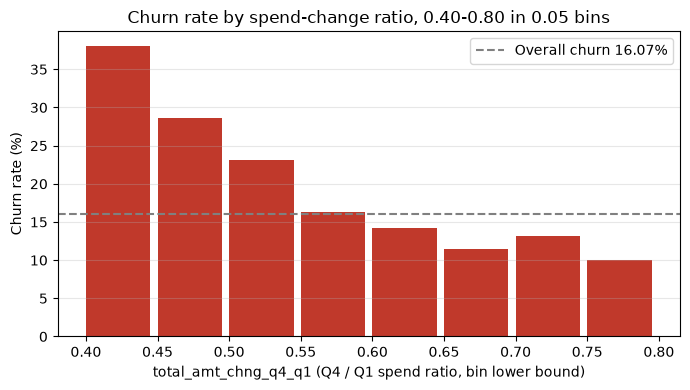

,segment,n,churners,churn_pct
0,< 0.40,228,139,60.96
1,>= 0.80,3667,541,14.75
2,< 0.50 (candidate X),729,303,41.56
3,< 0.60 (candidate X),1945,535,27.51


,trigger_x,n,churners,churn_pct
0,< 0.50,308,223,72.40
1,< 0.60,641,395,61.62


In [4]:
# Cell M5-9(code)| 第 5 節資料 : H3 消費變化比的門檻定位 (對應 sql/04_segment_matrix.sql [S2]、[S2-補]、[S2-補2];待驗證事項 #17)

# [S2] 十分位:把全體客戶依「消費變化比(total_amt_chng_q4_q1)」由低到高排序,平均切成十箱,每箱 1,013 人(等人數分箱,與 M2 五分位同一方法,只是切得更細)。
# 目的:M2 第 1 箱涵蓋 0 至 0.604,一箱只有一個平均流失率 27.20%,無法分辨箱內是「某個消費變化比數值以下的流失率突然變很高」還是「流失率一路平緩下降」;
#       十分位先把這一箱切成兩半(0 至 0.531、0.531 至 0.604),定位「高流失集中在哪一段」。
# 限制:等人數分箱的每箱消費變化比寬度不同(第 1 箱寬 0.531,第 4 箱只寬 0.042),不能讀出「消費變化比每增加固定幅度,流失率降多少」,所以還需要 [S2-補]。
# 語法: CTE:先為每位客戶算出所屬的十分位箱號。依變化比排序均分十箱;clientnum 為第二排序鍵,使同值客戶的分箱結果固定而可重現(同 sql 04 語法筆記 (2))。查詢箱號 1 至 10 (1 為變化比最低的一箱),查詢各箱「變化比下界、上界,兩者合起來就是這一箱在變化比軸上的範圍」、「各箱人數」、「各箱流失率:布林轉 0/1 後取平均,乘 100 取兩位小數」。依箱號分組並排序,輸出十列。

deciles = pd.read_sql("""
    WITH deciles AS (
        SELECT clientnum, is_churned, total_amt_chng_q4_q1,
               NTILE(10) OVER (ORDER BY total_amt_chng_q4_q1, clientnum) AS decile
        FROM clean.customers
    )
    SELECT decile, MIN(total_amt_chng_q4_q1) AS min_chng, MAX(total_amt_chng_q4_q1) AS max_chng,
           COUNT(*) AS n, ROUND(100.0 * AVG(is_churned::int), 2) AS churn_pct
    FROM deciles GROUP BY decile ORDER BY decile
""", engine)
display(deciles)


# [S2-補] 固定寬度分箱(等寬分箱):不依人數切,而是在變化比軸上每 0.05 切一箱:0.40–0.45、0.45–0.50、0.50–0.55、…、0.75–0.80,共 8 箱;每箱人數不同,但寬度相同。
# 語法: 
# 一、查詢每一個消費變化比數值應該落在哪一箱:
# (1)算出該箱的下界(bin_lo),把消費變化比向下取到最接近的 0.05 倍數(例如 0.63 → 0.60):先將數值轉為 numeric 避免浮點誤差把邊界值歸錯箱(sql 04 語法筆記 (7))。然後開始計算:先除以 0.05 得出該值是第幾箱(第幾個 0.05),例如 0.63/0.05=12.6,再用 FLOOR 無條件捨去(12.6 變成 12)得出第 12 箱這個位置,最後再用 12* 0.05 還原真正的數值邊界得出 0.60,就是該箱的下界。
# (2) 得出該箱上界 = 該箱下界 + 0.05
# 二、查詢該箱人數 n (等寬分箱的人數不相等,判讀時要一併看 n)。查詢該箱流失率。
# 三、WHERE 語法:只取觀察範圍(消費變化比落在 0.40 至 0.80 之間)的值,落在這個範圍外的兩端在 [S2-補2] 另算。依 SELECT 第 1、2 個運算式(bin_lo、bin_hi)分組,並依 bin_lo 排序。
bins = pd.read_sql("""
    SELECT FLOOR(total_amt_chng_q4_q1::numeric / 0.05) * 0.05 AS bin_lo,
           FLOOR(total_amt_chng_q4_q1::numeric / 0.05) * 0.05 + 0.05 AS bin_hi,
           COUNT(*) AS n, ROUND(100.0 * AVG(is_churned::int), 2) AS churn_pct
    FROM clean.customers
    WHERE total_amt_chng_q4_q1 >= 0.40 AND total_amt_chng_q4_q1 < 0.80
    GROUP BY 1, 2 ORDER BY 1
""", engine)
display(bins)


# 畫一張長條圖:x 為各箱下界、y 為各箱流失率
fig, ax = plt.subplots(figsize=(7, 4)) # 建立 7 × 4 英寸的畫布與一個座標軸區
# 下界和流失率這兩欄從 SQL 查詢回來後是 numeric(Decimal)型別,轉 float 才能繪圖(寫法:astype(float))
# width=0.045:長條的寬度,單位與 x 軸相同(變化比);箱寬是 0.05,寬度設 0.045 讓每根長條右側留 0.005 的空隙,相鄰長條不會貼在一起,較好閱讀。(matplotlib 長條圖的 x 位置與 width 都以「x 軸的資料單位」計,本圖的 x 軸就是變化比,所以 width=0.045 的意思是「這根長條在變化比軸上的寬度是 0.045」)
# align="edge" 長條的左邊緣放在 x 值(箱的下界)上、往右畫,較好閱讀。(若用 matplotlib 預設的 align="center",長條會以下界為中心往左右各畫一半,位置會與箱的實際範圍(例如 0.40 至 0.45)錯開))(預設的 center: 長條會以 x 值為中心往左右各畫一半,x = 0.40 的長條會畫在 0.3775 至 0.4225,這樣長條的位置就不是這一箱真正的範圍)
ax.bar(bins["bin_lo"].astype(float), bins["churn_pct"].astype(float), width=0.045, align="edge", color="#c0392b") 

ax.axhline(BASELINE_CHURN_PCT, color="grey", linestyle="--", label="Overall churn 16.07%") # 加一條基準流失率 16.07% 的水平虛線,供判讀「哪些箱高於基準」
ax.set_xlabel("total_amt_chng_q4_q1 (Q4 / Q1 spend ratio, bin lower bound)")   # x 軸標籤:消費變化比(Q4 對 Q1 消費金額比值),刻度為箱的下界
ax.set_ylabel("Churn rate (%)")   # y 軸標籤:流失率(%)
ax.set_title("Churn rate by spend-change ratio, 0.40-0.80 in 0.05 bins")   # 圖標題:「0.40 至 0.80 每 0.05 一箱」的各箱流失率
ax.legend()   # 顯示圖例說明(流失率基準線的說明標籤)
ax.grid(alpha=0.3, axis="y")   # 長條圖上只畫水平格線、格線的透明度 0.3,方便閱讀各箱的高度
plt.tight_layout()   # 自動調整邊距,避免標籤被裁切
plt.show()  # 顯示圖形


# [S2-補2] 觀察範圍外的兩端,以及兩個候選示警門檻 X 的名單規模:供第 5 節判讀引用。
# 既然 [S2-補] 顯示是「連續效應」,X 就只能由「名單多大、流失率多高」取捨 
# 此處算出 X = 0.50 與 X = 0.60 兩個候選值各自圈出的人數、流失者與流失率。
# X 取 0.50 與 0.60 兩個候選值的依據見 Cell M5-9.0 第三步第 1 點:0.60 為流失率降到基準附近的位置(合理範圍內,圈法最寬鬆的那一端),0.50 為流失率約為基準兩倍的位置(較嚴的一端)
# 注意:『< 0.50』與『< 0.60』兩列是名單總規模,不是分段:規則『< X 即示警』圈出全部低於 X 的客戶,所以 < 0.50 的 729 人包含 < 0.40 的 228 人;四列人數有重疊,不能相加 (詳參 Cell M5-9.0 第三步第 3 點)

# 語法: 
# 第一段: 查詢「第 1 列:觀察範圍左側之外(變化比 < 0.40)」的人數、流失者、流失率 (後三段的欄名沿用第一段的別名) 
# (後三段不寫 AS 別名:UNION ALL 的結果欄名以第一段 SELECT 的別名為準,後面各段的別名會被忽略(同 sql 01 [D] 區);前提是四段的欄位數量與型別相同,本查詢四段都是「文字、整數、整數、numeric」四欄)
# (UNION 或 UNION ALL 疊起來的結果都遵守「以第一段 SELECT 別名為準,後面各段別名會被忽略」的 SQL 規則)
# 第二段: 查詢「第 2 列:觀察範圍右側之外(變化比 ≥ 0.80)」的人數、流失者、流失率
# 第三段: 查詢「第 3 列:候選門檻 X = 0.50 圈出的名單規模」的人數、流失者、流失率 (WHERE < 0.50 就是規則『變化比 < X 即示警』在 X = 0.50 時的篩選條件,COUNT() 即該規則圈出的名單人數、SUM 為名單內流失者、AVG 為名單流失率(精確率))
# 第四段: 查詢「第 4 列:候選門檻 X = 0.60 圈出的名單規模」的人數、流失者、流失率 (WHERE < 0.60 就是規則『變化比 < X 即示警』在 X = 0.60 時的篩選條件,COUNT() 即該規則圈出的名單人數、SUM 為名單內流失者、AVG 為名單流失率(精確率))
# UNION ALL:把四段查詢各一列的結果上下疊成四列。UNION 會在疊完後刪除完全相同的列,UNION ALL 不會這麼做;本查詢四列的 segment 標籤各不相同,不可能有相同的列,使用 UNION 或 UNION ALL 兩種作法的結果都相同。本處依實務慣例,當確定沒有重複列、或本來就要保留全部列時,用 UNION ALL,省去比對重複的步驟,語意也清楚表明本處「不打算去重」。

h3_lines = pd.read_sql("""
    SELECT '< 0.40' AS segment, COUNT(*) AS n, SUM(is_churned::int) AS churners,
           ROUND(100.0 * AVG(is_churned::int), 2) AS churn_pct
    FROM clean.customers WHERE total_amt_chng_q4_q1 < 0.40
    UNION ALL
    SELECT '>= 0.80', COUNT(*), SUM(is_churned::int), ROUND(100.0 * AVG(is_churned::int), 2)
    FROM clean.customers WHERE total_amt_chng_q4_q1 >= 0.80
    UNION ALL
    SELECT '< 0.50 (candidate X)', COUNT(*), SUM(is_churned::int), ROUND(100.0 * AVG(is_churned::int), 2)
    FROM clean.customers WHERE total_amt_chng_q4_q1 < 0.50
    UNION ALL
    SELECT '< 0.60 (candidate X)', COUNT(*), SUM(is_churned::int), ROUND(100.0 * AVG(is_churned::int), 2)
    FROM clean.customers WHERE total_amt_chng_q4_q1 < 0.60
""", engine)
display(h3_lines)

# 額外回饋動作的實際名單規模:低成本區(命中 ≥2 且價值層 1、2)內,變化比 < 0.50 的客戶數;供第 5 節意涵 (2) 與第 8 節總表引用
extra_reward = pd.read_sql("""
    WITH flags AS (
        SELECT clientnum, is_churned, total_amt_chng_q4_q1,
               (total_trans_ct <= 61)::int + (avg_utilization_ratio = 0)::int
             + (total_relationship_count <= 2)::int + (contacts_count_12_mon >= 4)::int AS hit_count,
               NTILE(3) OVER (ORDER BY total_trans_amt, clientnum) AS value_tier
        FROM clean.customers
    )
    SELECT '< 0.50' AS trigger_x, COUNT(*) AS n, SUM(is_churned::int) AS churners,
           ROUND(100.0 * AVG(is_churned::int), 2) AS churn_pct
    FROM flags WHERE hit_count >= 2 AND value_tier <= 2 AND total_amt_chng_q4_q1 < 0.50
    UNION ALL
    SELECT '< 0.60', COUNT(*), SUM(is_churned::int), ROUND(100.0 * AVG(is_churned::int), 2)
    FROM flags WHERE hit_count >= 2 AND value_tier <= 2 AND total_amt_chng_q4_q1 < 0.60
""", engine)
display(extra_reward)

Cell M5-10(markdown)|第 5 節判讀 : H3 門檻

**第 5 節判讀 | H3 消費變化比的門檻位置(待驗證事項 #17 定案) (決策日誌 [M5-5])**

**實測**:<br/>
(Cell M5-9 的十分位表、固定寬度分箱表與 [S2-補2] 表)<br/>

(1) 十分位分箱的流失率變化:<br/>
第 1 箱 (消費變化比 0 至 0.531) 的流失率為 37.12%、第 2 箱 (0.531 至 0.604) 的流失率為 17.28%、第 3 箱起的流失率為 10% 至 16%。<br/>
(2) 固定寬度分箱的流失率變化:<br/>
消費變化比 0.40 至 0.60 之間,每 0.05 一箱分箱,流失率變化(第 1 箱至第 4 箱)為 38.07% → 28.62% → 23.11% → 16.37%。<br/>
消費變化比 0.60 以上的流失率為 10% 至 14% ;<br/>
消費變化比 0.40 以下的 228 人,流失率為 60.96% ;<br/>
消費變化比 0.80 以上的 3,667 人,流失率 14.75%。<br/>
(3) 候選門檻 X = 0.50 圈出 729 人(流失率 41.56%), X = 0.60 圈出 1,945 人(流失率 27.51%)。<br/>
(4) 低成本區內消費變化比 < 0.50 的客戶有 308 人、流失者 223 人、流失率 72.40% ; 低成本區內消費變化比 < 0.60 的客戶有 641 人、流失者 395 人、流失率 61.62% (Cell M5-9 extra_reward 表)。<br/>

**判定**:<br/>
(1) 流失率隨消費變化比改變的曲線有兩種可能的形狀,定義見 Cell M5-9.0 第三點:門檻效應(流失率在某個值兩側突然跳升,示警門檻 X 由資料決定)與連續效應(流失率一路平緩改變,X 只能由分析者依名單規模與流失率取捨)。<br/> 

(2) 本節實測是「連續效應」:等寬分箱顯示消費變化比從 0.40 到 0.60 時,每往上升 0.05,流失率大約降 5 至 10 個百分點(38.07% → 28.62% → 23.11% → 16.37%)(平穩下降),不存在一個『跨過後,流失率就從低變高跳升』的值;<br/>
觀察範圍外的兩端狀況也與此一致:<br/>
消費變化比 0.40 以下的 228 人流失率 60.96%,高於 0.40 至 0.45 這一箱的流失率 38.07%,表示「變化比越低、流失率越高」的關係在觀察範圍左側之外仍然成立,不是在觀察範圍左側之外就變平;<br/>
消費變化比 0.80 以上的 3,667 人流失率 14.75%,與基準流失率 16.07% 相當,表示流失率隨變化比下降的趨勢在 0.80 之前已經結束,右側是平的。(觀察範圍右側之外的流失率已與基準流失率相同,表示「流失率的下降趨勢」在 0.80 之前結束,消費變化比在超過 0.80 這個值之後,流失率不再隨消費變化比的變大而下降)。<br/>

M2 階段 B 曾把 0.604 稱為門檻,但這個數值其實是五分位第 1 箱的箱界(第 1 箱剛好結束在 0.604),不是流失率跳升的位置;本節用「兩階段分析(先十分位定位、再等寬分箱看形狀,詳參 Cell M5-9.0 觀念補充)」修正 M2 的判讀為: 消費變化比與流失率的關係是『消費變化比越低,流失率越高』的「連續關係」。<br/>
商業意義:消費變化比是「第四季消費金額 ÷ 第一季消費金額」,消費變化比 0.5 表示「第四季消費只剩第一季的一半」;消費變化比越低,表示客戶在這一年內減少消費的幅度越大。若消費明顯減少,通常代表客戶已把消費轉移到其他卡或其他銀行,減少得越多,轉移越徹底、離銷卡時間點越近,所以「流失率隨消費變化比降低而連續上升」。<br/>
(細節說明:消費變化比這個欄位是比值「第四季消費金額 ÷ 第一季消費金額」。消費變化比等於 1.0 表示兩季的消費金額相同;消費變化比等於 0.5 表示第四季消費金額只有第一季消費金額的一半,表示「消費金額減少了五成」;消費變化比等於 1.2 表示「第四季消費金額比第一季消費金額多兩成」。所以「消費變化比低」不是「變化大」,而是「消費減少得多」;消費變化比越低,減少幅度越大。實例:一位客戶在同一年內的消費金額明顯減少,通常代表他已把消費移到其他卡或其他銀行,或已經不常使用這張卡;減少得越多,代表轉移得越徹底,離銷卡時間點越近,所以流失率越高。)<br/>

另外,消費變化比 0.60 以上(第四季消費金額較第一季消費金額減少不到四成、持平或增加)的客戶,流失率在 10% 至 16% 之間、接近基準流失率 16.07%。商業意義是:兩個季度之間的消費本來就會因節慶、單筆大額消費、季節性支出等因素波動,「消費金額減少不到四成」屬於正常波動,不代表客戶在轉移消費,所以消費變化比 0.60 以上這一段的流失率與全體 10,127 名客戶的流失率(基準流失率 16.07%)相當,消費變化比在 0.60 以上這一段沒有提供額外的風險訊息。<br/>
消費有增加的客戶(消費變化比大於 1)(第 8 至 10 箱的變化比 0.83 以上,含消費增加的客戶)的流失率也在 14% 至 16% 之間,表示「消費成長並不會讓流失率明顯低於基準流失率」,表示「消費成長也不保證客戶就會留存」,消費有成長的客戶的流失率還是與基準流失率差不多。<br/>


**對決策的意涵**:<br/>
(1) 本專案的消費變化比與流失率是「連續效應」,若要採用「消費變化比 < X 即示警」這個規則,這個 X 只能由分析者依名單規模與流失率取捨,不具備「由資料決定的 X」。依 Cell M5-9 [S2-補2] 表,當設定 X = 0.50 會圈出 729 人、圈選名單的流失率 41.56%(流失者 303 人); 當設定 X = 0.60 會圈出 1,945 人、圈選名單的流失率 27.51%(流失者 535 人)。<br/>
X 越低,圈選的挽留名單越小、該圈選名單的流失率則會越高。<br/>
選擇 0.50 與 0.60 作為候選 X 值的依據,見 Cell M5-9.0 第三步第 1 點:
0.60 是流失率降到基準流失率附近的位置,圈出的名單最大(1,945 人),是合理範圍內最寬鬆的設定;0.50 是流失率約為基準流失率兩倍的位置,圈出的名單最小(729 人),是合理範圍內最嚴格的設定。<br/>

(2) 本模組決定:<br/>
**不將「消費變化比」作為挽留名單的圈選條件,而是將「消費變化比」改作為低成本區「額外回饋動作」的觸發條件**。<br/>
a. 不作為圈選條件的原因:<br/>
四個旗標已涵蓋主要訊號;notebook 02 C3-a 顯示消費變化比 < 0.604 的 2,012 人中有 1,211 人(60%)已在低活躍名單內,再加消費變化比作為第五個旗標,多圈到的客戶多半已在名單上,對名單的擴充有限。但「消費變化比」在低成本區的挽留名單(命中旗標 ≥2 且價值層為低或中,2,050 人)內仍有區分風險的作用:這 2,050 人中,變化比 < 0.50 的 308 人流失率 72.40%,遠高於該區平均流失率 49.2%;這 308 人只占該區 15%,卻包含該區 1,008 位流失者中的 223 位(22%)。所以本模組不用消費變化比決定誰進挽留名單,而是在低成本區挽留名單確定之後,用「變化比 < 0.50」從低成本區挽留名單內挑出這 308 人,改發「額外回饋」;低成本區挽留名單本身範圍不變,只有這份低成本區挽留名單內的這 308 人收到的動作內容有變(改發額外回饋)。<br/>

b. 作為額外回饋觸發條件的做法:低成本區的基本動作是 4.2 表的「批次消費滿額回饋」,例如對名單內全部客戶發同一則「本月刷滿 3,000 元回饋 100 元」的推播;
額外回饋:對低成本區中,命中旗標 ≥2 且「消費變化比 < 0.50(第四季消費不到第一季的一半)的客戶」,改成「放寬條件、提高金額」的版本,例如:「本月刷滿 2,000 元回饋 200 元」。原因:這些客戶的消費已經減少一半以上,基本版的門檻(刷滿 3,000 元回饋 100 元)對他們而言可能已經達不到門檻,推播了也沒有作用;把作法改成「放寬(刷滿的)門檻、提高回饋的金額」,才有機會讓他們重新使用這張卡。<br/>
這個「額外回饋的措施」只對「實際刷卡達標(例如:刷滿 2,000 元)的客戶」支付,名單規模為低成本區內消費變化比 < 0.50 的 308 人(Cell M5-9 extra_reward 表;消費變化比 < 0.50 的全體客戶有 729 人,其中屬於低成本區的是這 308 人),額外衍生的成本是可以掌控的。<br/>
此動作與其他動作同為「假設性方案」,有效與否由 M6 驗證。<br/>

c. 觸發線門檻取 0.50 (不取 0.60):兩個候選值中,0.50 對應的額外回饋名單較小(低成本區內 0.50 對應為 308 人、流失率 72.40% ; 低成本區內 0.60 對應為 641 人、流失率 61.62%),加碼回饋是基本動作之外的額外支出,所以「先用較小的名單控制成本」;「觸發線門檻取 0.50 這個值」是「依名單規模與流失率取捨的結果」,不是由資料決定的門檻,本節如實記錄,M8 引用時也須如此說明。<br/>

(3) 待驗證事項 #17 於此結案。<br/>


**待辦或限制**:<br/>
(1) 消費變化比的定義依欄位名稱推斷為「Q4 對 Q1 的比值:第四季消費金額 ÷ 第一季消費金額」,資料集未提供兩季的原始金額,無法驗證,證據等級為「推斷」(決策日誌 [M2-4] 執行紀錄二)。本節的分箱、流失率與名單人數都直接由欄位數值算出,不受定義是否正確影響;受影響的是「業務描述:第四季消費不到第一季的一半」與「據此設計的額外回饋動作的理由」。依決策日誌[M2-4],此欄位的驗證狀態將載明於 README 資料說明區(M8);若未來取得兩季原始金額的真實資料,即可驗證定義,屆時本節的業務描述必須依驗證結果修正。<br/>
詳細說明:本節所有「第四季消費不到第一季的一半」、「消費減少四成」這類業務描述,都建立在「這個欄位 = Q4 ÷ Q1」這個推斷上。「分箱、流失率、名單人數」直接從欄位數值算出來的,無論欄位的真正定義是什麼,數字都不會變;但會變的是:「這些客戶在業務上是什麼樣的人」的描述,以及據此設計的動作是否還合理(例如:若欄位其實不是 Q4 ÷ Q1,「對消費減少的客戶放寬回饋門檻」的理由就要重新檢視)。<br/>
實務意義: 這是「欄位定義風險」,實務上當資料集不完整時,都會這樣標註。這個「欄位定義風險」不會改變第 5 節的結論,但會影響對業務單位的說法。<br/>

(2) 觸發線取 0.50 是「依本批 10,127 名客戶的分箱結果取捨」所做出的選擇;若整體客戶組成改變,各箱的流失率與各候選門檻圈出的名單規模都會改變。這時,觸發線就應依新資料重新分箱、計算、檢視、取捨選擇,這種處理方式與第 9 節限制 4 對價值層邊界的規定相同。<br/>

Cell M5-11.0(markdown)|第 6 節前言

## 第 6 節前言|效益粗估:挽留名單方案的成本效益試算(待驗證事項 #9、#25 定案;決策日誌 [M5-3])

**目的**:<br/>
把第 3 至 5 節的「挽留名單方案」換算成「成本效益的語言」,回答決策者的兩個問題:(1) 各挽留名單方案「每留住一位客戶要花多少錢」;(2) 「規則 (M5-2 1.2 規則式分群)」與「模型 B 」這兩種圈選挽留名單的方式,「每留住一位客戶的成本差」多少、「什麼情況下值得改用模型 B」。<br/>

**結果**:<br/>
(1) 「每留住一位客戶的成本」與「名單精確率」成反比:名單越準,每留住一人花的錢越少。<br/>
成功率 20% 時,命中 ≥3 的名單(精確率 82.9%)每留住一人要花 6.0 倍的每人投放成本,命中 ≥2 的名單(47.3%)要花 10.6 倍;<br/>
但命中 ≥3 的名單只有 567 人,能留住的總人數也少。<br/>
因此,門檻的選擇(要選擇「命中 ≥3 的名單」或「命中 ≥2 的名單」,待驗證事項 #9)是「單位成本(6.0 倍或 10.6 倍)」與「涵蓋人數」的取捨。本案的定案是分層投放而非單一門檻:命中 3+ 的 567 人全部投放,命中 2 的客戶依價值層決定手段、預算不足時低價值層可暫緩,等於「以命中 ≥2 為名單範圍、命中 3+ 與高價值層優先(第 6 節判讀意涵 (1))」。<br/>
(2) 「某方案的單位成本低」不等同就「值得選擇該方案」,還必須看「每個客戶的價值高低(例如:客戶年消費金額)」:搶救區每留住一人的成本(單位成本:13.1 倍)高於低成本區每留住一人的成本(單位成本:10.2 倍),但搶救區客戶平均年消費 7,930 元,是低成本區客戶平均年消費 2,202 元的 3.6 倍,換算成「每一單位投放成本能保留的年消費」:例如,搶救區留住一人要花 13.1 單位的投放成本,留住的這位搶救區客戶一年消費 7,930 元,所以「每花 1 單位投放成本能保留 7,930 ÷ 13.1 ≈ 605 元的年消費」。搶救區的「每一單位投放成本能保留的年消費」是 7,930 ÷ 13.1 ≈ 605 元,低成本區的「每一單位投放成本能保留的年消費」是 2,202 ÷ 10.2 ≈ 216 元。搶救區的「每一單位投放成本能保留的年消費」約是低成本區的 2.8 倍(605 ÷ 216)。(此處兩區的每人投放成本都當作 1 單位;兩區實際手段不同、每人投放成本不同的影響,見第 6 節判讀待辦四。)<br/>
(3) 在同一組測試集、同樣 703 人的名單規模下,模型 B 的「每留住一人的成本(單位成本)」比規則的「每留住一人的成本(單位成本)」少了 17.4%; 17.4% 這個比例是「模型 B 相對於規則,節省的比例 ( 1 - 0.826)」,算法是「1 − 規則精確率 ÷ 模型 B 精確率 」,也就是「1 − 46.5% ÷ 56.3%」。其中 46.5% ÷ 56.3% = 0.826 的意義是「模型 B 的成本是規則成本的 82.6%」,所以節省比例才會是 1 - 0.826 = 17.4%。成功率在計算中抵消,所以不論實際成功率是多少,17.4% 這個數字都成立。<br/>
本節依此結果,得出「規則升級為模型 B 的切換條件」:當「每期投放總成本 × 17.4% 」大於「模型維護成本」時,就改用模型 B(待驗證事項 #25;推導見第四大點)。<br/>
切換條件的由來:<br/>
假設銀行每期「用規則圈名單時,花費的投放總成本是 T 元」。「改用模型 B ,在同樣名單規模下每留住一人的成本少 17.4%」,等同「要留住與規則一樣多的人,模型 B 只需花 82.6% 的錢」,所以若使用模型 B 「每期能省下 17.4% × T」,這個省下的錢就是「改用模型 B 的效益」;但改用模型 B 要付出的「代價」是「模型維護成本 M (每期重算 27 個特徵、監控模型是否仍準確、對業務單位解釋結果,第 2 節 2.1 理由 2)」。只有當「效益大於代價」時才值得改用模型 B,判斷方法就是:「效益 : 17.4% × T」 > 「代價 M」。例如: T 為 1,000,000 元時使用模型 B ,每期能比使用規則時省 174,000 元 ,若 M 為 100,000 元,則此時改用模型 B 每期淨省 74,000 元 (效益 - 代價 = 74,000),此時就應該改用模型 B ; 若 M 為 300,000 元,改用模型 B 反而多花 126,000 元 (效益 - 代價 = - 126,000),此時就不應該改用模型 B。<br/>
實務意義:成功率是本案最大的未知數,但「要不要改用模型 B」這個決定不需要先知道成功率。切換條件「每期投放總成本 × 17.4% > 模型維護成本」裡不需要成功率的數字,因此,決策者只要有「投放總成本」與「模型維護成本」兩個數字就能判斷「要用規則還是模型 B」,亦即「切換條件不受成功率影響」:少了一個要猜測的參數(未知的成功率),決策就能更穩健可靠。<br/>

**概念細部說明**:(同時可參下方第四大點)<br/>
為什麼模型 B 的「成本節省比例」與成功率無關:<br/>
規則與模型 B 都在同一份測試集、同樣 703 人的名單規模下比較。套公式 3 的結果是:<br/>
規則:每留住一人的成本 = 1 ÷(0.465 × s)<br/>
模型 B:每留住一人的成本 = 1 ÷(0.563 × s)<br/>
s 是成功率,是未知數。<br/>
當問「模型 B 比規則省多少比例」,就是算「模型 B 的成本 ÷ 規則的成本」:(1 ÷(0.563 × s)) ÷ (1 ÷(0.465 × s)) = 0.465 ÷ 0.563 = 0.826。<br/>
兩個算式都有同一個 s,相除時抵消 s,因此兩者相除的結果其實就是「模型 B 精確率(0.563)和規則精確率(0.465)的比值」。<br/>
結論: 模型 B 的成本是規則的 82.6%,也就是「使用模型 B 可以省 17.4%」。<br/>
使用表中數字驗證:成功率 20% 時規則 10.7 倍、模型 B 8.9 倍,8.9 ÷ 10.7 = 0.83 ; 成功率 10% 時規則 21.5 倍、模型 B 17.8 倍,17.8 ÷ 21.5 = 0.83。可知「不管 s 是多少,比值都一樣是 0.83」。<br/>



### 第 6 節 目的與概念說明:
**一、第 6 節回答的問題(待驗證事項 #9、#25)**<br/>
待驗證事項 #9 的問題是:「挽留名單門檻要設在命中 ≥3 還是 ≥2 (覆蓋率與精準率無法兩全,必須從商業角度做決策)」;
待驗證事項 #25 的問題是:「挽留名單要用規則圈,還是用模型 B 圈」。<br/>
這兩個問題都不能只看精確率來回答,因為「精確率高的名單人數少、留住的總人數也少(覆蓋率低)」;所以必須把「名單有多精準」、「名單範圍有多大」、「每個客戶本身價值有多高」放在同一個尺度上比較,這個尺度是「每留住一位客戶的成本」:「投放挽留動作要花的錢(客戶經理的人力時間、優惠金額、推播費用)」÷「留住的客戶人數」,也就是「花多少錢換到一位留下來的客戶」。用「每留住一位客戶的成本」比較的原因與算法見下方第三大點。本節用第 1 節 1.5 的三個公式,對第 3 至 5 節的每個名單方案算出這個數字,再並排比較。<br/>


**二、本節使用的三項指標與公式(公式定義見第 1 節 1.5)**<br/>

**三項指標:**<br/>
1. 名單精確率(名單有多準) = 挽留名單內流失者人數 ÷ 挽留名單人數(本資料集可算出)。<br/>
2. 挽留成功率(動作有多有效) = 對會流失的客戶投放挽留動作後,因此留下來的客戶比例(本資料集沒有這個資料,這個數字只能靠「實際投放後觀察」,或由「M6 的實驗」測量出來),所以只能「以假設值處理」。本案假設三個情境 10%、20%、30%,目的是「在三種可能的成功率下各算一次預期留住人數與成本」,讓決策者能看到「結果的範圍」,例如命中 ≥3 名單在成功率 10%、20%、30% 下分別留住 47、94、141 人,留住人數就在 47 至 141 人之間,這就是「結果的範圍」。這樣決策者就能有一個數字的範圍能參考並評估,而不是只用一個猜測的成功率「算出一個數字」,讓決策者無法判斷「這個數字」在「成功率的猜測不準時」會變多少。<br/>
3. 每人投放成本 = 對挽留名單上每位客戶執行挽留動作的費用(本資料集沒有這個數字,計算時把它當作 1 單位,算出的結果是「幾倍的每人投放成本」;說明見第 1 節 1.5 本案做法的白話說明 (3)(b))。<br/>
本資料集沒有「每人投放成本」的數字,所以「每人投放成本 ÷(名單精確率 × 挽留成功率)」這個公式裡不填數字,而是把「每人投放成本」當作「1 單位」,算出來的答案就是「幾單位」,也就是「幾倍的每人投放成本」。例如命中 ≥3、成功率 20%:1 ÷(0.829 × 0.2)= 6.0,意思是每留住一位客戶要花 6.0 倍的每人投放成本;決策者若知道每人投放成本是 500 元,那每留住一位客戶就是要花 3,000 元。表裡不放「投放總成本」那一欄,也是相同原因:把每人投放成本當作 1 單位時,投放總成本就是「名單人數」個單位,例如命中 ≥3 名單 567 人的投放總成本是 567 單位,每人投放成本 500 元時即 283,500 元。使用本表時,只要把名單人數(表中 list_size 欄)乘上實際的每人投放成本,即得出「投放總成本」。<br/>


**三個公式: (詳參 1.5)**<br/>
公式 1:「預期留住人數」= 挽留名單內流失者人數 × 挽留成功率。<br/>
(名單內流失者人數 = 名單人數 × 名單精確率)<br/>

公式 3:「每留住一位客戶的成本」= 每人投放成本 ÷(名單精確率 × 挽留成功率);<br/>
每人投放成本當作 1 單位後,公式 3 變成 1 ÷(名單精確率 × 挽留成功率),算出的數字是「每留住一位客戶要花幾倍的每人投放成本」。例如命中 ≥3、成功率 20%:1 ÷(0.829 × 0.2)= 6.0 倍;若每人投放成本是 500 元,即 3,000 元(第 1 節 1.5 的例子)。<br/>

公式 2(投放總成本 = 名單人數 × 每人投放成本)本節的表不另設欄位:<br/>
把每人投放成本當作 1 單位時,投放總成本就是「名單人數」個單位,例如命中 ≥3 名單 567 人的投放總成本是 567 單位,每人投放成本 500 元時即 283,500 元。使用本表時,只要把名單人數(表中 list_size 欄)乘上實際的每人投放成本,即得出「投放總成本」。<br/>


**三、為什麼用「每留住一人的成本」比較,而不是用「投放總成本」來比較**<br/>
(1) 投放總成本 = 名單人數 × 每人投放成本,投放總成本只隨名單人數變動(因為若名單人數多,要投放的總成本自然高),不能反映「名單本身有沒有效」。<br/>
例如名單 A 投放 1,000 人、留住 20 人,名單 B 投放 500 人、留住 15 人;每人投放成本 100 元時,A 的總成本 100,000 元、B 的總成本 50,000 元,只看總成本會認為 B 較省,但 B 留住的人也較少,因此無法比較哪一份名單比較有效。<br/>
(2)「把總成本除以留住人數」就得出「每留住一人的成本」,名單 A「每留住一人的成本」為 5,000 元、名單 B「每留住一人的成本」為 3,333 元,「每留住一人的成本」的數字回答「花多少錢換到一位留下來的客戶」,用「每留住一人的成本」來比較,儘管每份名單的規模不同,也能用這同一個標準比較。<br/>
(3) 這種「花多少錢能留下一個客戶(換得一個效果/結果)」的指標稱為「單位成本」,行銷常用的「每獲得一位新客戶的成本」就是這種指標的其中一個實例。<br/>
本節的「每留住一位客戶的成本」也是一種單位成本,是「挽留情境」的分析所使用的單位成本。<br/>
(4) 為什麼公式是:「每留住一人的成本」=「每人投放成本 ÷(精確率 × 成功率)」:<br/>
名單 n 人的總成本是 n × 每人投放成本,留住的人數是 n × 精確率 × 成功率,兩者相除時消掉 n ,就只剩「每人投放成本 ÷(精確率 × 成功率)」(第 1 節 1.5 末段的推導)。<br/>
所以從「總成本 ÷ 留住人數」推導化簡後,公式就是「每留住一人的成本 = 每人投放成本 ÷(精確率 × 成功率)」。這個公式中,「精確率」與「成功率」在分母,表示:「名單越準(精確率高)、動作越有效(成功率高),留住一位客戶花的錢越少」。<br/>

因為:當分母越大、分子(每留住一人的成本)就會越小(越低)。若精確率高,表示「投放的名單裡,真的會流失的客戶比例高」,這樣「花在本來就不會流失的客戶身上的錢就少」;若成功率高,表示「對會流失的客戶投放後,該客戶留下來的比例高」,這樣「為了留住一位客戶所需要投放的人數就少」。<br/>
例如:名單 100 人、精確率 50%(表示 100 人裡有 50 人真的會流失):<br/>
成功率 20% 表示這 50 人投放後有 10 人留下來,平均每留住一人就投放了 10 人 (投放了 100 人、留住 10 人);<br/>
成功率 40% 表示這 50 人投放後有 20 人留下來,平均每留住一人只投放 5 人。<br/>
所以成功率越高,留住一個人所需要投放的人數越少。<br/>
1 ÷(精確率 × 成功率)算的就是「投放人數 ÷ 留住人數」(100 ÷ 10 = 10、100 ÷ 20 = 5),即第 1 節 1.5 所說「為了留住一人平均要投放幾個人」。<br/>

因此,名單越準(精確率高)、動作越有效(成功率高),「留住一位客戶所需的投放成本(分子)」越低。<br/>


**四、「模型 B 的成本節省比例與挽留成功率無關」的原因** (可參 結果 3 「概念細部說明」)<br/>
規則與模型 B 在同一測試集、同樣 703 人的名單規模下,精確率分別是 46.5% 與 56.3%。套用公式 3,每留住一人的成本分別是 1 ÷(0.465 × s)與 1 ÷(0.563 × s),s 是挽留成功率(未知數)。<br/>
「模型 B 比規則省多少」就是算「模型 B 的成本 ÷ 規則的成本」:(1 ÷(0.563 × s))÷(1 ÷(0.465 × s))= 0.465 ÷ 0.563 = 0.826。兩個成本都含同一個 s,相除時 s 上下抵消,結果只剩兩個精確率(0.465 和 0.563)的比值:模型 B 的成本是規則的成本的 82.6%,也就是模型 B 比規則節省 1 − 0.826 = 17.4%。<br/>
用表中數字驗證:成功率 20% 時規則 10.7 倍、模型 B 8.9 倍,8.9 ÷ 10.7 ≈ 0.83;成功率 10% 時規則 21.5 倍、模型 B 17.8 倍,17.8 ÷ 21.5 ≈ 0.83;比值都是 0.83 , 不隨成功率改變。<br/>
實務意義:成功率是本案最大的未知數,但「要不要改用模型 B」的判斷不需要先知道成功率,就能判斷,切換條件就是:當「每期投放總成本 × 17.4% > 模型維護成本」時就採用模型 B。「每期投放總成本 × 17.4% > 模型維護成本」裡沒有成功率,所以決策者只要有「投放總成本」與「模型維護成本」這兩個數字就能判斷是否切換,少了一個必須猜測的參數(未知的成功率),決策就更穩健可靠。<br/>


### 第 6 節 實作步驟與結果判斷:
**第一步:整理名單方案表**<br/>
本節要支持三個決策,每個決策需要幾個方案並排,合計七個方案;人數與流失者全部取自前面各節已算出的數字,本處不重新查詢:<br/>

一、待驗證事項 #9 (門檻設命中 ≥3 或 ≥2):<br/>
(1) 命中 ≥3:567 人、流失者 470 人(Cell M5-4 [S1] 矩陣 3+ 列三格合計:3+ × 低 412 人、× 中 105 人、× 高 50 人;流失者 351 + 75 + 44);<br/>
(2) 命中 ≥2:2,476 人、流失者 1,171 人((1) 的三格加上命中 2 列三格:2 × 低 1,093 人、× 中 440 人、× 高 376 人;流失者 701 + 470)。<br/>

二、第 4 節四區策略中會收到挽留動作的兩區客戶 (深化區、監測區不投放挽留動作,所以此處不列):<br/>
(3) 搶救區:426 人、流失者 163 人(Cell M5-7 zones 表);<br/>
(4) 低成本區:2,050 人、流失者 1,008 人(Cell M5-7 zones 表)。<br/>

三、第 5 節定案的額外回饋對象:<br/>
(5) 低成本區內變化比 < 0.50 的子群:308 人、流失者 223 人(Cell M5-9 extra_reward 表)。<br/>

四、待驗證事項 #25 (選擇「規則」還是「模型 B」):<br/>
(6) C3-b 規則命中 ≥2,在 M4 測試集上:703 人、流失者 327 人(notebook 04 第 7 節)。<br/>
說明: C3-b 規則是 notebook 02 階段 C 提出的風險分層規則:計算每位客戶命中四個正式旗標(低活躍、零動用、淺關係、高聯繫)的個數,依命中數分層,本 notebook 第 2 節的風險軸沿用 C3-b 規則;<br/>
M4 把 C3-b 規則當作規則基準線,在測試集(3,039 人)上,把 C3-b 規則與模型 A、B 比較,並取「命中 ≥3(178 人)與命中 ≥2(703 人)兩個名單規模」來作為比較的樣本數。<br/>
本節取命中 ≥2 的 703 人這組作為樣本去「比較 C3-b 規則與模型 B」,因為 M5 的名單範圍定為命中 ≥2(第 6 節判讀意涵 (1)),而 C3-b 規則命中 ≥2 在 M4 測試集上的樣本數是 703 人,如此名單規模都是 703 人,才能對應。<br/>
(7) 模型 B 依流失機率取前 703 人,在同一測試集上:703 人、流失者 396 人(notebook 04 第 7 節)(模型 B 給測試集每位客戶一個流失機率,依機率由高到低排,取前 703 人當名單;703 這個人數刻意與 (6) 相同,兩者名單一樣大,精確率才能直接比(M4 第 7 節的做法))。<br/>

**方案六的補充解釋**:<br/>
(1) C3-b 是 notebook 02 階段 C 的第 b 項分析:把四個正式旗標(低活躍、零動用、淺關係、高聯繫)對每位客戶數命中幾個,依命中數 0、1、2、3、4 分五層,流失率 1.34%、8.68%、36.72%、80.49%、98.67%。C3-b 規則是 M2 提出的「不用模型、只數旗標」的風險分層規則,本 notebook 第 2 節 2.1 的風險軸就是沿用C3-b 規則(把命中 3 與 4 合併)。<br/>
(2) M4 把 C3-b 當作「規則基準線」:模型 A、模型 B 要證明自己的表現比 C3-b 這條簡單規則好,如此模型才有存在的必要(因為模型的維護成本較高,表現沒有比較好,自然沒有存在的意義)。M4 第 7 節在測試集(3,039 人)上比較時,取了兩個名單規模:「(依據 C3-b 規則,)命中 ≥3 的客戶有 178 人」、「(依據 C3-b 規則,)命中 ≥2 的客戶有 703 人」,當 M4 測試模型 B 是否表現比 C3-b 規則好時,模型 B 就是各取機率分數最高的 178 人與 703 人來對比,結果模型 B 的精確率在兩個名單規模下,表現分別高出 C3-b 規則 5.6 與 9.8 個百分點。<br/>
(3) 本節取 703 人那組名單規模作為比較樣本的原因: M5 的名單範圍就是定為命中 ≥2 (第 6 節判讀意涵 (1)),所以取 703 人這組對應的就是這個範圍;178 人那組對應的是命中 ≥3 的名單規模,是較小的名單。<br/>


五、<br/>
1. (6) 與 (2) 是同一條規則,差別在計算的客戶群:(2) 用全體 10,127 人,(6) 只用 M4 的測試集 3,039 人(其中命中 ≥2 的有 703 人)。(7) 的 703 人刻意與 (6) 相同,兩份名單一樣大,精確率才能直接比較。<br/>
2. (6) 與 (7) 用測試集數字的原因:模型 B 是用訓練集(7,088 人)調出來的,用訓練集自己評分會偏高(模型記住了訓練集的樣子,包括一些剛好出現的巧合;拿訓練集自己來評分,分數會偏高。M4 第 1 節 1.4);只有在模型沒看過的測試集客戶(3,039 人)上算的精確率,才是模型面對新客戶的真實預測水準。規則若用全體 10,127 人的精確率與模型 B 在 3,039 人上的精確率比,客戶群與名單規模都不同,兩種方法的精確率不能直接比較;所以,把規則也放到同一個測試集(3,039 人)、同一個名單規模(703 人)上算一次,這樣 (6) 與 (7) 的唯一差別只剩「用規則圈名單還是用模型圈名單」,兩者算出的精確率差距(56.3% − 46.5% = 9.8 個百分點)只來自「圈名單的方法不同,不混入客戶群或名單規模不同造成的差異」。<br/>
3. 注意:「同一測試集、同一名單規模」固定的是候選客戶群(3,039 人)與名單人數(703 人),不是名單成員:規則挑的是命中 ≥2 的 703 人,模型 B 挑的是流失機率最高的 703 人,兩份名單部分重疊、部分不同;比較的目的就是看同樣從這 3,039 人中挑 703 人,哪一種方法挑得較準。名單人數相同的做法是 M4 Cell M4-16 先數出測試集中命中 ≥2 的人數(703),再讓模型 B 依機率取前 703 人。<br/>

詳細解釋:方案 (6) 與 (7) 雖是用同一測試集,都找 703 人出來比較,但並不是同樣的那 703 位客戶。<br/>
分三層看:<br/>
a.第一層,M4 Cell M4-5 把全體 10,127 人隨機切成訓練集 7,088 人與測試集 3,039 人,切一次就固定(random_state = 42);<br/>
b.第二層,測試集這 3,039 人是同一份名冊,模型 B 用訓練集調好參數後對這 3,039 人逐一算流失機率; C3-b 規則也只對這同一份 3,039 人去數旗標命中數。兩種方法面對的候選客戶完全相同;<br/>
c.第三層,從這 3,039 人中,C3-b 規則挑出命中 ≥2 的 703 人,模型 B 挑出流失機率最高的 703 人,人數相同、挑出的成員部分重疊部分不同。<br/>
這兩個方案(方案(6)與(7))比較的目的就是:看從這同樣的 3,039 人中各自挑 703 人,哪一種方法挑得較準(哪種方法挑到的流失者更多),所以兩種方案挑出來的名單成員本來就不應相同。<br/>

讓「C3-b 規則名單」和「模型 B 名單」的人數相同的實作方法是: M4 Cell M4-16 先數出測試集裡命中 ≥2 的人數是 703 人,再讓模型 B 依機率由高到低取前 703 人。<br/>



**第二步:三個成功率情境下的「預期留住人數」與「每留住一人的成本」**<br/>
對「每個挽留方案」、「每個假設情境」套用「公式 1」與「公式 3」,得到「expected_saved@10/20/30%」與「cost_per_saved@10/20/30%」等六個欄位。<br/>

結果 (表中三個情境都已算出,以下以成功率 20% 為例說明;成功率 10% 時各方案的倍數是 20% 時的兩倍,30% 時約為 20% 時的三分之二):<br/>
每成功留住一個人必須要花的成本(以「每人投放成本倍數」來表示):<br/>
(1)「命中 ≥3 名單」的方案,「每成功留住一個人必須要花的成本」是「每人投放成本的 6.0 倍」、<br/>
(2)「命中 ≥2 名單」的方案,「每成功留住一個人必須要花的成本」是「每人投放成本的 10.6 倍」、<br/>
(3)「搶救區名單」的方案,「每成功留住一個人必須要花的成本」是「每人投放成本的 13.1 倍」、<br/>
(4)「低成本區名單」的方案,「每成功留住一個人必須要花的成本」是「每人投放成本的 10.2 倍」、<br/>
(5)「低成本區額外回饋子群名單」的方案,「每成功留住一個人必須要花的成本」是「每人投放成本的 6.9 倍」、<br/>
(6)「C3-b 規則」的方案,在「測試集 703 人名單」中,「每成功留住一個人必須要花的成本」是「每人投放成本的 10.7 倍」、<br/>
(7)「模型 B 名單」的方案,在「與 C3-b 規則同一測試集 703 人名單」中,「每成功留住一個人必須要花的成本」是「每人投放成本的 8.9 倍」。<br/>


**第三步:模型 B 相對規則的成本節省比例**<br/>
依第四大點的公式算出「模型 B 的成本」相對「規則的成本」的節省比例為 17.4% (每留住一位客戶,模型 B 的成本是規則的 82.6%),作為待驗證事項 #25 的切換條件:當「每期投放總成本 × 17.4% > 模型維護成本」時,就改用模型 B。<br/>



### 觀念補充說明:
(1) 本節的人數與精確率都是實測,只有挽留成功率與每人投放成本是假設。<br/>
Cell M5-11 輸出表的用法:決策者依業務經驗選定「最可能的成功率」對應的欄位,再「把該欄的倍數乘上該單位實際的每人投放成本」,即得出「以元(金額)計的每留住一位客戶的成本」(第 1 節 1.5 說明的使用方式)。<br/>

(2) 某方案「每留住一人的成本」較低,不代表該方案就比較值得投入:因為「每留住一人的成本」這個指標,只能回答「留住一位客戶所需要付出的成本是多少」,但無法回答「留住這位客戶能替銀行帶回多少價值」。例如:雖然「搶救區每留住一人的成本」高於「低成本區每留住一人的成本」,但「搶救區客戶平均年消費 7,930 元」是「低成本區客戶平均年消費 2,202 元」的 3.6 倍,可知「每留住一位搶救區客戶所保留的年消費」遠高於「每留住一位低成本區客戶所保留的年消費」;因此,比較方案時必須同時考量「每個客戶的價值」與「單位成本(每留住一人的成本)」,否則會把挽留預算錯誤地全部導向「低成本區」(第 6 節判讀判定 2)。<br/>

In [5]:
# Cell M5-11(code)|第 6 節資料:挽留名單方案的成本效益試算 (決策日誌 [M5-3];待驗證事項 #9、#25 的量化依據;說明見 Cell M5-11.0)
# 本 cell 執行三項計算:
# (1) 整理七個名單方案的人數、流失者、精確率(名單精確率代表「名單有多準」);
# (2) 在三種不同的挽留成功率情境下,套用第 1 節 1.5 的公式 1、公式 3 ,計算每種情境的: a.「預期留住的人數」與 b.「每留住一人的成本」;
# (3) 計算「模型 B」相對「C3-b 規則」的成本節省比例(同一名單規模下,「模型 B」每留住一人的成本比「C3-b 規則」少幾 %)

# 本資料集沒有「挽留成功率」與「每人投放成本」的真實資料,因此,本案作法是:
# 「挽留成功率」假設三個情境。
# 「每人投放成本」沒有真實數字,計算時當作 1 單位(說明見 Cell M5-11.0 第二大點第 3 項),所以 cost_per_saved 欄的數字是「每留住一人,要花幾倍的每人投放成本」。

SCENARIOS_SAVE_RATE = [0.10, 0.20, 0.30]   # 挽留成功率的三個情境(假設值);本資料集沒有成功率,對「每個方案」在「三個情境下」各算一次「預期留住人數」與「每留住一人的成本」,呈現結果的區間(例如命中 ≥3 名單留住 47 至 141 人),而不是只呈現單一數字(Cell M5-11.0 第二大點第 2 項)

# plans 表 : 7個名單方案(7列) + 10 欄資訊(基本 4 欄 + 迴圈新增 6 欄) ; 每列一個名單方案

# 先將7個名單方案的4欄加入 plans 表。4欄: plan(方案名稱)、list_size(名單人數)、churners(名單內流失者人數)、precision(名單精確率 = 流失者 ÷ 人數,先以小數存放,供公式計算)
plans = pd.DataFrame([    
    # 前 5 列 (方案 1 到 方案 5)用全體 10,127 人的數字 (來源:Cell M5-4 [S1]、Cell M5-7、Cell M5-9 extra_reward) ;
    # 後 2 列(方案 6、方案 7)用 notebook 04 第 7 節測試集(3,039 人)的數字,原因見 Cell M5-11.0 第一步(第五點 第 2 項)
    
    # 命中 3+ 方案、三格總人數合計:567人(412 + 105 + 50 人)、三格流失者合計 470人(351 + 75 + 44 )、精確率(三格流失者/三格總人數,尚未轉成百分比) (Cell M5-4 [S1])
    {"plan": "規則:命中 ≥3(全體)",            "list_size": 567,  "churners": 470,  "precision": 470 / 567}, 
    # 命中 2 與 3+ 方案、六格總人數合計 2476人(1,909 + 567)、六格流失者合計:1171人(701 + 470)、精確率(六格流失者/六格總人數,尚未轉成百分比) (Cell M5-4 [S1])
    {"plan": "規則:命中 ≥2(全體)",            "list_size": 2476, "churners": 1171, "precision": 1171 / 2476},
    # 搶救區方案、搶救區總人數 426 人、搶救區流失者 163 人、精確率 (搶救區流失者/搶救區總人數,尚未轉成百分比)(Cell M5-7 zones 表 1_rescue)
    {"plan": "規則:搶救區(命中 ≥2 × 高價值)",  "list_size": 426,  "churners": 163,  "precision": 163 / 426},
    # 低成本區方案、低成本區總人數 2050 人、低成本區流失者 1008 人、精確率 (低成本區流失者/低成本區總人數,尚未轉成百分比)(Cell M5-7 zones 表 2_low_cost)
    {"plan": "規則:低成本區(命中 ≥2 × 低中價值)", "list_size": 2050, "churners": 1008, "precision": 1008 / 2050},
    # 低成本區額外回饋子群方案、低成本區額外回饋子群總人數 308 人、低成本區額外回饋子群流失者 223 人、精確率 (低成本區額外回饋子群流失者/低成本區額外回饋子群總人數,尚未轉成百分比) (Cell M5-9 extra_reward 表:第 5 節定案的額外回饋對象(低成本區內變化比 < 0.50),列入本表供第 8 節引用其成本效益)
    {"plan": "規則:低成本區額外回饋子群(變化比 < 0.50)", "list_size": 308, "churners": 223, "precision": 223 / 308},
    # C3-b 規則方案: 測試集命中 ≥2 總人數 703 人、這個總人數中有 327 個流失者、精確率 (流失者/總人數,尚未轉成百分比) (notebook 04 第 7 節:規則 C3-b 在測試集上、名單規模 703 人的精確率)   
    {"plan": "規則:命中 ≥2(M4 測試集 703 人)",   "list_size": 703,  "churners": 327,  "precision": 327 / 703},
    # 模型 B 方案: 模型 B 在同一測試集取機率最高的前 703 人作為總人數、這個總人數中有 396 個流失者、精確率 (流失者/總人數,尚未轉成百分比) (notebook 04 第 7 節:模型 B 在同一測試集、同一名單規模的精確率)
    {"plan": "模型 B:同規模 703 人(M4 測試集)",  "list_size": 703,  "churners": 396,  "precision": 396 / 703},
])

# 對三種成功率情境各算一次「預期留住人數」和「每留住一人的成本」:前面把七個方案名單的總人數、流失人數、精確率列完後,再算出三種成功率情境的「預期留住人數」和「每留住一人的成本」
# 每一輪迴圈對應一個成功率情境,算出「預期留住人數」和「每留住一人的成本」。每一圈都在 plans 表新增這兩個欄位 ; 三輪共新增六欄。
# 第一圈設成功率為 10 %, 算出每個方案在成功率為 10% 的情形下,「預期留住人數(expected_saved@10%)」和「每留住一人的成本(cost_per_saved@10%)」。新增這兩個欄位。
# 第二圈設成功率為 20 %, 算出每個方案在成功率為 20% 的情形下,「預期留住人數(expected_saved@20%)」和「每留住一人的成本(cost_per_saved@20%)」。新增這兩個欄位。
# 第三圈設成功率為 30 %, 算出每個方案在成功率為 30% 的情形下,「預期留住人數(expected_saved@30%)」和「每留住一人的成本(cost_per_saved@30%)」。新增這兩個欄位。
for s in SCENARIOS_SAVE_RATE:
    # 1.5 公式 1: 預期留住人數 = 名單內流失者 × 成功率;四捨五入成整數人數
    plans[f"expected_saved@{int(s*100)}%"] = (plans["churners"] * s).round(0).astype(int)
    # 1.5 公式 3: 每留住一人的成本 = 1 ÷(精確率 × 成功率),單位為「每人投放成本的倍數」;取一位小數              
    plans[f"cost_per_saved@{int(s*100)}%"] = (1 / (plans["precision"] * s)).round(1)  

# 迴圈結束後,才更新每個方案的「精確率欄位」:把每個方案的精確率都「換算成百分比來顯示」。
# 原因:迴圈中會使用公式 3 計算「每留住一人的成本」,其中會用到「精確率」來計算,因此必須先用原本的 0.829 這個數字來計算,結果才會正確。若在迴圈之前就先換算成百分比,公式 3 用到的精確率數字就是 82.9,如此計算得出的「每留住一人的成本」結果會是錯誤的
plans["precision"] = (100 * plans["precision"]).round(1)

display(plans)


# 「模型 B」相對「規則 C3-b」在同一名單規模(測試集 703 人)下,「每留住一人」的成本節省比例。
# 兩方案的成本分別為 1 ÷(p_rule × s) 與 1 ÷(p_model × s),相除時成功率 s 消掉,節省比例 = 1 − p_rule ÷ p_model。節省比例的數值「只取決於兩者精確率的比值」,與成功率無關 (詳細說明可參 Cell M5-11.0 第四大點)
saving_pct = round(100 * (1 - (327 / 703) / (396 / 703)), 1)   # 1 − 46.5% ÷ 56.3% = 17.4%;取一位小數
print(f"模型 B 相對 C3-b 規則(同樣是 703 人的名單規模):每留住一人的投放成本節省 {saving_pct}%")  # 印出模型 B 的成本節省比例,供第 6 節判讀與待驗證事項 #25 切換條件引用

,plan,list_size,churners,precision,expected_saved@10%,cost_per_saved@10%,expected_saved@20%,cost_per_saved@20%,expected_saved@30%,cost_per_saved@30%
0,規則:命中 ≥3(全體),567,470,82.9,47,12.1,94,6.0,141,4.0
1,規則:命中 ≥2(全體),2476,1171,47.3,117,21.1,234,10.6,351,7.0
2,規則:搶救區(命中 ≥2 × 高價值),426,163,38.3,16,26.1,33,13.1,49,8.7
3,規則:低成本區(命中 ≥2 × 低中價值),2050,1008,49.2,101,20.3,202,10.2,302,6.8
4,規則:低成本區額外回饋子群(變化比 < 0.50),308,223,72.4,22,13.8,45,6.9,67,4.6
5,規則:命中 ≥2(M4 測試集 703 人),703,327,46.5,33,21.5,65,10.7,98,7.2
6,模型 B:同規模 703 人(M4 測試集),703,396,56.3,40,17.8,79,8.9,119,5.9


模型 B 相對 C3-b 規則(同樣是 703 人的名單規模):每留住一人的投放成本節省 17.4%


Cell M5-12(markdown)|第 6 節判讀:效益與門檻

**第 6 節判讀|七種名單方案的成本效益(待驗證事項 #9、#25 定案)**

**實測** (Cell M5-11 表;「每留住一人的成本」的單位是「每人投放成本的倍數」):<br/>
說明:某方案「每成功留住一個人必須要花的成本」是「每人投放成本的幾倍」。<br/>
(1) 成功率 20% 時,各方案「每留住一人的成本」是「每人投放成本」的幾倍:<br/>
命中 ≥3 方案(精確率 82.9%): 6.0 倍;<br/>
命中 ≥2 方案(精確率 47.3%): 10.6 倍;<br/>
搶救區 方案(精確率 38.3%): 13.1 倍;<br/>
低成本區 方案(精確率 49.2%): 10.2 倍;<br/>
低成本區額外回饋子群 方案(精確率 72.4%): 6.9 倍。<br/>
(2) 成功率 10% 至 30% 時,各方案的預期留住人數 (結果的範圍):<br/>
(說明:命中 ≥3 名單在成功率 10%、20%、30% 下分別留住 47、94、141 人,留住人數就在 47 至 141 人之間,這就是「結果的範圍」):
命中 ≥3 方案: 預期留住的人數範圍是 47 至 141 人,<br/>
命中 ≥2 方案: 預期留住的人數範圍是 117 至 351 人,<br/>
搶救區 方案: 預期留住的人數範圍是 16 至 49 人,<br/>
低成本區 方案: 預期留住的人數範圍是 101 至 302 人,<br/>
額外回饋子群 方案: 預期留住的人數範圍是 22 至 67 人。<br/>
(3) 同規模 703 人名單(M4 測試集)下,「C3-b 規則」方案與「模型 B」方案的實測結果比較:<br/>
a. 精確率: <br/>
「C3-b 規則」 46.5% ; 「模型 B」 56.3%<br/>
b. 成功率 20% 時,「每留住一人的成本」是「每人投放成本」的幾倍:<br/>
「C3-b 規則」 10.7 倍 ; 「模型 B」 8.9 倍<br/>
c. 兩者成本的比較:<br/>
「模型 B」相對於「C3-b 規則」,「模型 B」的成本節省 17.4%。<br/>
此節省比例與成功率無關(節省比例不因成功率的改變而變化) (說明可參 Cell M5-11.0 第四大點)。<br/>


**判定**:<br/>
(1) 「每留住一人的成本」與「名單精確率」成反比:<br/>
以「精確率」而言,「命中 ≥3 名單 82.9% 」是「命中 ≥2 名單 47.3% 」的 1.75 倍 ➡「命中 ≥3」的精確率比「命中 ≥2」還高。<br/>
以「每留住一人的成本」而言,「命中 ≥3 名單: 6.0 倍」約為「命中 ≥2 名單: 10.6 倍」的 57% (情境假設:成功率 20%) ➡「命中 ≥3」的「每留住一人所需付出的成本」比「命中 ≥2」還低。<br/>

**這是「名單門檻如何取捨」的核心判斷依據:**<br/>
名單門檻的取捨要看以下兩點:「每留住一人的成本」和「留住的總人數」。<br/>
「每留住一人的成本」由精確率決定(即上述反比關係);「留住的總人數」則由名單人數決定(公式 1:名單內流失者 = 名單人數 × 精確率,名單越大,流失者人數越多,能留住的總人數越多)。<br/>
門檻改變時,「每留住一人的成本」和「留住的總人數」會朝相反方向變化。原因:**門檻收緊,「精確率上升,所以每留住一人的成本下降」;但「同時名單人數減少得更多」,名單內流失者從 1,171 人減為 470 人,「留住的總人數跟著減少」。**門檻放寬則相反。<br/>
取捨如下:<br/>
若名單門檻收緊到「命中 ≥3」才投入挽留資源:「每留住一人的成本」較低 (6.0 倍),但圈選名單只有 567 人,總共只能留住約 47 至 141 人;<br/>
若名單門檻放寬到「命中 ≥2」去投入挽留資源:「每留住一人的成本」升到 10.6 倍,但圈選名單有 2,476 人,總共能留住約 117 至 351 人。<br/>
這是 M4 第 1 節 1.6 所說的「精確率與召回率的取捨」在成本上的表現:名單「門檻設得越嚴」,名單越準(精確率高)、「每留住一人的成本」越低,但「名單涵蓋的流失者」越少。<br/>

(2) 某方案「每留住一人的成本」低,不等同就「值得選擇該方案」,還必須看「每個客戶的價值高低(例如:客戶年消費金額)」:<br/>
搶救區每留住一人的成本(單位成本:13.1 倍)高於低成本區每留住一人的成本(單位成本:10.2 倍),但搶救區客戶平均年消費 7,930 元,是低成本區客戶平均年消費 2,202 元的 3.6 倍,換算成「每一單位投放成本能保留的年消費」:例如,搶救區留住一人要花 13.1 單位的投放成本,留住的這位搶救區客戶一年消費 7,930 元,所以「每花 1 單位投放成本能保留 7,930 ÷ 13.1 ≈ 605 元的年消費」。搶救區的「每一單位投放成本能保留的年消費」是 7,930 ÷ 13.1 ≈ 605 元,低成本區的「每一單位投放成本能保留的年消費」是 2,202 ÷ 10.2 ≈ 216 元。搶救區的「每一單位投放成本能保留的年消費」約是低成本區的 2.8 倍(605 ÷ 216)。<br/>
這說明比較名單方案時,不能只看「精確率」或「單位成本」,必須同時看「每個客戶的價值」,這也是「風險 x 價值矩陣」需要「價值軸」的原因。<br/>

(3) 第 5 節決定的「額外回饋子群」(低成本區內,消費變化比 < 0.50 的 308 人):<br/>
「精確率」是 72.4% ;「每留住一人的成本」是「每人投放成本」的 6.9 倍,接近「命中 ≥3 名單」的 6.0 倍、遠低於「低成本區整體」的 10.2 倍。<br/>
這個結果支持第 5 節「對額外回饋子群改發加碼版回饋」的決定(判斷依據是「每留住一人的成本」):<br/>
加碼版每人的回饋金額較高,把它限定在這 308 人,每 100 位收到加碼版的客戶中有 72 位是真的會流失的人(全區為 49 位),多花的回饋成本大多落在真的會流失的客戶身上,每留住一人的成本也低於全區(6.9 倍對 10.2 倍)。<br/>
實務意義解釋:<br/>
第 5 節決定對這 308 人發「加碼版」回饋(放寬門檻、提高金額),加碼版每人要花的錢比基本版多。多花的錢是否符合成本效益,要看這 308 人裡「真的會流失的人」占多少:這個子群的精確率 72.4%,表示每 100 位收到加碼版的客戶中,有 72 位是真的會流失的人;若對低成本區全區發加碼版,每 100 位中只有 49 位(49.2%) 是真的會流失的人。所以把加碼版限定在這 308 人,多花的錢大多落在真的會流失的客戶身上,每留住一人的成本也從低成本全區的 10.2 倍降到 6.9 倍。<br/>

(4)「模型 B 的成本節省比例 17.4%」是「C3-b 規則升級為模型 B」的量化依據:<br/>
這個節省比例與成功率無關(兩方案的成本相除時消掉成功率,只剩精確率的比值,1 − 46.5% ÷ 56.3% = 17.4%,Cell M5-11.0 第四大點),因此無論實際的成功率是多少,兩種方法的切換條件都相同:當「每期投放總成本 × 17.4%(改用模型 B 每期省下的投放成本)」大於「模型維護成本」時,「改用模型 B」較符合成本效益(推導見 Cell M5-11.0 結果 (3)「切換條件的由來」)。<br/>



**對決策的意涵**(挽留方案在此定案):<br/>
**挽留方案定案(兼顧涵蓋率與成本考量)**:<br/>
以命中 ≥2 為名單範圍 (總投放人數 2,476),其中再以「命中 3+」與「高價值層」為優先投放。<br/>
若預算不足,先暫緩投放其中在「命中 2 × 低價值」的 1,093 人。<br/>
人工聯繫則只用於搶救區客戶這 426 人。<br/>
投放 2,476 人涵蓋全體流失者的 72%。<br/>

(1) **待驗證事項 #9 「挽留名單門檻如何選擇(精確率和召回率無法兩全,屬商業決策)」** 定案 ➡ **不採「命中 ≥3」或「命中 ≥2」的單一門檻,而是「以矩陣分層投放」**:<br/>
<br/>
a. 命中旗標 3+ 的客戶:全數投放 (567 人,每個價值層都投放) ; 動作方式則依價值層不同,決定是「人工」或「自動化」。<br/>
b. 命中旗標 2 的客戶:<br/>
預算充足時:全數投放 (1909 人,每個價值層都投放) ; 動作方式則依價值層不同(高價值 376 人:人工聯繫 ; 中價值及低價值 1,533 人:自動化)。<br/>
預算不足時:低價值 1,093 人可暫緩投放。<br/>
c.額外回饋子群的客戶(低成本區內,消費變化比 < 0.50 的客戶(第四季消費不到第一季的一半),308 人):改發額外回饋。<br/>
舉例:基本版回饋門檻是「本月刷滿 3,000 元回饋 100 元」,那麼針對「額外回饋子群客戶」的回饋版本就改成「本月刷滿 2,000 元回饋 200 元」,也就是「放寬條件、提高金額」。原因:這些客戶的消費已經減少一半以上,基本版的門檻對他們而言可能已經達不到,用基本版回饋推播給他們也沒有作用,因此,把作法改成「放寬(刷滿的)門檻、提高回饋的金額」,才有機會讓他們重新使用這張卡。<br/>
這個「額外回饋的措施」只對「實際刷卡達標(例如:刷滿 2,000 元)的客戶」支付,名單規模為低成本區內消費變化比 < 0.50 的 308 人(Cell M5-9 extra_reward 表;消費變化比 < 0.50 的全體客戶有 729 人,其中屬於低成本區的是這 308 人),因此「額外衍生的成本」是可以掌控的(細節可參第 5 節說明)。<br/>

**小結:此定案由前面各節已做出的四個決定組成:**<br/>
**a. 名單範圍取命中 ≥2,不取命中 ≥3**:命中 2 這一層 1,909 人、流失率 36.72%,仍遠高於基準流失率 16.07%(第 1 節 1.3),若門檻設在命中 ≥3,這一層的 701 位流失者不會收到任何挽留動作;取命中 ≥2,名單 2,476 人涵蓋全體流失者的 72%(1,171 ÷ 1,627)。<br/>
**b. 人工聯繫只用於搶救區的 426 人**:低成本區客戶平均年消費 2,202 元,若低成本區客戶也採人工聯繫,每留住一人的成本是高於保留的價值,因此低成本區的挽留動作只使用自動化(第 3 節意涵 1、2)。<br/>
**c. 命中 3+ 與高價值層優先**:同樣一筆挽留預算,在「命中 ≥2 」的大名單中,**「優先投在命中 3+ 的客戶,能留住的人數最多」**(每留住一人的成本最低,本節判定 (1));以及 **「優先投在高價值層,能保留的年消費金額最多」**(本節判定 (2));各格的先後順序則依「流失率 × 平均年消費」排定(第 4 節 4.3)。<br/>
**d. 預算不足時,先暫緩投放「命中 2 × 低價值」的 1,093 人**:預算充足時,命中 2 全部都會投放,共投放 2,476人。若預算不足時,暫緩投放「命中 2 × 低價值」的 1,093 人,因為這一格在 4.3 的優先順序最低;若暫緩投放「命中 2 × 低價值」,總投放人數為 1,383 人,且仍能涵蓋全體流失者的 43%(第 8 節結論 1)。

**細節說明: 涵蓋率 43% 的實務意義是「衡量預算縮減所付出的代價」**:投放人數從 2,476 人減為 1,383 人(減少 44%),涵蓋的流失者從 72% 降為 43%,即暫緩的 1,093 人中有 465 位流失者(占全體流失者 29%)不會收到挽留動作;這 465 人都在低價值層(年消費 2,567 元以下),是六個投放格中損失最小的一格,因此預算不足時先暫緩這一格。決策者衡量時,可依預算在 2,476 人與 1,383 人之間選擇。<br/>

**綜合 a 至 d**:此方案是:**「以命中 ≥2 為名單範圍、其中以「命中 3+」與「高價值層」優先」來投放,總投放人數為 2,476 人 (若預算不足,先暫緩投放「命中 2 × 低價值」的 1,093 人)**:<br/>
投放名單總人數 2,476 人,涵蓋了全體流失者的 72%。其中,人工成本集中在 426 人的搶救區。因此,最終定案的這個挽留方案,能兼顧「涵蓋率」與「成本」。<br/>


(2) **待驗證事項 #25 挽留名單圈選方式要以「C3-b 規則」或是「模型 B 機率分數」為準** 定案  ➡ **預設使用 C3-b 規則,模型 B 作為切換條件符合時的升級選項**<br/>
**補充說明: #9 與 #25 的關係:#9 決定「名單設多大、誰優先」;#25 決定「用什麼方法把名單挑出來」:C3-b 規則是「數每位客戶命中四個旗標的個數」,模型 B 是「依流失機率由高到低取前 N 人」。**
本 notebook 的矩陣以 C3-b 規則建立,風險軸就是「旗標命中數」;若改用模型 B,只有挑人的方法改變(風險軸由「旗標命中數」改為「流失機率分數」);名單規模仍由 #9 決定(依預算與涵蓋率選定範圍,預設是命中 ≥2 的人數),不是挑人方法決定的,所以換方法只換「挑到誰」,不換「挑幾個」。模型 B 依機率由高到低取前同樣人數,因此名單規模與價值軸不變。<br/>

a. 預設採用 C3-b 規則,模型 B 為升級選項。符合切換條件時,升級使用模型 B。<br/>
b. 從「C3-b 規則(預設)」切換為「模型 B」的切換條件是:當「每期投放總成本 × 17.4% > 模型維護成本」時,升級使用模型 B。<br/>
c. 切換條件需要「每期投放總成本」與「模型維護成本」兩個數字,本資料集都沒有,因此本節無法判斷條件是否成立,只能以公式的型態呈現;實際應用上,若決策者能取得這兩個數字,即可直接以這兩個數字代入公式來判斷。<br/>
代入方式:每期投放總成本 = 名單人數 × 每人投放成本(公式 2),乘上 17.4% 得到改用模型 B 每期能省下的錢,再與模型維護成本比較。<br/>
例如:每期投放總成本 1,000,000 元,改用模型 B 每期省下 174,000 元;模型維護成本 100,000 元時就切換使用模型 B;模型維護成本 300,000 元時則不切換,因為改用模型 B 反而每期多花 126,000 元(Cell M5-11.0 結果 (3))。<br/>

(3) **預期效益**:<br/>
「預期效益」指:「預期留住人數」與「每留住一人的成本」,向決策者報告預期效益時,以三個成功率情境並列,並標明成功率是假設值。<br/>
以命中 ≥2 名單為例,寫法為:<br/>
名單 2,476 人;挽留成功率 10%、20%、30% 時,分別預期能留住 117、234、351 人,「每留住一人的成本」則分別為「每人投放成本」的 21.1、10.6、7.0 倍。
如前所述,成功率皆為假設值,需待 M6 實驗測出。<br/>
**M6 實驗在此的目標是測出實際的挽留成功率:把名單隨機分成投放組與不投放的對照組,投放一季後比較兩組的流失率(第 8 節結論 3),兩組流失率的差距就是挽留動作的效果,據此算出成功率。測出成功率後再代入公式 1 與公式 3,本表的三個情境即可收斂成一個數字。**<br/>


**待辦或限制**:<br/>
**一、本節的數字只能用來比較方案的優劣(哪個方案「每留住一人的成本」較低),不能算出實際要花多少錢**<br/>
原因:公式 3「每留住一位客戶的成本 = 每人投放成本 ÷(名單精確率 × 挽留成功率)」裡,「挽留成功率」與「每人投放成本」本資料集都沒有。本節把成功率以 10%、20%、30% 三個假設值代入、每人投放成本當作 1 單位,所以算出的是倍數,不是金額。<br/>
**方案的優劣順序可以直接採用**:每個方案的成本都是 1 ÷(精確率 × 成功率),成功率對每個方案代入同一個數,所以「精確率越高的方案成本越低」,因此方案的優劣順序不因成功率而改變(與 Cell M5-11.0 第四大點「17.4% 與成功率無關」是相同概念)。<br/>
(說明「方案優劣順序只由精確率決定」:每個方案的成本都是 1 ÷(精確率 × 成功率),成功率對每個方案代同一個數,所以哪個方案的精確率高,那個方案的成本就低,優劣順序不會因為成功率改變而變動)<br/>
**要算出具體金額,需要兩個真實數字:「挽留成功率」和「每人投放成本」後才能算 (M6 測出成功率、業務單位提供每人投放成本)**,舉例:<br/>
(1)沒有「成功率」和「每人投放成本」這兩個數字時,只知道命中 ≥3 名單「每留住一位客戶要花 6.0 倍的每人投放成本」、命中 ≥2 則要花 10.6 倍 (前述的假設情境為:成功率 20%),即「命中 ≥3 名單每留住一人比命中 ≥2 名單還省」,但不知道具體省下金額是多少;<br/>
(2)有「成功率」和「每人投放成本」這兩個數字時(例如推播每人 5 元、M6 測出成功率 20%),命中 ≥3 名單「每留住一人的成本 = 5 ÷(0.829 × 0.2)= 30 元」,命中 ≥2 名單「每留住一人的成本 = 5 ÷(0.473 × 0.2)= 53 元」;命中 ≥3 名單「投放總成本(公式 2)= 567 × 5 = 2,835 元」與命中 ≥2 名單「投放總成本= 2,476 × 5 = 12,380 元」。這時才有可以編列預算參考的具體金額。<br/>

**二、17.4% (模型 B 的節省比例,切換條件的參數) 只適用於「名單範圍為命中 ≥2」的情形;若名單範圍改變(例如:M4另一個規模是命中≥3,178 人),切換條件中的比例就必須重算**<br/>
原因:模型 B 是用訓練集 7,088 人調出來的(「學」出來的),只有在模型沒看過的測試集 3,039 人上算的精確率才是真實水準(若在原本的訓練集上算精確率會偏高)(M4 第 1 節 1.4)。<br/>
若模型與 C3-b 規則要公平比較,兩者必須在同一群 3,039 人上計算,作法就是:先在測試集 3,039 人裡用規則圈出命中 ≥2 的 703 人(精確率 46.5%),再讓模型 B 從同樣 3,039 人裡取流失機率最高的 703 人(56.3%)。兩份名單來自同一群人、人數相同,唯一的差別是「挑到誰」,所以 9.8 個百分點的差距只反映「挑人方法的好壞」,沒有混進其他因素(Cell M5-11.0 第一步「五、」)。<br/>

**當圈選名單規模不同,C3-b 規則與模型 B 的「精確率差距」也會不同:**<br/>
M4 在命中 ≥3 的規模(178 人)量到的「精確率」是:C3-b 規則 84.27%、模型 B 89.89%,兩者的精確率差距是 5.6 個百分點,使用模型 B 的節省比例為 1 − 84.27 ÷ 89.89 ≈ 6.3%。<br/>
由此可見,當名單規模越小,C3-b 規則挑到的本來就是「最明顯的高風險客戶」,相對的,模型 B 能比 C3-b 規則多挑對的空間就越小。因此,若日後名單範圍改為命中 ≥3 (名單規模變小),切換條件應為「每期投放總成本 × 6.3% > 模型維護成本」,就不會使用 17.4% 這個數字;同理,其他名單規模也須在該名單規模下重新計算切換條件(如本處舉例所示的算法)(notebook 04 第 7 節待辦 2)。<br/>


**三、價值軸使用「交易金額」分層,隱含「銀行的利潤主要來自刷卡手續費」的假設;若實際上銀行利潤主要來自循環利息,目前的搶救區名單就會選錯客戶。**<br/>
(隱含假設指的是「做此決策時背後預設、但未寫出的條件」:用交易金額代理價值,等於預設「刷得越多的客戶對銀行的貢獻越大」,這個假設只有在「銀行的利潤隨交易金額增加時」才成立)<br/>
原因:<br/>
(一)一位客戶使用信用卡時,銀行的收入主要有兩種:<br/>
(1)刷卡手續費:客戶每刷一筆,特店(接受刷卡的商店)付給銀行「交易金額 × 固定比例」的手續費,客戶刷得越多,銀行收到的手續費越多。<br/>
(2)循環利息:客戶當期帳單未全額繳清、只繳最低應繳金額時,銀行對欠著的本金計息,這就是使用循環信用(第 4 節 4.1 補充說明)。客戶的循環欠款本金越高,銀行收到的利息越多。<br/>
(二)本資料集沒有利潤欄位(第 2 節 2.2),所以本案選擇用交易金額代理。<br/>
搶救區有 86.6% 的客戶零動用(第 4 節 4.1),也就是「循環欠款本金為 0」,若銀行的利潤來自循環利息,這些客戶對銀行的貢獻很低,不應優先投入人工挽留;此時,價值軸應改用循環欠款本金(欄位 total_revolving_bal)分三層,四區人數與本節判定 (2) 的比較都須重算。<br/>
(三)銀行的利潤結構須由業務單位確認。<br/>

其他說明:<br/>
實務上沒有利潤資料時,交易金額是常見的代理做法;有利潤資料的銀行則會直接使用「客戶貢獻度」作為價值軸的分層依據。<br/>

**四、本表的倍數只能在「各方案每人投放成本相同」的前提下互相比較**<br/>
(1)倍數是指:「每留住一人的成本」是該方案「每人投放成本」的幾倍。搶救區 13.1 倍、低成本區 10.2 倍,兩者只差 28%,但搶救區用人工聯繫、低成本區用自動化推播,每人投放成本不同(第 3 節意涵 2 以人工每人 500 元、推播每人 5 元試算),乘上各自的成本後:搶救區每留住一人要花 13.1 × 500 = 6,550 元,低成本區每留住一人要花 10.2 × 5 = 51 元,實際相差 128 倍。兩者倍數的「1 單位」是不同的錢,所以兩者不能直接比,決策者換算金額時,兩區要分別乘上該區的每人投放成本。<br/>
(2)判定 (2) 的 2.8 倍 (搶救區的「每一單位投放成本能保留的年消費」約是低成本區的 2.8 倍) 是「年消費 ÷ 倍數」(7,930 ÷ 13.1 = 605 元、2,202 ÷ 10.2 = 216 元)算出的,意思是:「每花 1 單位投放成本」所「保留的年消費」,這同樣只有在兩區的「1 單位」是同樣的錢時才能相除。<br/>
若改用實際成本來算:搶救區每花 1 元保留 7,930 ÷ 6,550 ≈ 1.2 元年消費,低成本區每花 1 元保留 2,202 ÷ 51 ≈ 43 元,低成本區反而較高。因此, 2.8 倍這個數字比例不是兩區實際的成本效益差距(2.8 倍是在「兩區每人投放成本相同」的前提下算出的,換成各自的實際成本後比值會改變,所以 2.8 倍不是兩區實際的成本效益差距);<br/>
判定 (2) 的用途是說明:「只看單位成本時,低成本區較優,但加上客戶價值一起觀察後,結論會反轉,所以風險矩陣需要價值軸的存在」(第 3 節判定 2)。<br/>
儘管各方案的每人投放成本不同(如前各項計算出的結果所示),最終也不會改變定案:「搶救區每留住一人要花 6,550 元」低於「該區客戶年消費 7,930 元」,人工聯繫可負擔此成本;「低成本區每留住一人要花 51 元」,成本效益高,這正是第 3 節意涵 2 在「低成本區採自動化」的理由。<br/>

**第四大點 細節說明:**<br/>
(一)倍數的意思是「每留住一人的成本是每人投放成本的幾倍」。搶救區 13.1 倍、低成本區 10.2 倍,看起來只差 28%,但這是「假設兩區每人投放成本一樣」才成立。實際上搶救區人工每人 500 元、低成本區推播每人 5 元,乘上去:搶救區 13.1 × 500 = 6,550 元,低成本區 10.2 × 5 = 51 元,實際相差 128 倍,不是 28%。倍數只差 28%,是因為兩個倍數都用「自己區的每人投放成本」當單位,單位不同的兩個數不能直接比。<br/>
(二)「價值軸為什麼必要」:判定 (2) 要講的是:若只看單位成本,低成本區(10.2 倍)看起來優於搶救區(13.1 倍);加上客戶價值(7,930 元對 2,202 元)後,結論就會反轉。表示:價值會改變結論,所以矩陣需要價值軸一起納入考量(第 1 節 1.3、第 3 節判定 2「價值軸存在的意義」)。<br/>

Cell M5-13(markdown)|第 7 節說明:k-means 對照

## 第 7 節|k-means 對照:演算法分群 vs 規則式矩陣(決策日誌 [M5-0]、[M5-4])

**目的**:<br/>
第 1 節 1.2 說明「本模組以規則式分群(C3-b 規則)為主」,理由是:「已驗證的訊號」比「演算法依相似度分群」更有依據。<br/>
這個判斷的證據於本節實作驗證:本節用 k-means 對「同一批客戶」做「演算法分群」,把「k-means 得出的各群的流失率」與「矩陣的格子」並列,回答兩個問題:<br/>
(1) 演算法自己分出來的群,與流失的關係有多強<br/>
(2) 演算法分出來的群,能不能像矩陣一樣寫成名單條件<br/>


**輸入變數**:<br/>
(1)**七個核心「行為變數」:交易筆數、交易金額、循環欠款(本金)、往來產品數、客服聯繫次數、不活躍月數、交易筆數變化比。**<br/>
選取依據:<br/>
M4 第 8 節結論 2「風險訊號的最終排序」,即:模型 B 同時控制所有變數後,「效果顯著且穩定的七個行為變數」;<br/>
其中,「交易筆數(H1)、不活躍月數(H2)、往來產品數(H4)、循環欠款本金(H5)、聯繫次數(H6)」對應「M2 假設樹行為枝的假設」,<br/>
「交易金額」與「交易筆數變化比」是 M4「模型 B 另外確認有效果的行為變數」。<br/>
實務上選擇變數的通用原則是 **「與分析目標相關、業務上可解讀、彼此不重複」**;<br/>
本節的目的是「對照規則式分群」,所以「給 k-means 的資訊」與「矩陣使用的訊號來源」相同,兩者的比較才公平。<br/>

(2)**不將「人口屬性變數(年齡、性別等)」放入演算法**:<br/>
原因: M4 已證明這些人口屬性變數對流失的影響效果小 ; 且若將「人口屬性變數」放入演算法,會讓群的意義變成「人口輪廓」而非「行為輪廓」。<br/>
**「行為輪廓」的重要性**:挽留動作是針對行為設計的(第 4 節 4.2 每個旗標對應一個行動方向),若群由年齡、性別決定,得到的是「50 歲已婚男性」這類描述,無法對應任何動作,也無法介入(M2 假設樹將屬性枝列為「不可介入」);而且把對流失沒有效果的變數放進去算距離,會稀釋有效變數的影響,使同一群內混入流失率高與流失率低的客戶,群與群之間的流失率差距縮小(1.6 原因 (2))。<br/>

(3)**不將「is_churned(是否流失)」放入演算法**:k-means 是非監督式方法。監督式方法有「答案欄位」(is_churned),模型學的是「屬性 → 答案」的關係(M4 模型 B);非監督式方法沒有答案欄位,只依屬性相似度把客戶分組。若把答案欄位放進 k-means,演算法會直接依這一欄把流失與未流失客戶切開,事後算各群流失率當然差很大,等於用答案驗證答案,本節「行為變數本身有沒有流失結構」的對照就失去意義(詳見 1.6)。<br/>


**步驟**:<br/>
(1) **將七個變數「標準化」**:對每一位客戶的每一個變數,用「該客戶的值 − 全體客戶在該變數的平均」÷「全體客戶在該變數的標準差」,得到的數字表示「這位客戶在這個變數上比平均高或低幾個標準差」。例如假設全體交易金額平均 4,400 元、標準差 3,400 元,某客戶交易金額 8,000 元,標準化後為(8,000 − 4,400)÷ 3,400 ≈ 1.06,即高於平均約 1 個標準差。每位客戶因此得到七個標準化後的數字,後續算距離用的是這七個數字,而不是原始值(原因見 1.6「為什麼要先標準化」);<br/>
(2) **選 k**:k 分別設為 2、3、…、8,每個 k 各執行一次 k-means,每次執行得到一組分群結果與該結果的群內平方和;七次共得七個群內平方和,以 k 為橫軸、群內平方和為縱軸畫成手肘圖,依 1.6 的判斷依據選轉折點的 k;<br/>
(3) **以選定的 k(本案 k = 4)分群,對每一群計算人數、流失率(事後用 is_churned 算平均),以及該群客戶在七個變數上各自的平均值(例如 A 群的平均交易筆數、平均循環欠款本金)**;這七個平均值就是該群的「輪廓」,因為演算法不會替群下定義,只能靠輪廓描述這一群是什麼樣的客戶;<br/>
(4) **把 k-means 的各群與矩陣的風險層(命中 0 / 1 / 2 / 3+)做交叉表**:每一格是「同時屬於某群與某風險層」的人數。<br/>
交叉後要觀察兩件事:<br/>
a.流失率最高的群是否集中在命中 2 與 3+ 層(兩種方法是否抓到同一批人)<br/>
b.一個群內混了幾個風險層(混得越多,代表 k-means 的區分力越低)<br/>
(5) **判讀與取捨**:判讀本節的兩個問題,即「k-means 各群的流失率差距與矩陣相比如何」、「k-means 的群能否寫成名單條件」;取捨是「挽留名單以哪一種分群為準」,本案的結論是名單以矩陣為準,k-means 的結果只作旁證(第 7 節判讀)。<br/>
旁證:主要證據之外的間接證據,用來參考、輔助說明論點。<br/>


**固定 random_state 與 n_init=10 的原因**:<br/>
(1) k-means 一開始要隨機放 k 個群中心,再反覆搬移;若每次的起始位置不同,反覆搬移後最終的分群結果(哪些客戶被分在同一群、各群的人數與流失率)可能不同。固定 random_state 使每次執行都用同一組起始位置,分群結果與判讀引用的數字每次重跑都相同,他人也能重現(與 M4 切分訓練集與測試集固定 random_state = 42 是同一個目的)。<br/>
(2) n_init=10 表示「同一次執行中,用 10 組不同的起始位置各跑一遍 k-means」,取群內平方和最小的一組作為結果。目的是避免「某一組起始位置剛好不好,得到較差的分群」,所以,「多試幾組再取最好的一組,結果就不受單一次起始位置的好壞影響」,所以才設定要「用 10 組不同的起始位置各跑一遍 k-means」。<br/>
(3)兩者的關係:n_init 決定「試幾組」起始位置,random_state 決定「這 10 組是哪幾組」;固定種子後,「每次都試同樣的 10 組,結果可重現」。<br/>
兩者都是實務慣例:固定種子是為了「可重現」,n_init=10 的 10 不是算出來的,是 scikit-learn 的 KMeans 長期使用的預設值,實務上多沿用。這個數字是「執行時間」與「避免起始位置不佳」之間的折衷:每多一組起始位置就多跑一次完整的 k-means,10 組通常已足以避開明顯較差的結果(再多跑改善有限);實務上並未限制只能使用 10,若設 5 或 20 也可以,判斷「要設定多少」的標準是:**分群結果穩定(換種子重跑,各群的成員與流失率不變,僅群的編號可能不同)**即可。<br/>

**「換種子重跑,分群結果仍然穩定」的原因**:<br/>
(1)k-means 的搬移過程會收斂:起始位置只是起點,之後每一輪都把群中心搬到該群客戶的平均位置,直到不再移動。用比喻解釋,這個過程就像一顆球往山谷底滾:從同一面山坡上的任何一點放球,最後都滾到同一個谷底。所以若資料本身有明確的群結構(只有一個明顯的谷底),從「大多數不同的起始位置」開始搬,最後結果都會搬到同一組群中心,分群結果就相同;只有當資料有好幾個「深度差不多的谷底」時,不同起點才會停在不同的谷底,結果才會不同。<br/>
(2)換種子,結果不變:換種子是「換另外 10 組起始位置」;若這 10 組中最好的一組,搬到的谷底與原來那 10 組最好的一組相同,最終分群就相同。這代表資料的群結構夠明確,結果不依賴起點,也就是「分群結果穩定」。反之,若換種子後 A 群(某特定群的編號)的人數、流失率明顯改變,就代表資料沒有明確的群結構,k-means 的結果不可靠,這時 n_init 設多少都無法解決這個問題,這時就要回頭檢討分群變數或分群方法。<br/>
(3)提醒:換種子後,群的「編號」(0、1、2、3)很可能不同,但「哪些客戶在同一群」不變。這就是 Cell M5-14 要依流失率把群重新命名為 A–D 的原因(待辦 (3)):
**比較穩定性要看群的成員,不是看群的編號**。<br/>
(4)小結:「固定種子」是為了可重現,「換種子驗證」是為了**確認結果不是起點的巧合**,這兩者沒有互相矛盾。<br/>

,k,inertia,drop_pct
0,2,57731,NaN
1,3,50798,12.0
2,4,46303,8.8
3,5,42772,7.6
4,6,39408,7.9
5,7,36722,6.8
6,8,34605,5.8


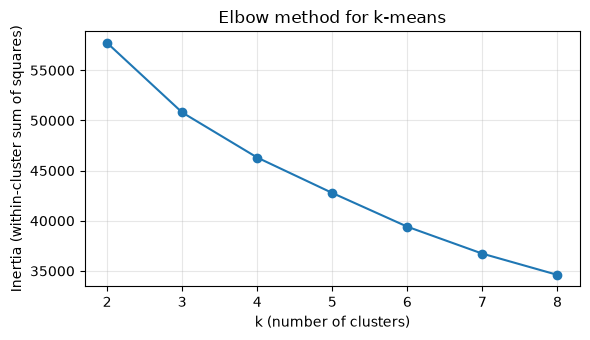

,n,churn_pct,total_trans_ct,total_trans_amt,total_revolving_bal,total_relationship_count,contacts_count_12_mon,months_inactive_12_mon,total_ct_chng_q4_q1
cluster,,,,,,,,,
A,2658,42.1,56.13,3258.58,198.38,3.71,2.90,2.65,0.62
B,3112,12.1,53.15,2778.66,1729.62,4.51,3.06,2.29,0.65
C,1240,4.0,101.99,12010.85,1424.88,2.07,2.20,2.21,0.72
D,3117,2.7,69.22,3977.61,1315.08,3.89,1.58,2.18,0.85


risk_tier,0,1,2,3+
cluster,,,,
A,184,933,1014,527
B,726,1765,589,32
C,223,879,138,0
D,1702,1239,168,8


,n,churn_pct
cluster_k3,,
1,3456,34.1
0,5035,7.1
2,1636,5.6


In [6]:
# Cell M5-14(code)|k-means 對照:標準化 → 手肘法 → 分群 → 各群輪廓 → 與矩陣風險層交叉(說明見 Cell M5-13;判讀見 Cell M5-15)(輸入對應 sql/04_segment_matrix.sql [S3])
# 本 cell 執行五段計算:
# (1) 讀取七個行為變數並算出每位客戶的旗標命中數;(2) 標準化後以手肘法選 k;(3) 以 k = 4 分群並算各群輪廓;(4) 各群與矩陣風險層的交叉表;(5) 改取 k = 3 的敏感度檢查
# 本 cell 沿用 Cell M5-4 已建立的 engine(資料庫連線)、RANDOM_STATE(= 42)、以及已匯入的 pd、np、plt、StandardScaler、KMeans

# 七個行為變數的欄位名稱(選取依據見 Cell M5-13 輸入變數 (1)),依序為:
# 交易筆數、交易金額、循環欠款(本金)、往來產品數、客服聯繫次數、不活躍月數、交易筆數變化比。全部放在一個 list 裡,之後的查詢、標準化、算平均都引用這個 list,避免七個欄位名稱重複書寫
KM_FEATURES = ["total_trans_ct", "total_trans_amt", "total_revolving_bal", "total_relationship_count",
               "contacts_count_12_mon", "months_inactive_12_mon", "total_ct_chng_q4_q1"]

# 功能:從 clean.customers 表讀取每位客戶的客戶識別碼(客戶編號)、是否流失、七個行為變數,並在 SQL 中直接算出旗標命中數
# 語法:f-string 的 {', '.join(KM_FEATURES)} 會把 list 內的七個欄位名稱用逗號接成一串,放進 SELECT 子句。hit_count 的算法與 Cell M5-4 [S1] 相同:四個條件各轉成 0/1(::int)再相加,得到 0 至 4 的命中數;ORDER BY clientnum 固定列的順序,使每次執行的資料順序相同(k-means 的結果可重現也需要這一點)。
# 「本 cell 需要旗標命中數」的原因:為了第 4 段做「k-means 的群」與「矩陣的風險層」的對照
km_df = pd.read_sql(f"""
    SELECT clientnum, is_churned, {', '.join(KM_FEATURES)},
           (total_trans_ct <= 61)::int + (avg_utilization_ratio = 0)::int
         + (total_relationship_count <= 2)::int + (contacts_count_12_mon >= 4)::int AS hit_count
    FROM clean.customers
    ORDER BY clientnum
""", engine)

# is_churned 從資料庫讀出時是布林值(True/False),轉成整數 1/0,後面才能直接用 mean() 算流失率(1 的比例)
km_df["is_churned"] = km_df["is_churned"].astype(int)
# 依旗標命中數建立風險層標籤:命中 ≥3 標為 "3+",其餘保留原數字並轉成文字("0"、"1"、"2"),與第 2 節 2.1 的四層風險軸一致。
km_df["risk_tier"] = np.where(km_df["hit_count"] >= 3, "3+", km_df["hit_count"].astype(str))  # np.where(條件, 條件成立時的值, 不成立時的值) 逐列判斷。


# 1. 標準化:每個變數減平均、除以標準差,避免距離被交易金額主導
# 語法: 「StandardScaler().fit_transform()」 執行兩件事:fit 算出七個變數各自的平均與標準差,transform 把每個值換成「(值 − 平均)÷ 標準差」。
# 輸出 X 是:「 10,127 列 × 7 欄」的數值陣列(不再是 DataFrame),每位客戶一列、七個標準化後的數字;後面所有 k-means 都以 X 為輸入
# 原因見第 1 節 1.6「為什麼要先標準化」:不標準化時,距離幾乎全由數值最大的交易金額決定
X = StandardScaler().fit_transform(km_df[KM_FEATURES])


# 2. 手肘法:k = 2..8 的群內平方和(inertia);n_init=10 取 10 組起始位置中最好的一組
# 這一行是字典推導式:k 依序取 2、3、…、8(range(2, 9) 不含 9),每個 k 建立一個 KMeans 物件並以 .fit(X) 分群,取出該次分群的 .inertia_(群內平方和,定義見 1.6),存成 {k: 群內平方和} 的字典,共七組。
# n_clusters=k 指定群數;random_state=RANDOM_STATE 固定起始位置使結果可重現;n_init=10 試 10 組起始位置取最佳(Cell M5-13 末段)
inertia = {k: KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(X).inertia_ for k in range(2, 9)}

# 把字典整理成兩欄的表:k 欄是 2 至 8,inertia 欄是對應的群內平方和(round 取整數,方便閱讀)
# 字典的值若為列表(例如:list(inertia)是[2,3,4,5,6,7,8]),Pandas 會將列表內容縱向展開,自動將各元素對齊並填入每一列中
elbow = pd.DataFrame({"k": list(inertia), "inertia": [round(v) for v in inertia.values()]})

# 新增 drop_pct 欄:相對前一個 k 的下降比例(%)。pct_change() 計算「(本列 − 前一列)÷ 前一列」,因為群內平方和是隨著 k 遞增而遞減,所以結果為負。
# 在 elbow 前面加負號,把最終結果轉成正值的下降比例(適合判讀的數字樣貌),乘 100 轉換成百分比。第一列(k=2)沒有前一列,drop_pct 為 NaN。這一欄就是 1.6「本案的數字」引用的 12.0%、8.8% 等。
elbow["drop_pct"] = (-elbow["inertia"].pct_change() * 100).round(1)     # 相對前一個 k 的下降幅度(%)
display(elbow)

# 畫手肘圖:橫軸:k、縱軸:群內平方和,每個 k 一個點並連線 ; 判讀時,觀察曲線在哪個 k 之後趨於平緩(1.6 的判斷依據)
fig, ax = plt.subplots(figsize=(6, 3.5))                     # 建立一張 6 × 3.5 吋的圖
ax.plot(elbow["k"], elbow["inertia"], marker="o")            # 折線圖(ax.plot),每個 k 標一個圓點
ax.set_xlabel("k (number of clusters)")                      # 橫軸標題:群數 k
ax.set_ylabel("Inertia (within-cluster sum of squares)")     # 縱軸標題:群內平方和
ax.set_title("Elbow method for k-means")                     # 圖標題
ax.grid(alpha=0.3)                                           # 淡色格線,方便閱讀數值點
plt.tight_layout()                                           # 自動調整邊界,避免標題與軸標籤被裁切
plt.show()


# 3. 以 k = 4 分群(選擇理由見判讀),k-means 回傳的群編號 0–3 只是演算法內部的順序,沒有意義,換 scikit-learn 版本、換種子、換電腦重跑時,同一群客戶可能被編成不同號碼(這次流失率最高的群是 2 號,下次可能是 1 號。若判讀直接寫「2 號群流失率 42%」,重跑後就對不上);因此依流失率由高到低重新命名為 A–D(流失率最高的群永遠是 A)(用「有意義的規則」取代「無意義的編號」,不論原始編號怎麼變,流失率最高的群永遠叫 A),判讀引用的名稱才不會因重跑而失效
K = 4

# fit_predict(X) :同時「完成分群」並「回傳每位客戶所屬的群編號(0、1、2、3)」,存成 cluster_raw 欄
# 這個編號是演算法內部的順序,沒有意義,且不同版本或不同種子下可能不同,所以接下來依流失率重新命名
km_df["cluster_raw"] = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=10).fit_predict(X)

# 依 cluster_raw 分組算每群的流失率(is_churned 的平均),由高到低排序,取排序後的群編號順序。例如:結果可能是 [2, 0, 3, 1],代表編號 2 的群流失率最高、編號 1 的群流失率最低
order = km_df.groupby("cluster_raw")["is_churned"].mean().sort_values(ascending=False).index

# 建立「原編號 → 新名稱」的對照字典:流失率最高的群命名為 A,其次 B、C、D
# chr(ord("A") + i) 把字母 A 的編碼加上 i(0、1、2、3)再轉回字母,得到 A、B、C、D
# label_map 結果樣貌舉例: {2: "A", 0: "B", 3: "C", 1: "D"}。
# (說明:order 是依流失率排序後的原始編號,例如 Index([2, 0, 3, 1]);enumerate 配上 i = 0、1、2、3,得到 {2: "A", 0: "B", 3: "C", 1: "D"},意思是「原編號 2 改叫 A、0 改叫 B、3 改叫 C、1 改叫 D」)
# 原編號 2 的群流失率最高改叫 A,其餘依序 B、C、D(實際原編號依執行結果而定,要實際執行才知道。可用 print(label_map) 查看)
label_map = {raw: chr(ord("A") + i) for i, raw in enumerate(order)}

# Series.map(字典) 逐列查表:把每列的 cluster_raw 值當作字典的鍵,換成對應的值(例如 2 → "A"),整欄換完存成 cluster 欄;
# 本處:依對照字典(label_map)把每列客戶的 cluster_raw 欄位從 0-3 換成 A–D,並且存成 cluster 欄;判讀與交叉表都用「cluster 欄(A–D)」這個欄位 
km_df["cluster"] = km_df["cluster_raw"].map(label_map)


# 各群輪廓表:依 cluster 分組,對每一群計算三類數字:「n」、「churn_pct」、「各個行為變數的平均值」
# (1) n: 該群人數(對 is_churned 欄數個數,size 不會受到 is_churned 是什麼值的影響) 
# (2) churn_pct: 該群流失率(is_churned 的平均,先以小數形式存放在這裡) ; 
# (3) 七個行為變數的平均值:agg 的寫法是「新欄名=(來源欄位, 統計方法)」,括號內兩者都是字串,例如 n=("is_churned", "size") 是「新增一欄 n,對 is_churned 欄數個數」。七個變數若逐一寫,是第一個變數「total_trans_ct=("total_trans_ct", "mean")」、第二個變數「total_trans_amt=("total_trans_amt", "mean")」、…共七行 (七個變數)
# 這裡改用「字典推導式」先做出 {"total_trans_ct": ("total_trans_ct", "mean"), "total_trans_amt": ("total_trans_amt", "mean"), …}(七個鍵、七個值),再在前面加 **: Python 會把字典的每個「鍵: 值」拆成一個「名稱=值」的「關鍵字參數」傳給 agg,這個效果與「逐行寫七個 名稱=(來源欄, "mean") 」完全相同,例如: total_trans_ct=("total_trans_ct", "mean") 算出 A 群 2,658 人的平均交易筆數 56.13。
# 用這種寫法是避免七個欄位名稱重複書寫,日後若 KM_FEATURES 增減變數,也不用改「**{f: (f, "mean") for f in KM_FEATURES}」這一行。
profile = km_df.groupby("cluster").agg(
    n=("is_churned", "size"),
    churn_pct=("is_churned", "mean"),
    **{f: (f, "mean") for f in KM_FEATURES},
)
profile["churn_pct"] = (100 * profile["churn_pct"]).round(1)     # 將流失率換算成百分比,取到小數點後第一位
profile[KM_FEATURES] = profile[KM_FEATURES].round(2)             # 把七個變數的平均值取到小數點後第二位,方便閱讀
display(profile)


# 4. 各群與矩陣風險層的交叉表:觀察「演算法的群」對應到「幾個旗標命中數層」
# 判讀要觀察兩件事(Cell M5-13 步驟 (4)):(1)流失率最高的 A 群是否集中在命中 2 與 3+; (2)每一群內混了幾個風險層
# 後面的 [["0", "1", "2", "3+"]] 指定欄的順序(風險由低到高),避免 crosstab 依文字排序把 "3+" 排錯位置

# pd.crosstab(列變數, 欄變數) 算每一組合的人數:列是 k-means 的群 A–D,欄是矩陣風險層 0/1/2/3+,每格是同時屬於該群與該層的人數。crosstab 做的事是「數人頭」:把每位客戶依「所屬群」與「風險層」兩個標籤分到表格的一格,數每格有幾人。

# 以本案輸出說明:A 列 184、933、1014、527 表示 A 群 2,658 人中,命中 0、1、2、3+ 個旗標的分別有 184、933、1,014、527 人(四格相加 = A 群人數);
# 「3+」欄 527、32、0、8 相加 = 567,即全體命中 3+ 的人數,其中 527 人(93%)落在 A 群。判讀依此觀察看:高風險層是否集中在 A 群(兩種方法是否抓到同一批人),以及 A 群混入多少命中 ≤1 的客戶(184 + 933 = 1,117 人,即 k-means 的區分力低於矩陣的原因)
# 這張表要觀察:矩陣的高風險層(2 與 3+)大多落在 A 群(1,014 + 527),代表兩種方法抓到同一批人;但 A 群也混入 1,117 人命中 ≤1(184 + 933),代表 k-means 的群不如矩陣乾淨,這就是第 7 節判讀判定 (2) 的依據

cross = pd.crosstab(km_df["cluster"], km_df["risk_tier"])[["0", "1", "2", "3+"]]
display(cross)


# 5. 敏感度:改取 k = 3 時,各群的人數與流失率(供判讀待辦 (1) 引用;確認「k 的選擇不改變結論方向」)
# 同樣的 X、同樣的種子、同樣的 n_init,只把群數改為 3,fit_predict 回傳每位客戶的群編號(0、1、2)
k3 = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10).fit_predict(X)

# km_df.assign(cluster_k3=k3) 把 k=3 的群編號暫時加成一欄(不改動 km_df 本身),再依「cluster_k3」欄分組,對 is_churned 算人數(size)與流失率平均值(mean),並依「各群的流失率平均值」由高到低排序;只看人數與流失率平均值,不計算七個變數的輪廓
# 只看人數與流失率、不算輪廓的原因:第 7 節的結論只依「流失率最高那群的人數與流失率」判斷(該群流失率是否遠高於全體 16.07%、是否仍遠低於矩陣命中 3+ 的 82.9%)。本案 k=3 的結果:最高群 3,456 人、34.1%(k=4 為 2,658 人、42.1%),其餘兩群 7.1%、5.6%;34.1% 仍遠高於 16.07%、仍遠低於 82.9%,故 k 取 3 或 4 結論方向相同(詳見判讀待辦 (1))。
# 詳細說明:第 7 節的結論有兩點:(1) k-means 不看流失也能分出流失率遠高於 16.07% 的群;(2) 但該群的流失率遠低於矩陣命中 3+ 的 82.9%,區分力不如矩陣。這兩點都只看「流失率最高那群的人數與流失率」就能判斷,所以不需要七個變數的輪廓。本案 k=3 的輸出:最高群 3,456 人、34.1%(k=4 是 2,658 人、42.1%),其餘兩群 7.1%、5.6%。34.1% 仍遠高於 16.07%(結論 1 成立),也仍遠低於 82.9%(結論 2 成立),所以 k 取 3 或 4,結論方向都不變。
k3_profile = (km_df.assign(cluster_k3=k3)
              .groupby("cluster_k3")["is_churned"].agg(n="size", churn_pct="mean")
              .sort_values("churn_pct", ascending=False))
k3_profile["churn_pct"] = (100 * k3_profile["churn_pct"]).round(1)     # 將流失率換算成百分比,取到小數點後第一位
display(k3_profile)

Cell M5-15(markdown)|第 7 節判讀

**第 7 節判讀|k-means 對照(待驗證事項的補充;決策日誌 [M5-4])**

**結論**:k-means 在不看「是否流失」的情況下,仍分出一群流失率 42.1% 的高風險客戶(A 群 2,658 人),且這一群涵蓋矩陣命中 3+ 的 93%、命中 2 的 53%,證明矩陣的分層是資料本身就有的結構;但 A 群混入 1,117 位命中 ≤1 的低風險客戶,流失率只到 42.1%,遠低於矩陣命中 3+ 的 82.9%,區分力不如矩陣,且群無法寫成名單條件。因此挽留名單以矩陣為準,k-means 只作旁證。<br/>

**實測**:<br/>
**手肘法**:<br/>
群內平方和從 k=2 到 k=3 下降 12.0%,到 k=4 下降 8.8%,之後每多一群下降 6% 至 8%、幅度趨於平緩;依第 1 節 1.6 的判斷依據(取降幅最後一次明顯高於之後各步的 k),**取 k=4**(轉折點的判斷有主觀成分,若取 k=3 亦屬合理,見待辦 (1))。<br/>

**各群輪廓(Cell M5-14 profile 表;標示「最高」「最低」者為該變數在四群中的極值,即該群的特徵)**:<br/>

| 群 | 人數 | 流失率 | 交易筆數 | 交易金額 | 循環欠款(本金) | 往來產品數 | 聯繫次數 | 不活躍月數 | 交易筆數變化比 |
|---|---|---|---|---|---|---|---|---|---|
| A | 2,658 | 42.1% | 56.1 | 3,259 | 198(最低) | 3.71 | 2.90 | 2.65(最高) | 0.62(最低) |
| B | 3,112 | 12.1% | 53.2(最低) | 2,779(最低) | 1,730(最高) | 4.51(最高) | 3.06(最高) | 2.29 | 0.65 |
| C | 1,240 | 4.0% | 102.0(最高) | 12,011(最高) | 1,425 | 2.07(最低) | 2.20 | 2.21 | 0.72 |
| D | 3,117 | 2.7% | 69.2 | 3,978 | 1,315 | 3.89 | 1.58(最低) | 2.18(最低) | 0.85(最高) |

特徵的挑選標準:只列「該群」「在四群中」為「最高或最低的變數」,避免分析者主觀挑選。<br/>
補充說明:實務上描述群的輪廓,標準是「這個變數在這一群的平均值,與其他群相比是否明顯不同」;較不主觀的做法是「列出該群在四群中數值最高或最低的變數」。<br/>


**四群依流失率排序**:<br/>
**A 群 2,658 人、流失率 42.1%**: 循環欠款本金最低(198 元)、不活躍月數最高(2.65)、交易筆數變化比最低(0.62)。<br/>
**實務意義**:不用循環信用、近一年不活躍、第四季筆數相對第一季減少最多,與四個旗標中的「零動用、低活躍」方向一致。<br/>
對分析師而言:演算法在沒有旗標定義下找到的高風險群,特徵與 M2 定義的旗標重疊,驗證旗標的方向正確。<br/>
對業務單位而言:這一群是矩陣命中 ≥2 的主體(527 + 1,014 = 1,541 人,占 A 群 58%),即挽留名單的主要對象,但名單仍依矩陣的格圈選,不直接用 A 群。<br/>

**B 群 3,112 人、12.1%**: 循環欠款本金最高(1,730 元)、往來產品數最高(4.51)、聯繫次數最高(3.06)、交易筆數與金額最低。<br/>
**實務意義**:用卡少,但有循環欠款與多項產品綁住,流失率不高。<br/>
對分析師而言:支持「有循環欠款者較不易流失」,與零動用旗標的方向一致,也支持第 4 節 4.2 對零動用客戶「建立持續往來(分期方案等)」的行動方向。<br/>
對業務單位而言:這一群不需投放挽留資源,但聯繫次數是四群最高(3.06),客服聯繫多屬服務品質議題,應另行處理。<br/>

**C 群 1,240 人、4.0%**: 交易筆數與交易金額最高(102 筆、12,011 元)、往來產品數最低(2.07)。<br/>
**實務意義**:高消費但只往來 1 至 2 項產品,目前風險低。<br/>
對分析師而言:k-means 獨立找到這一群,是深化區動作的佐證(判定 (3))。<br/>
對業務單位而言:是第 4 節深化區「交叉銷售」的對象,不需挽留。<br/>

**D 群 3,117 人、2.7%**: 聯繫次數最低(1.58)、不活躍月數最低(2.18)、交易筆數變化比最高(0.85)。<br/>
**實務意義**:活躍、少聯繫客服、消費金額持平,是最穩定的客群。<br/>

**交叉表**:「A 群」涵蓋「命中 3+ 的 567 人」中的「527 人(93%)」與「命中 2 的 1,909 人」中的 「1,014 人(53%)」;其餘三群大多落在命中 ≤1(B 群 80%、C 群 89%、D 群 94%),與其低流失率相符。本節只細看 A 群,因為 k-means 這節要回答的問題是「演算法的高風險群與矩陣的高風險層是否重疊」。<br/>



**判定**:<br/>
(1) k-means 在完全沒看「是否流失」這個欄位(機器學習稱為標籤)的情況下,分出來的 A 群流失率 42.1%、D 群流失率 2.7%,顯示 **結論:「行為變數本身就帶有與流失相關的結構」**,因為:演算法只依「客戶彼此像不像」分群,分出的群在流失率上仍有明顯差異。<br/>
(2) 但 A 群的流失率 42.1% 只相當於矩陣「命中 2」層的水準(36.7%),遠低於「命中 3+」層的 82.9%;矩陣 12 格的流失率範圍是 0% 到 88%(差距 88 個百分點),k-means 四群的範圍是 2.7% 到 42.1%(差距 39.4 個百分點,第 1 節 1.6)。原因是: k-means 依七個變數的整體相似度分群,**A 群 2,658 人中除了命中 3+ 的 527 人與命中 2 的 1,014 人,還混入 1,117 人命中 ≤1 的低風險客戶(交叉表 184 + 933),群的平均流失率被拉平**;**矩陣用「已驗證的四個旗標直接分層」,區分力更強**。<br/>
(3) **C 群(1,240 人,交易金額最高、往來產品數最低、流失率 4.0%)**對應**矩陣的深化區(高價值 × 命中 ≤1)**:<br/>
交易金額高即「高價值層」;往來產品數 ≤2 項就是「淺關係旗標」,所以「產品數最低」即淺關係;交叉表顯示 C 群 1,102 人(223 + 879,占 89%)命中 ≤1,即「低風險(流失率低)」。<br/>
深化區中人數最多的「1 × 高」格(1,695 人)淺關係占 66.8%、流失率 6.43%(第 4 節 4.1),與 C 群輪廓相同。
**細節說明**: C 群的三個特徵是「交易金額最高、往來產品數最低、流失率只有 4.0%」。對到矩陣的語言:交易金額高 = 高價值層;往來產品數 ≤2 就是淺關係旗標,所以「產品數最低」= 淺關係;流失率低 = 命中 ≤1(交叉表 C 群 89% 命中 ≤1)。「高價值 × 命中 ≤1」正是深化區,而深化區裡人數最多的 1 × 高 格,淺關係占 66.8%、流失率 6.43%,與 C 群的輪廓相同。<br/>
**實務意義**:k-means 在沒有任何旗標定義的情況下,也把「高消費、淺關係、低流失」的客戶自動聚成一群,代表「深化區是真實存在的客群」,不只是分析者用規則切出來的,表示**第 4 節對深化區客戶設計「交叉銷售、深化往來」的動作,有獨立的資料支持**。<br/>

**其他**:判定只列出「回答 Cell M5-13 兩個問題」所需的證據:判定 (1)(2) 回答「群與流失的關係多強」,判定 (3) 為矩陣分區的獨立佐證;「能否寫成名單條件」在意涵 (2) 回答。其他現象留在實測的輪廓描述,不列為判定。<br/>
細節說明:判讀是由假設驅動的:Cell M5-13 先列出本節要回答的兩個問題,判定就只寫「回答這兩個問題所需的證據」。判定 (1)(2) 回答問題一(群與流失的關係多強:有關,但弱於矩陣);判定 (3) 是額外的獨立佐證(演算法與矩陣對深化區看法一致);問題二(能否寫成條件)在意涵 (2) 回答。其他現象(例如 B 群循環欠款高但流失低)與兩個問題無直接關係,放在實測的輪廓描述即可,不列為判定。<br/>



**對決策的意涵**(「C3-b 規則」和「k-means 分群」這兩種方法的適用情境):<br/>
(1) **規則式矩陣適合本案這種「已經知道哪些訊號與流失相關(本案目標)、且分群結果要直接交給業務單位執行」的情境**:<br/>
每一格有「明確定義、能寫成名單條件、能維護(規則只依欄位定義,欄位不變規則就不變,業務單位每季自行重算命中數即可,不需分析者介入)」;矩陣的區分力(流失率 0% 到 88%)也優於 k-means(2.7% 到 42.1%):差距越大,代表分出的組在流失率上分得越開,高風險組的流失者越集中,挽留資源投在該組時投中流失者的比例越高。<br/>

(2) **k-means 適合「還不知道訊號、想先看客群有沒有自然結構」的探索階段,或「沒有目標變數」的情境(例如:新產品上線前的客群輪廓)**:<br/>
k-means 分的群無法直接寫成規則(「A 群」的定義是「離 A 群中心最近」,業務單位無法據此圈人),要用於名單必須「再把群翻譯成規則」,等於回到規則式。<br/>
(「目標變數」指:「要預測的答案欄位」(本案的目標變數是 is_churned)。<br/>
例如:新產品上線前,還沒有客戶買過,資料裡沒有「誰會買」這一欄,無法用規則或模型找「會買的人的特徵」;只能先依既有行為把客戶分成幾種輪廓,決定先對哪一種輪廓推廣,推廣後再量測實際購買的結果)。<br/>

(3) **本案的結論:k-means 驗證了「行為變數本身就帶有流失結構」,但「名單仍以矩陣為準」**;k-means 的結果不進名單,只作為「演算法分群與規則式分群結論一致」的旁證。<br/>
「結論一致」指:k-means 流失率最高的 A 群集中了矩陣的高風險層(命中 3+ 的 93%、命中 2 的 53%) ; 流失率最低的 D 群 94% 落在命中 ≤1 ; C 群對應深化區;亦即「演算法分出的高、低風險群,與矩陣的高、低風險層落在同一批人身上」。<br/>
**實務意義**:<br/>
向業務單位說明矩陣時,可用這個對照回答「為什麼不用演算法分群」:演算法在不看流失的情況下,分出的高、低風險群與矩陣的高、低風險層落在同一批人身上(上述數字),代表 **「矩陣的分層不是分析者主觀設定,而是資料本身就有的結構」;而「矩陣的每一格能寫成名單條件、區分力也更強」,所以名單以矩陣為準**。<br/>


**待辦或限制**:<br/>
(1) **k 的選擇有主觀成分,但不影響本節結論**:<br/>
Cell M5-14 第 5 段改取 k=3 的結果:流失率最高的一群為 3,456 人、34.1%(k=4 的 A 群為 2,658 人、42.1%),其餘兩群流失率分別為 7.1%、5.6%。
k=3 的 A 群流失率 34.1% 仍遠高於全體 16.07%,表示「各群流失率仍明顯不同」。<br/>
若依 k-means 的群投放挽留資源,投放在 A 群仍能投到流失密度為全體兩倍的客戶(34.1% ÷ 16.07% ≈ 2.1,即 A 群每 100 人約 34 位會流失,全體每 100 人約 16 位)(判定 (1) 成立); A 群流失率 34.1% 也仍遠低於「矩陣命中 3+」這區的流失率 82.9%,表示「A 群混入的低風險客戶仍多」,「A 群內流失者的集中度」不如「矩陣命中 3+ 這區內流失者的集中度」(判定 (2) 成立)。<br/>
**結論方向不變**:**k-means 的分群與流失有關,但區分力低於矩陣**。<br/>

(2) **k-means 對極端值敏感,交易金額右偏可能使分群結果偏差;本案不處理,因 k-means 只作對照、不進名單**:<br/>
k-means 把每位客戶分到「與其的直線距離最近的群中心」,群中心是該群客戶在七個變數上的平均位置;平均值的特性是「會被少數極端值拉走」(例如 10 位客戶年消費各 3,000 元、1 位 30,000 元,平均 5,455 元)。本案交易金額右偏(Cell M5-4 價值層邊界表:低、中兩層各只跨約 2,000 元,高價值層卻從 4,476 元延伸到 18,484 元,即少數客戶交易金額極高),含這些交易金額極高的少數客戶的群,群中心會被往高金額方向拉,原本靠近群中心的中等消費客戶因此距離變遠,可能被改分到別群。<br/>
標準化只把各變數的尺度拉齊,極端值仍是極端值;常見處理是「先對交易金額取對數(壓縮極端值與一般值的差距)」再分群。本模組不處理這個問題,僅在此列出此問題與限制,因為 k-means 在本案只作對照,不影響名單。<br/>
**細節說明**:<br/>
k-means 分群的依據是「每位客戶到各群中心的直線距離」,離哪個群中心最近就歸哪群;群中心是該群客戶在七個變數上的平均位置。平均值的特性:少數極端值會把平均值拉走,例如 10 位客戶年消費各 3,000 元、1 位 30,000 元,平均是 5,455 元,平均值就是被 30,000 那一位拉高了。本案交易金額右偏(少數客戶交易金額極高),含這些客戶的群,群中心會被往高交易金額方向拉;原本離群中心很近的中等消費客戶,距離因此變遠,可能被改分到別群,如此分群結果就會不準。「標準化」只是把各變數的尺度拉齊,但把 30,000 元標準化後仍是極端值;常見做法是先取對數(把 3,000 與 30,000 的差距壓小)再分群。<br/>


(3) **群的編號不固定,判讀一律以 A–D 稱呼**:k-means 回傳的群編號在「不同 scikit-learn 版本或不同種子」下可能不同,本 notebook 依流失率重新命名為 A–D(Cell M5-14 第 3 段),判讀與第 8 節引用時以 A–D 為準,不引用原始編號。<br/>

Cell M5-16(markdown)|第 8 節:M5 結論

## 第 8 節|M5 結論:名單方案總表

| 優先 | 策略區 | 格<br/>(命中 × 價值) | 名單條件 | 人數 | 流失者 | 流失率 | 動作 | 成本層級 | 效益<br/>(成功率 20%;留住人數 = 流失者 × 0.2,第 1 節 1.5 公式 1) |
|---|---|---|---|---|---|---|---|---|---|
| 1 | 搶救區 · 命中 3+ | 「3+ × 高」 | 命中 ≥3<br/>且<br/>交易金額 ≥ 4,476 元 | 50 | 44 | 88.0% | 客戶經理於名單交付後一週內聯繫(本格「每人可避免的損失」最高(≈ 5,740 元),所以優先順序排第 1;<br/> 50 人由 1 位客戶經理一週內可聯繫完,第 3 節意涵 1 ); <br/>推薦一項適合產品(淺關係 86.0%)+ 分期零利率(零動用 94.0%)+ 個人化消費回饋(低活躍 82.0%),三項各對應本格一個主要旗標的 4.2 表做法 ;<br/>「淺關係且低活躍」者(占本格 68.0%)最優先(待驗證事項 #21) | 人工、高 | 留住約 9 人(44 × 0.2 = 8.8 ≈ 9),本格每人年消費平均為 6,520 元 |
| 2 | 搶救區 · 命中 2 | 「2 × 高」 | 命中 = 2 且<br/>交易金額 ≥ 4,476 元 | 376 | 119 | 31.7% |客戶經理於名單交付後一個月內聯繫(376 人以 2 至 3 位客戶經理、每人每週 30 至 50 位估算,第 3 節意涵 1),<br/>採取動作內容同上(本格零動用 85.6%、淺關係 81.4%;低活躍僅 15.2%,個人化消費回饋只對命中低活躍者執行);<br/>「淺關係且低活躍」者同樣最優先 | 人工、中 | 留住約 24 人(119 × 0.2 = 23.8 ≈ 24),本格每人年消費平均為 8,118 元 |
| 3 | 低成本區 · 命中 3+ | 「3+ × 中」、<br/>「3+ × 低」 | 命中 ≥3<br/>且<br/>交易金額 < 4,476 元 | 517 | 426 | 82.4% | 自動化:分期推送(零動用 94.3% / 88.1%)+ 滿額回饋(低活躍 100%)+ 推播推薦一項標準產品(淺關係 53.3% / 56.6%)+ 高聯繫者客服優先處理(60.0% / 70.4%);<br/>消費變化比 < 0.50 者改發額外回饋版本(與第 4 列合計 308 人,Cell M5-9 extra_reward 表);<br/>聯繫 ≥5 次者人工回訪(聯繫 5 次以上的客戶多半有尚未解決的爭議,自動標記無法處理,須由人了解原因並補救(4.2 高聯繫旗標的「服務補救」;待驗證事項 #10-a 的更嚴門檻);符合者只占低成本區 7.5%,人力可負擔)<br/>(說明:本列兩格(3+ × 中、3+ × 低) 的四個旗標占比都 ≥50%(低活躍 100%、零動用 94.3% / 88.1%、淺關係 53.3% / 56.6%、高聯繫 60.0% / 70.4%),所以四個行動方向都進整格動作) | 自動化、低 | 留住約 85 人(426 × 0.2 = 85.2 ≈ 85),本列每人年消費平均 2,076 元(「3+ × 中、3+ × 低」這兩格加權:(412 × 1,844 + 105 × 2,987)÷ 517 ≈ 2,076 元) |
| 4 | 低成本區 · 命中 2 | 「2 × 中」、<br/>「2 × 低」 | 命中 = 2<br/>且<br/>交易金額 < 4,476 元 | 1,533 | 582 | 38.0% | 自動化:滿額回饋(本列兩格的主要旗標只有低活躍:2 × 中 68.4%、2 × 低 99.8%)<br/>(低活躍對應「促進使用」的批次做法就是滿額回饋);<br/>消費變化比 < 0.50 者改發額外回饋版本(與第 3 列合計 308 人);<br/>預算不足時低價值 1,093 人可先暫緩投放挽留資源 | 自動化、低 | 留住約 116 人(582 × 0.2 = 116.4 ≈ 116),本列每人年消費平均 2,244 元(兩格加權:(1,093 × 1,799 + 440 × 3,350)÷ 1,533 ≈ 2,244) |
| 5 | 深化區 | 「1 × 高」、<br/>「0 × 高」 | 命中 ≤1<br/>且<br/>交易金額 ≥ 4,476 元<br/>且<br/>往來產品 ≤2 項 | 1,132<br/>(只有算「收到交叉銷售動作的 1,132人(不是深化區全區的 2,949 人)」:深化區「1 × 高」格有 1,695 人,只對其中的「命中淺關係旗標者約 1,132 人」做交叉銷售:<br/>「1 × 高」格淺關係占 66.8%(1,695 × 66.8% ≈ 1,132 人);<br/>「0 × 高」格 1,254 人,皆無旗標,不投放) | 144(深化區全區;深化區的動作目的是深化而非挽留,流失者人數不作為本列的效益依據)<br/>(因為這一列的人數 1,132 是「1 × 高」格內命中淺關係者,本 notebook 沒有單獨算這 1,132 人的流失者) | 4.9%(深化區全區) | 交叉銷售一項產品(淺關係旗標的行動方向,4.2 表;第 3 節意涵 3)<br/>(淺關係旗標的行動方向是深化往來(4.2 表;M3 T2 往來 ≤2 項流失率 26.89% 對 ≥3 項 13.14%;M4 模型 B 每多一項產品流失勝算約降為 0.63 倍),而這一群年消費高(8,441 元),是最有能力多用一項產品的客戶(第 3 節意涵 3)) | 自動化、低<br/>(4.2 表高價值層的人工做法僅用於挽留名單)<br/>(原則:人工資源只用於「高價值層」的「挽留動作」,所以人工保留給搶救區客戶。深化區雖為高價值層,但深化動作並非挽留動作,採取自動化即可) | 動作目的是深化而非挽留,效益以「產品滲透率(目標客群中持有某產品的客戶比例)」衡量(產品滲透率 = 持有該產品的客戶數 ÷ 目標客群人數;例如:對 1,132 人推廣自動扣繳,三個月後 150 人辦理,滲透率 13.2%) |
| — | 監測區 | 「1 × 低」、<br/>「1 × 中」、<br/>「0 × 中」、<br/>「0 × 低」 | 命中 ≤1<br/>且<br/>交易金額 < 4,476 元 | 4,702 | 312 | 6.6% | 不投放挽留資源,每季重算此區每個客戶的旗標命中數,監測是否需移入其他策略區<br/>(例如:升到 2 以上者依其價值層移入搶救區或低成本區) | —<br/>(不投放,無投放成本)(沒有投放成本,也沒有「留住人數」可估;每季重算命中數是系統例行作業,不另計成本) | —<br/>(不投放,無挽留效益) |

**五個結論**:
1. **名單門檻**:<br/>
以「矩陣分層」取代單一門檻。作法:以「命中 ≥2 的客戶」為名單範圍(2,476 人,涵蓋 72% 的流失者),「命中 3+ 」與「高價值層」優先投放;若預算不足,先暫緩投放「低成本區的命中 2 × 低價值(1,093 人)」,此時挽留名單縮減至 1,383 人仍能涵蓋 43% 的流失者(1,171 − 465 = 706 人)。<br/>

2. **C3-b 規則為預設的圈選方式,模型 B 為升級版圈選方式**:<br/>
挽留名單以「四旗標命中數的 C3-b 規則」圈選,業務單位可自行執行與維護;模型 B 維護成本較高,但可以讓「同規模名單每留住一人的成本降低 17.4%」,因此,「當每期投放總成本 × 17.4% 超過模型維護成本時」就切換圈選方式為模型 B。<br/>

3. **動作是 M6 實驗的候選方案**:<br/>
每一格的動作都是依關聯(例如淺關係客戶流失率高,所以對他們做交叉銷售)設計(但無法證明因果,並非已驗證的結論),「動作是否有效」則須由 M6 驗證;建議 M6 的第一個實驗選擇「搶救區或低成本區命中 3+(流失率最高、效果最容易測到)」,主指標為「投放後一季的流失率」。<br/>

4. **額外回饋子群**:<br/>
「消費變化比」不作為名單條件,改作為低成本區「額外回饋」的觸發條件:低成本區中,消費變化比 < 0.50 的 308 人(精確率 72.4%,每留住一人的成本 6.9 倍) 改發「加碼版回饋」(第 5、6 節)。<br/>

5. **分群方法的旁證**:<br/>
k-means 在不看「是否流失」這個標籤(欄位)的情況下,分出的「流失高風險群」涵蓋「矩陣命中 3+ 層客戶的 93%」,證明「矩陣的分層不是分析者主觀設定,而是資料本身就有的結構」,而「矩陣的每一格能寫成名單條件(k-means 無法)、區分力也更強」,所以名單以矩陣為準。(k-means 的區分力(2.7% 至 42.1%)低於矩陣的區分力(0% 至 88%))<br/>

**這一節回答的問題**:本案的分析最後「給了什麼建議」、「怎麼排優先順序」、「預期效果是多少」、「還有什麼不確定」。<br/>
以上四個問題的答案都在「名單方案總表」與「五個結論」裡,而且「每個數字都能回溯至 M2 至 M4 的 notebook 內容」。<br/>

**本 notebook 各節架構與結論**(與 Cell M5-1 的 Roadmap 對應):<br/>
| 節 | 做的事 | 關鍵結論(數字) |
|---|---|---|
| 2 | 定義兩軸 | 風險軸:命中 0 / 1 / 2 / 3+,流失率 1.3% / 8.7% / 36.7% / 82.9%;價值軸:三分位,邊界 2,567 元、4,476 元;規則為預設、模型 B 為升級選項 |
| 3 | 12 格矩陣 | 搶救區 426 人(流失率 38.3%、年消費 7,930 元)、低成本區 2,050 人(流失率 49.2%、年消費 2,202 元,低成本區的流失者占全體流失者 的 62%)、深化區 2,949 人(流失率 4.9%)、監測區 4,702 人(流失率 6.6%);高風險客戶集中在低價值層 |
| 4 | 每格動作與優先順序 | 三層級動作架構;六格依「流失率 × 年消費」排序(3+ × 高 ≈ 5,740 元最優先);人工挽留資源只用於搶救區客戶 ; 所有動作為假設性方案 |
| 5 | H3 門檻定位 | 連續效應,無「資料決定的門檻」;「消費變化比」不作名單條件,只作為「低成本區額外回饋觸發」(低成本區內,消費變化比 < 0.50 的 308 人、精確率 72.4%) |
| 6 | 成本效益試算 | 成功率 20% 時每留住一人的成本:「命中 ≥3 名單」為 6.0 倍、「命中 ≥2 名單」為 10.6 倍;名單範圍取「命中 ≥2(能涵蓋 72% 的流失者)」;模型 B 較規則節省 17.4% 成本,升級使用模型 B 的切換條件為:當「每期投放總成本 × 17.4% > 模型維護成本」時,改用模型 B |
| 7 | k-means 對照 | A 群流失率 42.1%、涵蓋命中 3+ 層客戶的 93%; k-means 區分力 2.7% 至 42.1% ,低於矩陣區分力 0% 至 88%;圈選名單方式以矩陣為準 |
| 8 | 名單總表 | 命中 ≥2 共 2,476 人,人工 426 人、自動化 2,050 人;預算不足時暫緩投放 1,093 人,仍能涵蓋到 43% 的流失者 |

Cell M5-17(markdown)|第 9 節:方法限制

## 第 9 節|方法限制

1. **價值軸是代理變數,且對流失客戶會有「系統性低估」**:<br/>
交易金額不是利潤。<br/>
而且行為欄位是近 12 個月的彙總值,中途流失的客戶因使用期間縮短,交易金額偏低,部分應屬搶救區的客戶可能因此被歸入低成本區。搶救區的實際規模可能大於 426 人;有時間戳記的資料才能以流失前的正常消費計算客戶價值。<br/>
若銀行的利潤主要來自循環利息,價值軸應改用循環欠款(本金),客戶的價值層就會重新分配,此時四區人數與第 6 節判定 (2) 的比較都須重算(第 6 節待辦三)。<br/>

2. **動作是依關聯設計的假設性方案**:<br/>
每個動作都建立在「有這個旗標的客戶流失率高」這種關聯上,但每一個動作都未經過因果驗證。例如:對淺關係客戶交叉銷售,前提是「往來產品多,就能降低流失」,但也可能實際情況是「不打算流失的客戶,才願意多辦產品」;「前述這兩種可能的因果關係」實際上是哪個成立,只有 M6 的隨機分組實驗能回答。本模組的動作表是實驗的候選方案,不是已驗證的策略。<br/>

3. **效益試算建立在兩個假設參數上**:<br/>
「挽留成功率」與「每人投放成本」在本資料集裡都沒有,試算表只能得出「每留住一人要花幾倍的每人投放成本」的這種相對比較,無法得出「絕對金額」;M6 實驗的產出之一就是「把成功率量出來」。
此外,試算把各方案的每人投放成本都當作 1 單位,但搶救區(人工成本)與低成本區(自動化成本)的實際成本相差很大,因此換算投入成本的實際金額時,兩區須各自乘上「該方案的每人投放成本」,才能公平地比較(第 6 節待辦四)。<br/>

4. **價值層使用等份切法,其邊界是由資料決定**:<br/>
價值層邊界 2,567 元與 4,476 元是「這一萬名客戶的三分位」,若更換一批客戶,價值層邊界就會跟著改變。<br/>
本模組的目的是在「這一批資料上」排出投放優先順序、比較四個策略區,等份切法在這個目的下最公平;若 M8 之後要把價值層變成長期規則,再將做法改為「固定金額」。並且必須定期檢視「這個固定金額切出來的三層人數比例是否仍接近原本的三等份均分人數比例」,因為客戶組成或消費水準改變後,同一個金額對應的人數比例會改變,若無定期檢視,就會讓高價值層越來越大或越來越小。<br/>

5. **k-means 的限制**:<br/>
k 的選擇有主觀成分(k=3 時,結論方向不變);k-means 對極端值敏感,交易金額右偏時,群中心會被往高金額方向拉,導致分群結果可能偏差;本模組只用 k-means 作為對照,不用於實際圈選名單,因此只列出限制,不針對此問題做處理。<br/>

6. **未檢視名單的公平性**:<br/>
矩陣的兩個軸都是「行為欄位」(風險軸的四個旗標用「交易筆數、額度動用率、往來產品數、客服聯繫次數」;價值軸用「交易金額」),沒有使用性別、年齡等人口屬性變數(M2 假設樹的屬性枝、M4 模型 B 中的人口屬性)。但問題是:沒有使用人口屬性變數,「不代表名單就與人口屬性變數無關」: M4 模型 B 顯示控制其他變數後,女性的流失勝算是男性的 2.12 倍,表示「女性較常落在高風險層」,矩陣依行為分層後,搶救區或低成本區的女性比例就可能高於全體;若挽留資源依這份名單分配,某一性別或年齡組得到的資源就會偏多或偏少,可能構成差別待遇。<br/>
本模組未檢查四個策略區的「性別與年齡組成」,交由 M7 檢視(待驗證事項 #29)。<br/>

7. 判定是否為「主要旗標」的門檻是「在該格中命中比例 ≥ 50%」,並依此門檻設計「各格應採取哪些動作組合」。以上是本模組自訂的操作慣例,不是「根據資料決定的最佳切點」;若換一批客戶,各格旗標占比就可能跨越 50%,此時動作組合就須重新檢視。(Cell M5-8 4.3 表格說明)<br/>

8. **模型 B 的節省比例 17.4% 這個數字,只適用於「名單範圍為命中 ≥2」的情形;若名單範圍改變(例如:M4另一個規模是命中≥3,178 人),切換條件中的比例就必須重算**:<br/>
17.4% 是在 M4 測試集 703 人(對應命中 ≥2)下量測出的結果;當名單規模改變時,C3-b 規則與模型 B 的「精確率差距」也會不同(178 人規模為 6.3%),切換條件就必須在對應的規模下重新計算(第 6 節待辦二)。<br/>
「第 6 節待辦二」細節說明:M4 在命中 ≥3 的規模(178 人)量到的「精確率」是:C3-b 規則 84.27%、模型 B 89.89%,兩者的精確率差距是 5.6 個百分點,使用模型 B 的節省比例為 1 − 84.27 ÷ 89.89 ≈ 6.3%。由此可見,當名單規模越小,C3-b 規則挑到的本來就是「最明顯的高風險客戶」,相對的,模型 B 能比 C3-b 規則多挑對的空間就越小。因此,若日後名單範圍改為命中 ≥3 (名單規模變小),切換條件應為「每期投放總成本 × 6.3% > 模型維護成本」,就不會使用 17.4% 這個數字;同理,其他名單規模也須在該名單規模下重新計算切換條件(如本處舉例所示的算法)(notebook 04 第 7 節待辦 2)。<br/>

9. **消費變化比的欄位定義為推斷**:<br/>
total_amt_chng_q4_q1 依欄位名稱推斷為「Q4 ÷ Q1」,本案的官方資料集未提供這兩季的原始金額,因此無法驗證此欄位是否確實為「Q4 ÷ Q1」(決策日誌 [M2-4]);<br/>
第 5 節的分箱、流失率與名單人數都直接由欄位數值算出,不受此欄位定義是否正確影響,但若要說明「第四季消費不到第一季的一半」的業務描述以及「據此設計的額外回饋動作的理由」(「這些客戶在業務上是什麼樣的人」的描述,以及據此設計的動作是否還合理。例如:若欄位其實不是 Q4 ÷ Q1,「對消費減少的客戶放寬回饋門檻」的理由就要重新檢視),就必須在取得兩季原始金額真實資料後,驗證定義並重新檢視驗證結果(第 5 節待辦 (1))。<br/>
實務意義: 這是「欄位定義風險」,實務上當資料集不完整時,都會這樣標註。這個「欄位定義風險」不會改變第 5 節的結論,但會影響對業務單位的說法。<br/>

Cell M5-18(markdown)|第 10 節:待驗證事項清單 v6 與 M6 開工檢核

## 第 10 節|待驗證事項清單 v6(M5 收尾定版)

**定位**:承接 notebook 04 Cell M4-21 的待驗證事項清單 v5,回填本模組承接的 #9、#10-a、#17、#21、#22、#25、#26、#11(M5 部分),並新增本模組產生的待辦事項(#28 至 #32)。待辦事項的編號沿用先前版本,不另重編; v5 的其餘項目(本模組未處理的事項)則原文照抄。<br/>

**本模組結案的項目**:<br/>

| # | 事項 | 結案結果 | 依據 |
|---|---|---|---|
| 9 | 挽留名單門檻(命中旗標數 ≥2 或 ≥3)依預算與成本效益定案 | ✅ 完成:以矩陣分層取代單一門檻。命中 ≥2 為名單範圍(2,476 人,涵蓋 72% 流失者),命中 3+ 與高價值層優先,人工聯繫只用於搶救區 426 人,預算不足時先暫緩命中 2 × 低價值(1,093 人);每留住一人的成本(假設成功率 20%):命中 ≥3 為每人投放成本的 6.0 倍、命中 ≥2 為 10.6 倍 | notebook 05 第 6 節判讀、第 8 節 |
| 10-a | 高聯繫預警線位置(現為 ≥4 次的工作預設值)依成本效益定案 | ✅ 完成:旗標定義維持 ≥4 次(與 M2–M4 一致);動作層加一條「聯繫 ≥5 次者不分價值層一律人工回訪」(搶救區 5.9%、低成本區 7.5% 的客戶符合「聯繫 ≥5 次」的條件) | notebook 05 第 4 節 4.2 |
| 17 | H3 消費變化比的門檻位置 | ✅ 完成:流失率隨消費變化比連續下降(0.40–0.60 每 0.05 一箱為 38% → 29% → 23% → 16%),判定為「連續效應」而非門檻效應(修正 notebook 02 階段 B 的「門檻效應」判讀),無「資料決定的門檻」;消費變化比不作為名單條件,改作為「低成本區的額外回饋觸發」:觸發線取 0.50(低成本區中變化比 < 0.50 的 308 人、精確率 72.4%),不取 0.60(641 人、61.6%),理由是:加碼回饋為額外支出,先以較小名單控制成本;此為依「名單人數(成本)」與「名單流失率(精確率)」的取捨,非資料決定的門檻(第 5 節意涵 (2) c) | notebook 05 第 5 節判讀 |
| 21 | M5 名單條件應為「淺關係且低活躍」,不以「淺關係」單獨成立 | ✅ 完成:「淺關係且低活躍」寫入搶救區動作的最優先順序;搶救區 16.0%、低成本區 23.4% 的客戶符合此組合。v5 建議的「以 T2 信賴區間下限 11.74 個百分點做保守估計」未採用,因本模組的效益估算改用情境試算(成功率 10%、20%、30%,第 1 節 1.5),不以單一變數的流失率差距估算 | notebook 05 第 4 節 4.3 |
| 22 | M5 價值軸以 total_trans_amt 分高、中、低價值層,切點由 M5 定案 | ✅ 完成:三分位,邊界 2,567 元與 4,476 元;「代理變數的系統性低估」寫入第 2 節 2.2 與第 9 節限制 1 | notebook 05 第 2 節 2.2 |
| 25 | M5 名單圈選方式在「規則」與「模型 B 機率分數」之間選擇 | ✅ 完成:規則為預設,模型 B 為升級選項;切換條件:若「每期投放總成本 × 17.4% > 模型維護成本」則升級使用模型 B ; 17.4% 這個切換條件僅適用命中 ≥2 的名單規模,若名單規模改變就須重算切換條件數字(第 6 節待辦二) | notebook 05 第 2 節 2.1、第 6 節判讀 |
| 26 | 零動用與高聯繫為獨立條件;四旗標勝算比排序可作加權依據 | ✅ 完成:(a) 風險軸不加權(第 2 節 2.1:M4 模型 A 的加權版與等權重版名單在測試集的名單品質相當,178 人名單 86.5% 對 84.3%,因此決定風險軸不加權);勝算比排序(低活躍 21.4 > 零動用 6.0 > 淺關係 5.1 > 高聯繫 4.4)只用於「客戶同時命中兩個旗標、只能先做一種動作時」的動作優先序排序(第 2 節 2.1);(b) 零動用與高聯繫在 4.2 動作表各自一列、各有行動方向(分別是「建立持續往來」、「服務補救」),客戶只要命中該旗標即觸發,不要求同時低活躍,即「獨立條件」(第 4 節 4.2) | notebook 05 第 2 節 2.1、第 4 節 4.2 |
| 11(M5 部分) | 「調高額度」不得直接列為挽留手段 | ✅ M5 部分完成:第 4 節 4.2 表後明列三個理由:(1) notebook 02 C4 的兩種機制(a.額度不足造成不便,或b.額度低只是關係淺的痕跡)無法區分是哪種機制;(2) M4 模型 B 同時控制全部 27 個變數後,「信用額度這個變數不顯著」(勝算比 0.94、p = 0.32),其中關鍵是控制了代表關係深度的往來產品數與循環欠款本金,結果與「機制 b :額度只是關係淺的痕跡」相容;(3) 授信額度屬風險控管,非行銷單位可單獨決定。因此 12 格動作表中無任何一格使用「調高額度」的動作。M6 部分保留:「調高額度能否降低流失」仍未驗證,若業務單位日後要採用「調高額度」作為挽留手段,須先由 M6 以隨機分組實驗(一組有調高額度、一組不調高額度,比較投放後一季的流失率)驗證有效,才能採用 | notebook 05 第 4 節 4.2 |

**待驗證事項 #11(M5 部分)的細節說明**:<br/>
模型 B 是同時控制全部 27 個變數,不只控制往來深度。4.2 特別點出「往來產品數與循環欠款本金」,是因為 notebook 02 C4 的機制 (b) 主張「額度低只是關係淺的痕跡」:若把代表關係深度的變數控制住之後,額度仍然顯著,代表額度本身有效果(與機制 (a) 相容);但最後結果是「不顯著」(勝算比 0.94、p = 0.32),表示額度本身無效果,所以與「額度低只是關係淺的痕跡」(機制 (b)) 相容。<br/>
模型 B 是「全部變數同時控制」,但本處探討「調高額度」是否直接列為挽留手段時,必須將關鍵放在「關係深度」。<br/>


**交辦後續模組的項目**(v5 既有項目維持原文,本模組新增 #28 至 #32):<br/>

| # | 事項 | 為什麼要做 | 交辦階段 | 依據 |
|---|---|---|---|---|
| 11(M6 部分) | 「調高額度」不得直接列為挽留手段;若要採用,須經實驗驗證 | 低額度與流失的機制未定(額度造成使用不便,或額度只是關係深度的痕跡;若為後者,調額度是處理痕跡而非成因,唯有 M6 實驗能驗證);模型 B 中額度在控制往來深度等變數後不顯著(勝算比 0.94、p = 0.32),此結果與「額度只是痕跡」的解釋相容,但不能排除另一種機制,不改變「須經實驗驗證」的要求 | M6 | notebook 02 Cell C-12、notebook 04 第 6 節判讀 |
| 23 | M6 樣本數計算沿用第 8 節方法(Cohen's h、α、檢定力 0.8);若同時檢定多個指標,以校正後 α 計算;「兩組人數不同的分組」或「分層隨機化」時調整計算方式 | 實驗前必須決定樣本數,事後無法補救 | M6 | notebook 03 第 8 節 |
| 28 | M6 的第一個實驗方案:建議選搶救區或低成本區的命中 3+ 客群(流失率 82% 至 88%,效果最容易測到);主指標為投放後一季的流失率,護欄指標與樣本數依 M6 設計;實驗的產出之一是量出實際的挽留成功率,再代回 notebook 05 第 6 節的公式 1 與公式 3,使成本效益試算從三個假設情境收斂為一組實測數字(第 6 節意涵 (3)) | 動作表為假設性方案,需實驗驗證;低成本區命中 3+ 有 517 人、搶救區命中 3+ 僅 50 人,樣本數可能不足,M6 須依 notebook 03 第 8 節方法計算 | M6 | notebook 05 第 4 節、第 8 節 |
| 15(M8 部分) | M8 簡報陳述 H6 時須明示「風險標記,非提前預警」,不得寫成因果 | 快照資料無法區分聯繫與流失決定的先後 | M8 | notebook 03 T1 判讀、[M2-5] |
| 24 | M8 引用 M2 C2 的交互作用結論時,須改寫為「只有淺關係與低活躍存在交互作用;零動用與高聯繫則是各自獨立的主效果」,並註明 C2 的百分點尺度與模型的勝算尺度不同 | 兩種尺度結論不同,避免簡報誤述: C2「三訊號效果皆集中於低活躍子群」的敘述僅在百分點尺度成立,M8 引用須註明尺度。因為在勝算尺度下:只有淺關係成立,零動用無交互作用,高聯繫則方向相反 | M8 | notebook 04 第 5 節判讀 |
| 27 | M7 公平性檢視:模型 B 女性的勝算比 2.12(控制其他變數後,五個切分皆顯著),以性別為特徵的模型會系統性地把女性列為較高風險;M7 應比較「含性別」與「不含性別」兩版模型的精確率,將「移除性別的代價」量化,並就法遵角度說明是否可用「性別」作為圈選名單依據 | 性別作為挽留資源分配依據的法遵與公平性風險 | M7 | notebook 04 第 6 節判讀、第 9 節限制 6、notebook 03 T3 判讀 |
| 29 | M7 檢視四個策略區的性別與年齡組成:矩陣未直接用性別、年齡,但行為變數可能與之相關,名單在不同性別或年齡組的比例若明顯不均,須說明是否構成差別待遇 | 名單的公平性未在 M5 檢視 | M7 | notebook 05 第 9 節限制 6 |
| 30 | M8 儀表板的矩陣資料:第 3 節的 12 格(人數、流失率、流失人數、平均交易金額(平均年消費))與第 8 節名單總表為儀表板的資料來源,與 #13 的 mart 匯出一併處理 | 儀表板設計定案後一次匯出 | M8 | notebook 05 第 3、8 節、[M2-13] |
| 31 | k-means 對照的結論(演算法分群區分力 2.7% 至 42.1%,矩陣分群區分力 0% 至 88%)為 M8 敘事「為什麼用規則式分群」的素材;k-means 分群結果不進名單 | 記錄在此,以免 M8 誤將 k-means 分的群當作名單 | M8 | notebook 05 第 7 節判讀 |
| 32 | README 資料說明區載明 total_amt_chng_q4_q1 的定義為「依欄位名稱推斷為 Q4 ÷ Q1,未經驗證」;M8 引用第 5 節「第四季消費不到第一季的一半」等描述時須加註 | 欄位定義風險,決策日誌 [M2-4] 執行紀錄二 | M8 | notebook 05 第 5 節待辦 (1) |
| 13 | mart 層匯出:依 M8 儀表板設計定案後,一次匯出 data/processed/ 的 CSV | 下游需求(儀表板要呈現什麼)未定前匯出無驗收標準;只是延後,不是取消 | M8 | [M2-13] |
| 14 | Excel 樞紐分析重現:以樞紐表重現一張儀表板選用的切片,驗證與 SQL 數字一致,產出 churn_pivot_summary.xlsx,README 技術棧列入 Excel | 展示跨工具重現同一分析並核對數字一致的能力;與 #13 一併完成 | M8 | [M2-14] |

**清單演變紀錄**:<br/>
v5(M4 收尾) → v6(本表:#9、#10-a、#17、#21、#22、#25、#26 結案,#11 拆為 M5 部分(結案)與 M6 部分(保留);新增 #28 至 #32)。<br/>

**M6 開工檢核**(進入 M6 前先核對):<br/>
承接 #11(M6 部分)、#23、#28 ; 將本表複製至 M6 的交付文件開頭作為承接依據, 並於 M6 收尾時回填三者狀態。<br/>